# 뉴스 문서 요약 AI — 전체 실험 기록

**1조 · 생성(요약) 과제**

| | |
|---|---|
| 데이터 | `daekeun-ml/naver-news-summarization-ko` (2022.7.1~10, IT·경제, 27,400건) |
| 모델 | KoBART (`gogamza/kobart-base-v2`) |
| 환경 | RTX 5060 8GB · VS Code + Jupyter |
| 최종 성능 | ROUGE-L **0.5685** (베이스라인 0.4570 대비 +0.111) |

---

### 이 노트북에 대하여

01~07 노트북과 부록을 하나로 합친 문서입니다. **모든 셀에 실행 결과와 그래프가 저장되어 있어 다시 실행하지 않아도 됩니다.**
다시 실행하려면 `common.py`와 `data/raw/`의 원본 CSV 3개가 필요하며, 순서대로 실행하면 재현됩니다.

### 목차

| 장 | 내용 | 핵심 결과 |
|---|---|---|
| 1 | 데이터 파악과 토큰화 | 누수 321건, 정답 노이즈 12.8%, **정답이 AI 생성**, 512 초과 27.5% · 보존율 차이 0.003 |
| 2 | 데이터 버전 생성 | v0 / v1 / v2 |
| 3 | 평가 체계와 베이스라인 | ROUGE 함정 2종, 베이스라인 0.4570 |
| 4 | 파인튜닝 | 전이학습 +0.111 |
| 5 | 교차 검증 | 얼리스타핑 미발동 원인 규명 |
| 6 | 정답 없는 지표 | **모델이 정답보다 사실 정확** |
| 7 | 디코딩 튜닝 | 부작용 발견 → norep3에서 norep6로 |
| 8 | 노이즈 항목별 분해 | 반복 항목이 핵심, 부분 제거의 위험 |
| 9 | 하이퍼파라미터 | 학습률에 둔감, max_epoch의 함정 |
| 10 | 스플릿 비율 | train 22% 감소에 −0.004 |
| 11 | 전체 비교표 | 실험 23회 종합 |
| 12 | 오류분석 | 실제 오류는 첫 단어 깨짐 5.4% |
| 13 | 사례 확인 도구 · 실제 기사 요약 | |
| 부록 A | 중복 유형 분석 | 탐색 과정 기록 |
| 부록 B | 초기 평가 · 유사도 누수 탐색 | 이전 파이프라인 기록 |

---

### 최종 모델

```
모델        KoBART (gogamza/kobart-base-v2)
데이터      v2 (18,150건, 90:10 분할)
입력/요약   512 / 160 토큰
학습률      3e-5 · max_epoch 3 + 얼리스타핑
배치        실제 16 (4 × 누적 4)
디코딩      beam4 + no_repeat_ngram_size=6

ROUGE-L     0.5685 전체 / 0.5684 clean / 0.5632 noleak
반복률      0.15%      평균 길이 41.7단어 (정답 42.1)
고유명사    95.00%     퍼플렉시티 69.4
```

---
# 1. 데이터 파악과 토큰화

모델을 만들기 전에 데이터가 무엇인지부터 확인했습니다. 이 단계에서 프로젝트의 가장 중요한 발견이 나왔습니다.

## 1-1. 기본 설정과 원본 불러오기

`ROOT` 경로만 자기 환경에 맞추면 이후 모든 노트북이 동작합니다.

In [1]:
# ============================================================
# [01-1] 프로젝트 설정 + 원본 불러오기
#   입력: data/raw/{train,validation,test}.csv
#   출력: 없음 (개요 출력만)
# ============================================================
import os, re
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)

# 프로젝트 루트 — 조원은 이 한 줄만 자기 경로로 바꾸면 됨
ROOT = Path.home() / "Documents" / "news_summary_v2"     # ← 조원은 자기 경로로
assert (ROOT / "data" / "raw" / "train.csv").exists(), f"원본이 없습니다: {ROOT / 'data/raw'}"
for sub in ["data/processed", "outputs", "figures", "models"]:
    (ROOT / sub).mkdir(parents=True, exist_ok=True)
RAW, PROC, OUT, FIG = ROOT / "data/raw", ROOT / "data/processed", ROOT / "outputs", ROOT / "figures"

# 한글 폰트: 있는 것 중 첫 번째 사용
from matplotlib import font_manager
_avail = {f.name for f in font_manager.fontManager.ttflist}
for _f in ["Malgun Gothic", "NanumGothic", "Noto Sans CJK KR", "Noto Sans CJK JP", "AppleGothic"]:
    if _f in _avail:
        plt.rcParams["font.family"] = _f; break
plt.rcParams["axes.unicode_minus"] = False

raw = {k: pd.read_csv(RAW / f) for k, f in
       [("train", "train.csv"), ("val", "validation.csv"), ("test", "test.csv")]}
for k, df in raw.items():
    df["split"] = k
    df["press"] = df["press"].str.strip()          # 언론사 뒤 공백 제거 (원본의 모든 값에 붙어 있음)

print("=" * 70); print("[원본 개요]"); print("=" * 70)
for k, df in raw.items():
    cat = df["category"].value_counts(normalize=True).mul(100).round(0).astype(int).to_dict()
    print(f"{k:<6} {len(df):>6,}행 | 결측 {df.isna().sum().sum()} | 분야 {cat}")
print(f"\n기간: {raw['train']['date'].min()[:10]} ~ {raw['train']['date'].max()[:10]}")
print(f"언론사 수: train {raw['train']['press'].nunique()}개")
print("컬럼:", [c for c in raw["train"].columns if c != "split"])
print("ROOT:", ROOT)


[원본 개요]
train  22,194행 | 결측 0 | 분야 {'economy': 77, 'IT과학': 23}
val     2,466행 | 결측 0 | 분야 {'economy': 76, 'IT과학': 24}
test    2,740행 | 결측 0 | 분야 {'economy': 76, 'IT과학': 24}

기간: 2022-07-01 ~ 2022-07-10
언론사 수: train 79개
컬럼: ['date', 'category', 'press', 'title', 'document', 'link', 'summary']
ROOT: C:\Users\wm032\Documents\news_summary_v2


## 1-2. 본문·요약 길이 분포

입력 길이와 요약 길이를 정하기 위한 기초 통계입니다.

- 본문 평균 418토큰 · 중앙값 357토큰(KoBART 기준, 1-5 참고), 요약 평균 약 90토큰
- 요약의 99% 지점이 173토큰 → **요약 최대 길이 160** 결정 (잘리는 정답 1.3%)

[train 길이 통계]
             mean     25%     50%      75%      95%      max
doc_len    998.60  517.00  854.00  1286.75  2306.35  16889.0
sum_len    183.22  140.00  171.00   207.00   284.00   1838.0
doc_words  232.37  119.00  197.50   299.00   541.00   4385.0
sum_words   41.94   32.00   39.00    48.00    66.00    484.0
ratio        0.43    0.13    0.21     0.35     1.43     39.0

[길이 이상 (train)]
  본문 100자 미만          :   876건  (사진 기사 의심)
  요약이 본문보다 김       :  1757건  (요약 실패)
  요약 500자 초과          :   209건  (반복 의심)


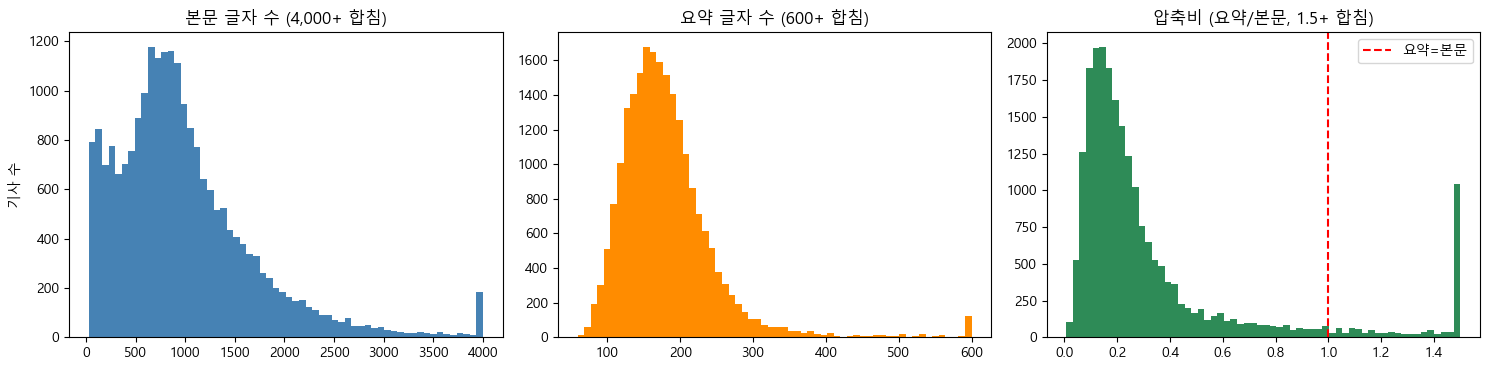

In [2]:
# ============================================================
# [01-2] 본문·요약 길이 분포
#   출력: figures/01-2_length_distribution.png, outputs/01-2_length_stats.csv
# ============================================================
for df in raw.values():
    df["doc_len"] = df["document"].str.len()
    df["sum_len"] = df["summary"].str.len()
    df["doc_words"] = df["document"].str.split().str.len()
    df["sum_words"] = df["summary"].str.split().str.len()
    df["ratio"] = df["sum_len"] / df["doc_len"]

tr = raw["train"]
stats = tr[["doc_len", "sum_len", "doc_words", "sum_words", "ratio"]].describe(percentiles=[.25, .5, .75, .95]).T.round(2)
print("=" * 70); print("[train 길이 통계]"); print("=" * 70)
print(stats[["mean", "25%", "50%", "75%", "95%", "max"]].to_string())

print("\n[길이 이상 (train)]")
print(f"  본문 100자 미만          : {(tr['doc_len'] < 100).sum():>5}건  (사진 기사 의심)")
print(f"  요약이 본문보다 김       : {(tr['ratio'] >= 1).sum():>5}건  (요약 실패)")
print(f"  요약 500자 초과          : {(tr['sum_len'] > 500).sum():>5}건  (반복 의심)")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(tr["doc_len"].clip(upper=4000), bins=60, color="steelblue")
ax[0].set_title("본문 글자 수 (4,000+ 합침)"); ax[0].set_ylabel("기사 수")
ax[1].hist(tr["sum_len"].clip(upper=600), bins=60, color="darkorange")
ax[1].set_title("요약 글자 수 (600+ 합침)")
ax[2].hist(tr["ratio"].clip(upper=1.5), bins=60, color="seagreen")
ax[2].axvline(1, color="red", ls="--", label="요약=본문"); ax[2].legend()
ax[2].set_title("압축비 (요약/본문, 1.5+ 합침)")
plt.tight_layout(); plt.savefig(FIG / "01-2_length_distribution.png", dpi=130); plt.show()
stats.to_csv(OUT / "01-2_length_stats.csv", encoding="utf-8-sig")


## 1-3. 중복·누수·노이즈 표시

**지우지 않고 표시만** 합니다. 어떤 기사를 뺄지는 다음 단계에서 정하고, 여기서는 문제가 어디에 얼마나 있는지만 기록합니다.

### 찾아낸 것

| 항목 | 건수 | 의미 |
|---|---|---|
| 학습 데이터 안 본문 중복 | 1,907 | 같은 본문이 최대 23번 |
| **평가 기사 중 학습에도 있던 것** | **321 (11.7%)** | 시험 문제를 미리 본 셈 |
| 검증 기사 중 학습에도 있던 것 | 311 | 설정을 고를 때도 답을 봄 |

**중복의 원인** — 통신사 사진 기사입니다. 같은 현장 사진 여러 장을 제목만 바꿔 올리는데, 크롤링하면 사진 설명 문장만 남아 본문이 똑같아집니다.
수박 기사는 23건이 64초 안에 게시됐고 제목은 6종류, 링크는 전부 달랐습니다. **링크로는 걸러낼 수 없습니다.**

### 정답 요약 노이즈 6항목 (학습의 12.8%)

| 검사 항목 | 기준 | 건수 |
|---|---|---|
| `flag_ratio` 길이 역전 | len(요약) ≥ len(본문) | 1,757 |
| `flag_ngram` 구절 반복 | 3단어 묶음 3회 이상 | 1,285 |
| `flag_consec` 단어 연속 | 연달아 같은 단어 | 1,008 |
| `flag_short` 짧은 본문 | 본문 100자 미만 | 876 |
| `flag_boiler` 광고 문구 | "제보를 기다", "재판매 및 DB" 등 | 276 |
| `flag_overlap` 겹침 낮음 | 요약 단어 중 본문에 있는 비율 50% 미만 | 28 |

가장 심한 사례는 본문 59자 기사에 요약이 908자였고, 기자 이름 "김승두"가 수백 번 반복돼 있었습니다.

[중복·누수·노이즈 표시 개수]
              train  val  test                    설명
dup_in_split   1907   62    51  스플릿 안 본문 중복(제거 대상 수)
in_train          0  311   321     train에도 있는 기사(누수)
in_val            0    0   101       val에도 있는 기사(누수)
flag_short      876   93    96            본문 100자 미만
flag_ratio     1757  199   198            요약이 본문보다 김
flag_ngram     1285  134   149         3단어 묶음 3회+ 반복
flag_consec    1008  118   140              같은 단어 연속
flag_overlap     28    0     1   요약 단어의 본문 포함 50% 미만
flag_boiler     276   27    31             요약에 광고 문구
is_noisy       2834  316   342          위 노이즈 중 하나라도

[train: 중복 여부 × 노이즈 비율]
       노이즈 없음(%)  노이즈 있음(%)
중복 아님       92.3        7.7
중복 기사       52.5       47.5


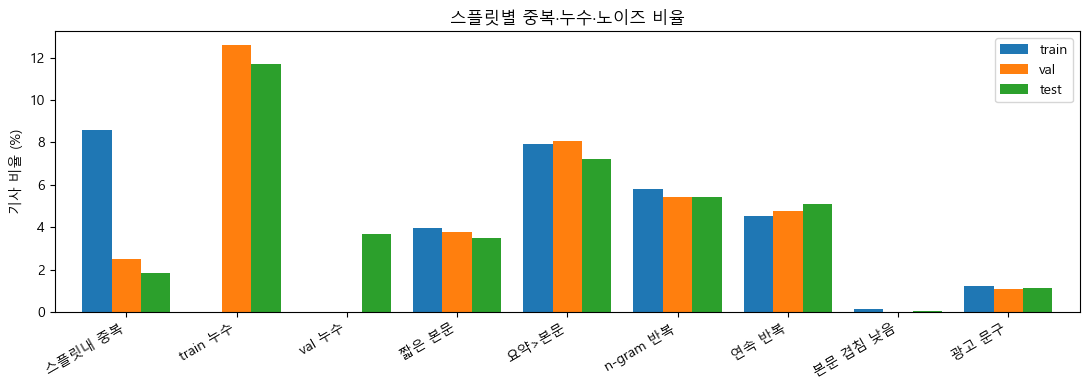


저장: outputs/01-3_flags_*.csv (행 순서 = 원본 행 순서)


In [3]:
# ============================================================
# [01-3] 중복·누수·노이즈 표시 (지우지 않고 표시만)
#   출력: outputs/01-3_flags_{split}.csv  (행별 표시 컬럼)
#         figures/01-3_issues.png
# ============================================================
def max_ngram_repeat(text, n=3):
    w = text.split(); g = [" ".join(w[i:i+n]) for i in range(len(w) - n + 1)]
    return Counter(g).most_common(1)[0][1] if g else 0

def consecutive_repeat(text):
    w = text.split(); return any(w[i] == w[i+1] for i in range(len(w) - 1))

def overlap_ratio(doc, summ):
    d = set(doc.split()); s = summ.split()
    return sum(x in d for x in s) / max(len(s), 1)

train_docs = set(raw["train"]["document"])
val_docs   = set(raw["val"]["document"])

for k, df in raw.items():
    # 중복·누수 (본문 완전 일치 기준)
    df["dup_in_split"]  = df.duplicated("document", keep="first")             # 같은 스플릿 안 중복 (첫 건 제외)
    df["in_train"]      = df["document"].isin(train_docs) if k != "train" else False
    df["in_val"]        = df["document"].isin(val_docs)   if k == "test"   else False
    # 정답 요약 노이즈
    df["flag_short"]    = df["doc_len"] < 100
    df["flag_ratio"]    = df["ratio"] >= 1.0
    df["flag_ngram"]    = df["summary"].apply(max_ngram_repeat) >= 3
    df["flag_consec"]   = df["summary"].apply(consecutive_repeat)
    df["flag_overlap"]  = df.apply(lambda r: overlap_ratio(r["document"], r["summary"]), axis=1) < 0.5
    df["flag_boiler"]   = df["summary"].str.contains("newsis|제보를 기다|반영하겠습니다|재판매 및 DB", regex=True)
    df["is_noisy"]      = df[["flag_short", "flag_ratio", "flag_ngram", "flag_consec", "flag_overlap", "flag_boiler"]].any(axis=1)

FLAGS = ["dup_in_split", "in_train", "in_val", "flag_short", "flag_ratio", "flag_ngram",
         "flag_consec", "flag_overlap", "flag_boiler", "is_noisy"]
table = pd.DataFrame({k: df[FLAGS].sum() for k, df in raw.items()})
table["설명"] = ["스플릿 안 본문 중복(제거 대상 수)", "train에도 있는 기사(누수)", "val에도 있는 기사(누수)",
               "본문 100자 미만", "요약이 본문보다 김", "3단어 묶음 3회+ 반복", "같은 단어 연속",
               "요약 단어의 본문 포함 50% 미만", "요약에 광고 문구", "위 노이즈 중 하나라도"]
print("=" * 70); print("[중복·누수·노이즈 표시 개수]"); print("=" * 70)
print(table.to_string())

# 중복 기사에 노이즈가 몰려 있는지
tr = raw["train"]
dup_any = tr.duplicated("document", keep=False)
ct = pd.crosstab(dup_any, tr["is_noisy"], normalize="index").mul(100).round(1)
ct.index = ["중복 아님", "중복 기사"]; ct.columns = ["노이즈 없음(%)", "노이즈 있음(%)"]
print("\n[train: 중복 여부 × 노이즈 비율]"); print(ct.to_string())

# 그래프: 스플릿별 문제 비율
fig, ax = plt.subplots(figsize=(11, 4))
pct = pd.DataFrame({k: df[FLAGS[:-1]].mean().mul(100) for k, df in raw.items()})
pct.plot.bar(ax=ax, width=0.8)
ax.set_ylabel("기사 비율 (%)"); ax.set_title("스플릿별 중복·누수·노이즈 비율")
ax.set_xticklabels(["스플릿내 중복", "train 누수", "val 누수", "짧은 본문", "요약>본문", "n-gram 반복",
                    "연속 반복", "본문 겹침 낮음", "광고 문구"], rotation=30, ha="right")
plt.tight_layout(); plt.savefig(FIG / "01-3_issues.png", dpi=130); plt.show()

for k, df in raw.items():
    df[["split"] + FLAGS].to_csv(OUT / f"01-3_flags_{k}.csv", index=True, encoding="utf-8-sig")
print("\n저장: outputs/01-3_flags_*.csv (행 순서 = 원본 행 순서)")


## 1-4. 핵심 발견 — 정답 요약은 AI가 만든 것으로 보인다

증거 네 가지를 찾았습니다. (계산 과정은 부록 참고)

**① 512토큰 경계**

긴 기사(1,022토큰 초과)에서 요약에 쓰인 표현이 본문의 어느 위치에서 왔는지 추적한 결과:

```
95% 지점 → 506 토큰
99% 지점 → 510 토큰     ← KoBART 입력 한계 512(특수토큰 2개 제외 = 510)와 정확히 일치
본문 60% 이후 구간에서 온 표현 → 0.0%
```

다른 토크나이저 기준으로는 경계가 맞지 않습니다 (KoGPT2 540, KoELECTRA 645).

**② 앞부분에 민감** — 광고 문구·기자 표기를 제거하면 본문이 같아지는 기사 중 **150쌍**에서 요약 내용이 서로 달랐습니다.
"KBS 춘천 앵커"와 "KBS 강릉 앵커" 한 단어 차이로 요약 전체가 바뀌었습니다.

**③ 뒷부분에 둔감** — 기사 끝 문장(사진 설명)만 다른 203쌍은 요약이 글자까지 완전히 동일했습니다.

**④ 결정적** — 본문이 같으면 요약이 항상 같았습니다(예외 0건). 사람이 두 번 쓰면 조금씩 달라집니다.

### 이 발견이 이후 모든 해석의 기준이 됩니다

- 기사 뒷부분 내용은 정답에 반영되지 않았습니다 → 입력을 512보다 늘려도 의미가 없습니다
- 정답에 오류(반복·깨진 단어·광고 문구)가 있습니다 → 모델이 따라 배울 위험이 있습니다
- **ROUGE가 높다는 것은 "정답 모델의 출력을 잘 흉내 냈다"는 뜻이지 "좋은 요약"이라는 뜻이 아닙니다**

## 1-5. 토큰화 · 임베딩 분석 — 공통 설정

교수님 요구사항의 **토큰화 선택 근거**와 **임베딩 흐름**을 코드와 출력으로 확인합니다. (`02b_tokenize_embedding.ipynb`, 학습 없음)

In [4]:
# ============================================================
# [02b-0] 공통 설정 · 데이터 불러오기
# ============================================================
import os, re, time
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import torch
from transformers import PreTrainedTokenizerFast, AutoTokenizer

ROOT = Path(os.environ.get("NS_ROOT", Path.home() / "Documents" / "news_summary_v2"))   # ← 다르면 수정
RAW, OUT = ROOT / "data" / "raw", ROOT / "outputs"
OUT.mkdir(exist_ok=True)

train = pd.read_csv(RAW / "train.csv")
docs = train["document"].astype(str).tolist()
sums = train["summary"].astype(str).tolist()
print(f"train {len(train):,}건 | 본문 평균 {np.mean([len(d) for d in docs]):,.0f}자 · 중앙값 {np.median([len(d) for d in docs]):,.0f}자")

train 22,194건 | 본문 평균 999자 · 중앙값 854자


## 1-6. 토크나이저 3종 비교 (train 22,194건 전수)

| 항목 | KoBART (BPE) | KoGPT2 (BPE) | KoELECTRA (WordPiece) |
|---|---|---|---|
| 평균 토큰 | **418.1** | 422.7 | 500.0 |
| 글자/토큰 (공백 제외) | **1.83** | 1.82 | 1.53 |
| 미등록 비율 | **0.00%** | 0.03% | 0.03% |
| 512 초과 | 27.5% | 28.1% | 37.6% |
| 예시 문장 토큰 수 | **8** | 9 | 12 |

- KoBART가 같은 글을 **가장 적은 토큰으로, 모르는 글자 없이** 표현합니다.
- KoELECTRA는 같은 기사를 약 20% 더 많은 토큰으로 쪼개 512 안에 담기는 내용이 가장 적습니다.
- **512 초과 27.5%**는 조원 결과(원현 27.3%, 태경 27.5%)와 일치합니다.

> **정정** — 이전 기록의 "512 초과 4.4%"는 잘못된 값입니다. 전수 계산 결과 **1024 초과가 4.1%**로, 두 기준을 혼동했을 가능성이 큽니다.
> 이전 기록의 "글자/토큰 2.40"은 공백 포함 기준으로 보이며, 이 표는 공백 제외 기준입니다. 순위(KoBART ≥ KoGPT2 > KoELECTRA)는 같습니다.

In [6]:
# ============================================================
# [02b-1] 토크나이저 3종 비교 (train 전수)
#   출력: outputs/02b-1_tokenizer_compare.csv
# ============================================================
TOKS = {
    "KoBART (BPE)":         PreTrainedTokenizerFast.from_pretrained("gogamza/kobart-base-v2"),
    "KoGPT2 (BPE)":         PreTrainedTokenizerFast.from_pretrained("skt/kogpt2-base-v2",
                                bos_token="</s>", eos_token="</s>", unk_token="<unk>",
                                pad_token="<pad>", mask_token="<mask>"),
    "KoELECTRA (WordPiece)": AutoTokenizer.from_pretrained("monologg/koelectra-base-v3-discriminator"),
}

n_chars = np.array([len(d.replace(" ", "")) for d in docs])       # 공백 제외 글자 수
rows, LENS = [], {}
for name, tk in TOKS.items():
    t0 = time.time()
    ids = tk(docs, add_special_tokens=False)["input_ids"]
    L = np.array([len(x) for x in ids])
    unk = tk.unk_token_id
    n_unk = sum(sum(1 for i in x if i == unk) for x in ids) if unk is not None else 0
    LENS[name] = L
    rows.append({
        "토크나이저": name,
        "어휘 크기": tk.vocab_size,
        "평균 토큰": round(L.mean(), 1),
        "중앙값": int(np.median(L)),
        "95% 지점": int(np.percentile(L, 95)),
        "글자/토큰": round(n_chars.sum() / L.sum(), 2),
        "미등록 비율(%)": round(n_unk / L.sum() * 100, 3),
        "512 초과(%)": round((L > 512).mean() * 100, 1),
        "1024 초과(%)": round((L > 1024).mean() * 100, 1),
        "소요(초)": round(time.time() - t0, 1),
    })

cmp = pd.DataFrame(rows).set_index("토크나이저")
cmp.to_csv(OUT / "02b-1_tokenizer_compare.csv", encoding="utf-8-sig")
print("=" * 100); print("[02b-1] 토크나이저 비교 (train 본문 22,194건, 특수 토큰 제외)"); print("=" * 100)
print(cmp.to_string())

# 같은 문장 예시
ex = "정부가 반도체 수출 지원을 확대한다고 밝혔다."
print("\n[같은 문장을 자른 결과]")
for name, tk in TOKS.items():
    toks = tk.tokenize(ex)
    print(f"  {name:<22} {len(toks):>2}개 | {' / '.join(toks)}")

You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
c:\Users\wm032\Documents\news_summary\.venv\Lib\site-packages\transformers\tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(
The tokenizer class you load from this checkpoint is not the same type as the class this function is called from. It may result in unexpected tokenization. 
The tokenizer class you load from this checkpoint is 'GPT2Tokenizer'. 
The class this function is called from is 'PreTrainedTokenizerFast'.
Token indices sequence length is longer than the specified maximum sequence length for this model (840 > 512). Running this sequence throug

[02b-1] 토크나이저 비교 (train 본문 22,194건, 특수 토큰 제외)
                       어휘 크기  평균 토큰  중앙값  95% 지점  글자/토큰  미등록 비율(%)  512 초과(%)  1024 초과(%)  소요(초)
토크나이저                                                                                           
KoBART (BPE)           30000  418.1  357     970   1.83       0.00       27.5         4.1    5.1
KoGPT2 (BPE)           51200  422.7  361     977   1.82       0.03       28.1         4.2    4.6
KoELECTRA (WordPiece)  35000  500.0  426    1161   1.53       0.03       37.6         7.6    4.6

[같은 문장을 자른 결과]
  KoBART (BPE)            8개 | ▁정부가 / ▁반도체 / ▁수출 / ▁지원을 / ▁확대 / 한다고 / ▁밝혔 / 다.
  KoGPT2 (BPE)            9개 | ▁정부가 / ▁반도체 / ▁수출 / ▁지원을 / ▁확 / 대한 / 다고 / ▁밝혔 / 다.
  KoELECTRA (WordPiece)  12개 | 정부 / ##가 / 반도체 / 수출 / 지원 / ##을 / 확대 / ##한다 / ##고 / 밝혔 / ##다 / .


In [7]:
# ============================================================
# [02b-6] 라벨(정답 요약) 길이 — 출력 길이 160 근거 확인
# ============================================================
tk = TOKS["KoBART (BPE)"]
lab_len = np.array([len(x) for x in tk(sums, add_special_tokens=False)["input_ids"]])

print("=" * 70); print("[02b-6] 라벨 길이 (KoBART 토큰, train 전수)"); print("=" * 70)
print(f"평균 {lab_len.mean():.1f} · 중앙값 {np.median(lab_len):.0f}")
for q in [90, 95, 99]:
    print(f"{q}% 지점: {np.percentile(lab_len, q):.0f}토큰")
over = lab_len > 160
print(f"\n160 초과: {over.sum():,}건 ({over.mean()*100:.1f}%)")

# 160을 넘는 라벨이 정말 망가진 라벨인지 확인 (01-3 노이즈 표시와 대조)
flags = pd.read_csv(OUT / "01-3_flags_train.csv", index_col=0)
NOISE = ["flag_short", "flag_ratio", "flag_ngram", "flag_consec", "flag_overlap", "flag_boiler"]
noisy = flags[NOISE].any(axis=1).values
print(f"160 초과 라벨 중 노이즈 표시된 비율: {noisy[over].mean()*100:.1f}%")
print(f"160 이하 라벨 중 노이즈 표시된 비율: {noisy[~over].mean()*100:.1f}%")

[02b-6] 라벨 길이 (KoBART 토큰, train 전수)
평균 78.3 · 중앙값 72
90% 지점: 107토큰
95% 지점: 123토큰
99% 지점: 213토큰

160 초과: 409건 (1.8%)
160 초과 라벨 중 노이즈 표시된 비율: 80.9%
160 이하 라벨 중 노이즈 표시된 비율: 11.5%


## 1-7. 입력 길이 근거 — 512로 잘라도 정답 단어가 남는가

512 토큰을 넘는 기사 6,108건만 대상으로, 정답 요약의 어절이 본문에 등장하는 비율을 비교했습니다.

| 조건 | 평균 보존율 |
|---|---|
| 본문 전체 | 0.909 |
| 앞 512 토큰 | 0.906 |
| **차이** | **0.003** |

본문의 평균 **29%가 잘리는데도 정답 단어는 0.003만 줄어듭니다.** 잘린 뒷부분이 정답 요약에 거의 쓰이지 않았다는 뜻이며, 1-4의 "512토큰 경계" 증거와 일치합니다. → **입력 길이 512 확정 근거**

In [3]:
# ============================================================
# [02b-2] 512 토큰 절단 시 정답 단어 보존율 (512 초과 기사 전수)
#   출력: outputs/02b-2_truncation_coverage.csv
# ============================================================
tk = TOKS["KoBART (BPE)"]
L = LENS["KoBART (BPE)"]
long_idx = np.where(L > 512)[0]
print(f"512 토큰 초과 기사: {len(long_idx):,}건 ({len(long_idx)/len(docs)*100:.1f}%)")

def coverage(summary, text):
    """정답 요약 어절 중 text 안에 문자열로 등장하는 비율"""
    words = [w for w in summary.split() if len(w) >= 2]
    return np.mean([w in text for w in words]) if words else np.nan

full_cov, cut_cov, lost_frac = [], [], []
for i in long_idx:
    ids = tk(docs[i], add_special_tokens=False)["input_ids"]
    head = tk.decode(ids[:512])
    full_cov.append(coverage(sums[i], docs[i]))
    cut_cov.append(coverage(sums[i], head))
    lost_frac.append(1 - len(head) / len(docs[i]))

res = pd.DataFrame({"본문 전체": full_cov, "앞 512 토큰": cut_cov, "잘린 본문 비율": lost_frac})
summary_tbl = pd.DataFrame({
    "평균": res.mean().round(3),
    "중앙값": res.median().round(3),
})
res.to_csv(OUT / "02b-2_truncation_coverage.csv", index=False, encoding="utf-8-sig")

print("=" * 70); print("[02b-2] 정답 단어 보존율 (512 초과 기사만)"); print("=" * 70)
print(summary_tbl.to_string())
gap = summary_tbl.loc["본문 전체", "평균"] - summary_tbl.loc["앞 512 토큰", "평균"]
print(f"\n→ 본문의 평균 {summary_tbl.loc['잘린 본문 비율','평균']*100:.0f}%가 잘려도, "
      f"정답 단어 보존율 차이는 {gap:.3f}")

512 토큰 초과 기사: 6,108건 (27.5%)
[02b-2] 정답 단어 보존율 (512 초과 기사만)
             평균    중앙값
본문 전체     0.909  0.921
앞 512 토큰  0.906  0.921
잘린 본문 비율  0.292  0.267

→ 본문의 평균 29%가 잘려도, 정답 단어 보존율 차이는 0.003


## 1-8. 어휘 규모와 임베딩 흐름

### 어휘 규모 — 어절 vs BPE

| 단위 | 어휘 수 |
|---|---|
| 어절 (전체) | 486,391 |
| 어절 (5회 이상) | 100,915 |
| KoBART BPE (실제 사용) | **16,995** |

"수출"로 시작하는 어절만 **434종**(수출, 수출이, 수출은, 수출액은 …)입니다. 어절 단위 고정 임베딩(Word2Vec)은 이를 모두 다른 단어로 다룹니다.
BPE는 대부분 `▁수출` + 조사로 나누고, "수출이"처럼 아주 자주 쓰이는 형태만 한 토큰으로 둡니다.

In [4]:
# ============================================================
# [02b-3] 어휘 규모 비교 (train 본문 전수)
# ============================================================
eojeol = Counter(w for d in docs for w in d.split())
bpe_ids = Counter(i for x in TOKS["KoBART (BPE)"](docs, add_special_tokens=False)["input_ids"] for i in x)

vocab = pd.DataFrame({
    "단위": ["어절 (전체)", "어절 (5회 이상 등장)", "KoBART BPE (실제 사용된 토큰)", "KoBART BPE (사전 크기)"],
    "어휘 수": [len(eojeol), sum(1 for c in eojeol.values() if c >= 5), len(bpe_ids), TOKS["KoBART (BPE)"].vocab_size],
})
print("=" * 70); print("[02b-3] 어휘 규모"); print("=" * 70)
print(vocab.to_string(index=False))

stem = "수출"
forms = sorted([w for w in eojeol if w.startswith(stem)], key=lambda w: -eojeol[w])
print(f"\n'{stem}'로 시작하는 어절: {len(forms):,}종 → 예) {', '.join(forms[:12])} …")
print(f"KoBART는 '{stem}' 하나로 처리: {TOKS['KoBART (BPE)'].tokenize('수출을 수출이 수출로')}")

[02b-3] 어휘 규모
                    단위   어휘 수
               어절 (전체) 486391
         어절 (5회 이상 등장) 100915
KoBART BPE (실제 사용된 토큰)  16995
    KoBART BPE (사전 크기)  30000

'수출'로 시작하는 어절: 434종 → 예) 수출, 수출이, 수출은, 수출액은, 수출입, 수출을, 수출액이, 수출규제, 수출액, 수출기업, 수출의, 수출에 …
KoBART는 '수출' 하나로 처리: ['▁수출', '을', '▁수출이', '▁수출', '로']


### 임베딩 흐름 — 같은 단어, 다른 문맥

| 단어 | 임베딩 층 유사도 | 인코더 출력 유사도 |
|---|---|---|
| 배 (선박 / 과일) | 1.0 | 0.837 |
| 수출 | 1.0 | 0.642 |
| 금리 | 1.0 | 0.510 |

임베딩 층에서는 같은 토큰이 문맥과 무관하게 **같은 벡터**(1.0)이지만, 인코더를 거치면 주변 단어에 따라 **다른 벡터**가 됩니다.
shape 흐름: `input_ids (1, 7)` → 임베딩 층 `(1, 7, 768)` → 인코더 출력 `(1, 7, 768)`. (표현 방식의 확인이며 성능 점수가 아닙니다)

In [5]:
# ============================================================
# [02b-4] 임베딩 층 vs 인코더 출력 — 같은 단어의 문맥별 유사도
# ============================================================
from transformers import BartModel

tk = TOKS["KoBART (BPE)"]
bart = BartModel.from_pretrained("gogamza/kobart-base-v2").eval()

def word_vectors(sentence, word):
    """sentence 안에서 word에 해당하는 토큰들의 (임베딩 층, 인코더 출력) 평균 벡터"""
    enc = tk(sentence, return_tensors="pt", return_offsets_mapping=True, return_token_type_ids=False)
    offs = enc.pop("offset_mapping")[0].tolist()
    s = sentence.index(word); e = s + len(word)
    pos = [k for k, (a, b) in enumerate(offs) if a < e and b > s]
    with torch.no_grad():
        emb = bart.shared(enc["input_ids"])                                   # 임베딩 층
        out = bart.encoder(input_ids=enc["input_ids"],
                           attention_mask=enc["attention_mask"]).last_hidden_state   # 인코더 출력
    toks = [tk.convert_ids_to_tokens(int(enc["input_ids"][0, k])) for k in pos]
    return emb[0, pos].mean(0), out[0, pos].mean(0), toks, tuple(enc["input_ids"].shape), tuple(out.shape)

cos = torch.nn.functional.cosine_similarity
PAIRS = [
    ("배",   "배 두 척이 항구에 들어왔다.",           "배 두 개를 깎아 먹었다."),
    ("수출", "정부가 반도체 수출 지원을 확대했다.",   "중동 수출 길이 막혀 농가가 울상이다."),
    ("금리", "한국은행이 기준 금리 인상을 결정했다.", "예금 금리 비교 서비스가 인기를 끌었다."),
]
rows = []
for word, s1, s2 in PAIRS:
    e1, h1, t1, in_shape, out_shape = word_vectors(s1, word)
    e2, h2, t2, _, _ = word_vectors(s2, word)
    rows.append({"단어": word, "토큰": " ".join(t1) + (" / " + " ".join(t2) if t1 != t2 else ""),
                 "임베딩 층 유사도": round(cos(e1, e2, dim=0).item(), 4),
                 "인코더 출력 유사도": round(cos(h1, h2, dim=0).item(), 4)})
emb_tbl = pd.DataFrame(rows)
emb_tbl.to_csv(OUT / "02b-4_context_embedding.csv", index=False, encoding="utf-8-sig")

print("=" * 80); print("[02b-4] 같은 단어의 문맥별 코사인 유사도"); print("=" * 80)
print(emb_tbl.to_string(index=False))
print(f"\n[shape 흐름]  input_ids {in_shape} → 임베딩 층 (1, 토큰 수, {bart.config.d_model}) → 인코더 출력 {out_shape}")

You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


[02b-4] 같은 단어의 문맥별 코사인 유사도
단어  토큰  임베딩 층 유사도  인코더 출력 유사도
 배  ▁배        1.0      0.8371
수출 ▁수출        1.0      0.6417
금리 ▁금리        1.0      0.5096

[shape 흐름]  input_ids (1, 7) → 임베딩 층 (1, 토큰 수, 768) → 인코더 출력 (1, 7, 768)


---
# 2. 데이터 버전 생성

전처리를 단계적으로 적용해서, 각 단계가 무엇을 바꾸는지 측정할 수 있게 했습니다.

| 버전 | 학습 | 처리 내용 |
|---|---|---|
| **v0** | 22,194 | 원본 그대로 (기준점) |
| **v1** | 19,815 | 본문 완전 일치 중복 제거 + 평가·검증과 겹치는 기사 제거 |
| **v2** | 18,150 | v1 + 정답 노이즈 6항목 중 하나라도 해당하면 기사 삭제 |

### 두 가지 원칙

1. **평가 데이터 2,740건은 한 글자도 수정하지 않습니다.** 대신 `in_train`·`is_noisy` 표시를 붙여 나눠 볼 수 있게 합니다.
2. **정답 요약을 고치지 않습니다.** 전부 기사 단위 삭제입니다. "정답을 손댔다"는 논란을 피하기 위해서입니다.

## 2-1. v0 / v1 / test 생성

In [1]:
# ============================================================
# [02-1] 데이터 버전 생성
#   v0 : 원본 그대로 (press 공백만 정리)
#   v1 : 본문 완전 일치 기준 — 스플릿 안 중복 1건만 남김 + train/val에서 test·val과 겹치는 기사 제거
#   test : 모든 버전 공통, 원본 그대로 + 분석용 표시 컬럼 (in_train, in_val, is_noisy)
#   입력: data/raw/*.csv, outputs/01-3_flags_*.csv
#   출력: data/processed/{v0,v1}_{train,val}.csv, test.csv, versions.csv
# ============================================================
import os
from pathlib import Path
import pandas as pd

ROOT = Path.home() / "Documents" / "news_summary_v2"     # ← 조원은 자기 경로로
RAW, PROC, OUT = ROOT / "data/raw", ROOT / "data/processed", ROOT / "outputs"
COLS = ["date", "category", "press", "title", "document", "link", "summary"]

raw = {k: pd.read_csv(RAW / f) for k, f in
       [("train", "train.csv"), ("val", "validation.csv"), ("test", "test.csv")]}
flags = {k: pd.read_csv(OUT / f"01-3_flags_{k}.csv", index_col=0) for k in raw}
for k in raw:
    raw[k]["press"] = raw[k]["press"].str.strip()
    assert len(raw[k]) == len(flags[k]), f"{k}: 표시 파일과 행 수가 다릅니다. 01 노트북을 다시 실행하세요."

versions = []   # 버전 정의표

# ---------- test: 공통 고정 ----------
test = raw["test"][COLS].copy()
test["in_train"] = flags["test"]["in_train"].values
test["in_val"]   = flags["test"]["in_val"].values
test["is_noisy"] = flags["test"]["is_noisy"].values
test.to_csv(PROC / "test.csv", index=False, encoding="utf-8-sig")

# ---------- v0 ----------
raw["train"][COLS].to_csv(PROC / "v0_train.csv", index=False, encoding="utf-8-sig")
raw["val"][COLS].to_csv(PROC / "v0_val.csv", index=False, encoding="utf-8-sig")
versions.append({"version": "v0", "train": len(raw["train"]), "val": len(raw["val"]), "test": len(test),
                 "정의": "원본 그대로", "제거 기준": "없음"})

# ---------- v1 ----------
test_docs = set(raw["test"]["document"])
val_docs  = set(raw["val"]["document"])

v1_train = raw["train"].drop_duplicates("document", keep="first")
n_dup = len(raw["train"]) - len(v1_train)
v1_train = v1_train[~v1_train["document"].isin(test_docs | val_docs)]
n_leak_tr = len(raw["train"]) - n_dup - len(v1_train)

v1_val = raw["val"].drop_duplicates("document", keep="first")
n_dup_val = len(raw["val"]) - len(v1_val)
v1_val = v1_val[~v1_val["document"].isin(test_docs)]
n_leak_val = len(raw["val"]) - n_dup_val - len(v1_val)

v1_train[COLS].to_csv(PROC / "v1_train.csv", index=False, encoding="utf-8-sig")
v1_val[COLS].to_csv(PROC / "v1_val.csv", index=False, encoding="utf-8-sig")
versions.append({"version": "v1", "train": len(v1_train), "val": len(v1_val), "test": len(test),
                 "정의": "완전 중복·누수 제거",
                 "제거 기준": f"train: 내부중복 {n_dup} + val/test 겹침 {n_leak_tr} | val: 내부중복 {n_dup_val} + test 겹침 {n_leak_val}"})

ver_df = pd.DataFrame(versions)
ver_df.to_csv(PROC / "versions.csv", index=False, encoding="utf-8-sig")

print("=" * 70); print("[데이터 버전]"); print("=" * 70)
print(ver_df.to_string(index=False))
print(f"\ntest 표시: in_train {test['in_train'].sum()}건 | in_val {test['in_val'].sum()}건 | is_noisy {test['is_noisy'].sum()}건")
print("\n저장:", sorted(p.name for p in PROC.iterdir()))


[데이터 버전]
version  train  val  test          정의                                                          제거 기준
     v0  22194 2466  2740      원본 그대로                                                             없음
     v1  19815 2325  2740 완전 중복·누수 제거 train: 내부중복 1907 + val/test 겹침 472 | val: 내부중복 62 + test 겹침 79

test 표시: in_train 321건 | in_val 101건 | is_noisy 342건

저장: ['test.csv', 'v0_train.csv', 'v0_val.csv', 'v1_train.csv', 'v1_val.csv', 'versions.csv']


## 2-2. v2 생성 (노이즈 6항목 제거)

항목별 해당 건수의 합(3,744)이 실제 제거 수(1,665)보다 훨씬 큽니다. **항목끼리 많이 겹친다**는 뜻이며,
이 겹침 구조가 뒤에서 중요해집니다(8장).

In [2]:
# ============================================================
# [02-2] v2 생성: v1 + 정답 노이즈 전부 제거
#   노이즈 6항목(01-3에서 표시): 짧은 본문, 요약>본문, n-gram 반복, 연속 반복, 본문 겹침 낮음, 광고 문구
#   입력: data/processed/v1_train.csv, v1_val.csv, outputs/01-3_flags_{train,val}.csv, data/raw/*.csv
#   출력: data/processed/v2_train.csv, v2_val.csv, versions.csv(갱신)
# ============================================================
raw_tr  = pd.read_csv(RAW / "train.csv");      raw_va = pd.read_csv(RAW / "validation.csv")
flag_tr = pd.read_csv(OUT / "01-3_flags_train.csv", index_col=0)
flag_va = pd.read_csv(OUT / "01-3_flags_val.csv",   index_col=0)
v1_tr   = pd.read_csv(PROC / "v1_train.csv");   v1_va = pd.read_csv(PROC / "v1_val.csv")

NOISE = ["flag_short", "flag_ratio", "flag_ngram", "flag_consec", "flag_overlap", "flag_boiler"]

def drop_noisy(v1_df, raw_df, flag_df):
    """v1 행을 원본 행과 (document, summary)로 대응시켜 노이즈 표시된 것을 제거"""
    noisy_keys = set(zip(raw_df.loc[flag_df[NOISE].any(axis=1), "document"],
                         raw_df.loc[flag_df[NOISE].any(axis=1), "summary"]))
    keep = ~pd.Series([(d, s) in noisy_keys for d, s in zip(v1_df["document"], v1_df["summary"])])
    return v1_df[keep.values], (~keep).sum()

v2_tr, n_tr = drop_noisy(v1_tr, raw_tr, flag_tr)
v2_va, n_va = drop_noisy(v1_va, raw_va, flag_va)
v2_tr.to_csv(PROC / "v2_train.csv", index=False, encoding="utf-8-sig")
v2_va.to_csv(PROC / "v2_val.csv",   index=False, encoding="utf-8-sig")

# 항목별로 v1에서 몇 건이 해당했는지 (겹침 포함)
raw_flag = raw_tr.assign(**{c: flag_tr[c].values for c in NOISE})
v1_keys  = set(zip(v1_tr["document"], v1_tr["summary"]))
in_v1    = pd.Series([(d, s) in v1_keys for d, s in zip(raw_flag["document"], raw_flag["summary"])])
per_item = raw_flag.loc[in_v1.values, NOISE].sum()

ver = pd.read_csv(PROC / "versions.csv")
ver = ver[ver["version"] != "v2"]
ver = pd.concat([ver, pd.DataFrame([{"version": "v2", "train": len(v2_tr), "val": len(v2_va), "test": ver["test"].iloc[0],
                 "정의": "v1 + 정답 노이즈 전부 제거",
                 "제거 기준": f"train {n_tr}건, val {n_va}건 (노이즈 6항목 중 하나라도 해당)"}])], ignore_index=True)
ver.to_csv(PROC / "versions.csv", index=False, encoding="utf-8-sig")

print("=" * 70); print("[v2 생성]"); print("=" * 70)
print(f"train: v1 {len(v1_tr):,} → v2 {len(v2_tr):,}  (제거 {n_tr:,})")
print(f"val  : v1 {len(v1_va):,} → v2 {len(v2_va):,}  (제거 {n_va:,})")
print("\n[v1 train 안에서 항목별 해당 건수 (서로 겹침)]")
for c, n in per_item.items(): print(f"  {c:<14} {n:>5}")
print("\n" + "=" * 70); print("[데이터 버전 전체]"); print("=" * 70)
print(ver.to_string(index=False))


[v2 생성]
train: v1 19,815 → v2 18,150  (제거 1,665)
val  : v1 2,325 → v2 2,084  (제거 241)

[v1 train 안에서 항목별 해당 건수 (서로 겹침)]
  flag_short       589
  flag_ratio      1185
  flag_ngram       924
  flag_consec      833
  flag_overlap      25
  flag_boiler      185

[데이터 버전 전체]
version  train  val  test                정의                                                          제거 기준
     v0  22194 2466  2740            원본 그대로                                                             없음
     v1  19815 2325  2740       완전 중복·누수 제거 train: 내부중복 1907 + val/test 겹침 472 | val: 내부중복 62 + test 겹침 79
     v2  18150 2084  2740 v1 + 정답 노이즈 전부 제거                      train 1665건, val 241건 (노이즈 6항목 중 하나라도 해당)


## 2-3. 노이즈 항목별 버전 (v2a / v2b / v2c)

v2는 6항목을 한꺼번에 뺐습니다. 어느 항목이 무엇을 담당했는지 분리하기 위해, v1에서 항목을 **하나씩만** 빼는 버전을 만듭니다.

| 버전 | 뺀 항목 | 제거 |
|---|---|---|
| v2a | 반복 2항목 (`flag_ngram` + `flag_consec`) | 1,224 |
| v2b | 길이 2항목 (`flag_short` + `flag_ratio`) | 857 |
| v2c | 광고 문구 (`flag_boiler`) | 113 |

### 항목 간 겹침에서 읽을 것

- **짧은 본문은 길이 역전의 부분집합**입니다 (402 중 393 = 98%). 본문이 100자 미만이면 요약이 더 긴 게 당연합니다.
- **길이 역전의 절반이 반복 기사**이기도 합니다 (848 중 432 = 51%). 요약이 길어지는 이유가 대개 반복이기 때문입니다.
- **광고 문구는 거의 독립적**입니다 (113건 중 다른 항목과 겹치는 게 최대 23건).

In [2]:
# ============================================================
# [06-1a] 항목별 조합 데이터 생성
#   v1에서 노이즈 항목을 하나씩만 제거 → v2(전부 제거)의 효과를 분해
#   v2a: 반복 2항목 (flag_ngram, flag_consec)
#   v2b: 길이 2항목 (flag_short, flag_ratio)
#   v2c: 광고 문구 (flag_boiler)
#   ※ flag_overlap(28건)은 단독 버전을 만들기엔 너무 적어 v2에만 포함
#   출력: data/processed/v2a_*, v2b_*, v2c_*, versions.csv 갱신
# ============================================================
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))
from common import *

RAW = ROOT / "data/raw"
COLS = ["date", "category", "press", "title", "document", "link", "summary"]
raw = {k: pd.read_csv(RAW / f) for k, f in [("train", "train.csv"), ("val", "validation.csv")]}
flags = {k: pd.read_csv(OUT / f"01-3_flags_{k}.csv", index_col=0) for k in raw}
for k in raw: raw[k]["press"] = raw[k]["press"].str.strip()

v1 = {"train": pd.read_csv(PROC / "v1_train.csv"), "val": pd.read_csv(PROC / "v1_val.csv")}

GROUPS = {
    "v2a": (["flag_ngram", "flag_consec"], "반복 2항목 제거"),
    "v2b": (["flag_short", "flag_ratio"],  "길이 2항목 제거 (짧은 본문·길이 역전)"),
    "v2c": (["flag_boiler"],               "광고 문구 제거"),
}

def drop_by(v1_df, raw_df, flag_df, cols):
    """v1 행을 (document, summary)로 원본과 대응시켜 해당 flag가 True인 것을 제거"""
    mask = flag_df[cols].any(axis=1)
    bad = set(zip(raw_df.loc[mask, "document"], raw_df.loc[mask, "summary"]))
    keep = pd.Series([(d, s) not in bad for d, s in zip(v1_df["document"], v1_df["summary"])])
    return v1_df[keep.values], (~keep).sum()

ver = pd.read_csv(PROC / "versions.csv")
ver = ver[~ver["version"].isin(GROUPS)]
rows = []
for name, (cols, desc) in GROUPS.items():
    tr, n_tr = drop_by(v1["train"], raw["train"], flags["train"], cols)
    va, n_va = drop_by(v1["val"],   raw["val"],   flags["val"],   cols)
    tr[COLS].to_csv(PROC / f"{name}_train.csv", index=False, encoding="utf-8-sig")
    va[COLS].to_csv(PROC / f"{name}_val.csv",   index=False, encoding="utf-8-sig")
    rows.append({"version": name, "train": len(tr), "val": len(va), "test": 2740,
                 "정의": f"v1 + {desc}", "제거 기준": f"train {n_tr}, val {n_va} ({'+'.join(cols)})"})
    print(f"{name}: train {len(v1['train']):,} → {len(tr):,} (제거 {n_tr:,}) | val {len(v1['val']):,} → {len(va):,}")

ver = pd.concat([ver, pd.DataFrame(rows)], ignore_index=True)
ver.to_csv(PROC / "versions.csv", index=False, encoding="utf-8-sig")

# 항목 간 겹침 확인 (v1 안에서)
v1_keys = set(zip(v1["train"]["document"], v1["train"]["summary"]))
# v1에 남은 기사 1건씩만 대응시킴 (중복 중복 계산 방지)
raw_tr = raw["train"].assign(**{c: flags["train"][c].values for c in NOISE})
raw_tr = raw_tr.drop_duplicates(subset=["document", "summary"], keep="first")
v1_keys = set(zip(v1["train"]["document"], v1["train"]["summary"]))
f = raw_tr[[(d, s) in v1_keys for d, s in zip(raw_tr["document"], raw_tr["summary"])]][NOISE]
NOISE = ["flag_short", "flag_ratio", "flag_ngram", "flag_consec", "flag_overlap", "flag_boiler"]
print("\n" + "=" * 70); print("[v1 train 안에서 항목 간 겹침]"); print("=" * 70)
co = f[NOISE].astype(int)
print((co.T @ co).to_string())
print(f"\n하나라도 해당: {f[NOISE].any(axis=1).sum():,}건 (v2에서 제거된 수와 일치해야 함)")

print("\n" + "=" * 70); print("[버전 정의 전체]"); print("=" * 70)
print(ver.to_string(index=False))

v2a: train 19,815 → 18,591 (제거 1,224) | val 2,325 → 2,158
v2b: train 19,815 → 18,958 (제거 857) | val 2,325 → 2,189
v2c: train 19,815 → 19,702 (제거 113) | val 2,325 → 2,303

[v1 train 안에서 항목 간 겹침]
              flag_short  flag_ratio  flag_ngram  flag_consec  flag_overlap  flag_boiler
flag_short           402         393         233          116             9            2
flag_ratio           393         848         432          192            10           23
flag_ngram           233         432         684          162            11           23
flag_consec          116         192         162          702            12           13
flag_overlap           9          10          11           12            19            0
flag_boiler            2          23          23           13             0          113

하나라도 해당: 1,665건 (v2에서 제거된 수와 일치해야 함)

[버전 정의 전체]
version  train  val  test                           정의                                                          제거 기준
     v0  22194 

## 2-4. 스플릿 비율 버전 (v2_s80 / v2_s70)

v2의 train+val을 합친 뒤 비율만 바꿔 다시 나눕니다. test는 고정입니다.

| 비율 | train | val |
|---|---|---|
| 90:10 (v2, 기존) | 18,150 | 2,084 |
| 80:20 (v2_s80) | 16,187 | 4,047 |
| 70:30 (v2_s70) | 14,163 | 6,071 |

In [15]:
# ============================================================
# [04-8] 스플릿 비율 데이터 생성
#   v2의 train+val을 합친 뒤 80:20, 70:30으로 다시 나눔
#   test 2,740건은 고정
#   출력: data/processed/v2_s80_{train,val}.csv, v2_s70_*.csv
# ============================================================
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))
from common import *

COLS = ["date", "category", "press", "title", "document", "link", "summary"]
tr = pd.read_csv(PROC / "v2_train.csv")
va = pd.read_csv(PROC / "v2_val.csv")
pool = pd.concat([tr, va], ignore_index=True).sample(frac=1, random_state=SEED).reset_index(drop=True)
print(f"v2 train {len(tr):,} + val {len(va):,} = 합계 {len(pool):,}")

ver = pd.read_csv(PROC / "versions.csv")
ver = ver[~ver["version"].isin(["v2_s80", "v2_s70"])]
rows = []
for name, ratio in [("v2_s80", 0.80), ("v2_s70", 0.70)]:
    n = int(len(pool) * ratio)
    t, v = pool.iloc[:n], pool.iloc[n:]
    t[COLS].to_csv(PROC / f"{name}_train.csv", index=False, encoding="utf-8-sig")
    v[COLS].to_csv(PROC / f"{name}_val.csv",   index=False, encoding="utf-8-sig")
    rows.append({"version": name, "train": len(t), "val": len(v), "test": 2740,
                 "정의": f"v2를 {int(ratio*100)}:{100-int(ratio*100)}로 재분할",
                 "제거 기준": "제거 없음. train/val 비율만 변경"})
    print(f"{name}: train {len(t):,} | val {len(v):,}")

ver = pd.concat([ver, pd.DataFrame(rows)], ignore_index=True)
ver.to_csv(PROC / "versions.csv", index=False, encoding="utf-8-sig")
print("\n현재 비율 (v2): train 18,150 | val 2,084  →  약 90:10")
print(ver.to_string(index=False))

v2 train 18,150 + val 2,084 = 합계 20,234
v2_s80: train 16,187 | val 4,047
v2_s70: train 14,163 | val 6,071

현재 비율 (v2): train 18,150 | val 2,084  →  약 90:10
version  train  val  test                           정의                                                          제거 기준
     v0  22194 2466  2740                       원본 그대로                                                             없음
     v1  19815 2325  2740                  완전 중복·누수 제거 train: 내부중복 1907 + val/test 겹침 472 | val: 내부중복 62 + test 겹침 79
     v2  18150 2084  2740            v1 + 정답 노이즈 전부 제거                      train 1665건, val 241건 (노이즈 6항목 중 하나라도 해당)
    v2a  18591 2158  2740               v1 + 반복 2항목 제거                   train 1224, val 167 (flag_ngram+flag_consec)
    v2b  18958 2189  2740 v1 + 길이 2항목 제거 (짧은 본문·길이 역전)                     train 857, val 136 (flag_short+flag_ratio)
    v2c  19702 2303  2740                v1 + 광고 문구 제거                                train 113, val 22 (flag_boiler)
 v2_s80  16187 404

---
# 3. 평가 체계와 베이스라인

모델을 만들기 **전에** 판단 기준을 정했습니다. 결과를 보고 기준을 정하면 유리한 지표를 고르게 되기 때문입니다.

## 3-1. 평가 함수와 지표 특성

### 함정 ① 기본 설정으로는 한국어가 0점

`rouge_score` 라이브러리를 기본 설정으로 쓰면 완전히 똑같은 한국어 문장도 0점이 나옵니다. 내부 토크나이저가 한글을 전부 제거하기 때문입니다.
형태소 분석기(kiwipiepy)를 연결해 해결했습니다.

| 사례 | 공백 단위 | 형태소 단위 |
|---|---|---|
| 완전히 같은 문장 | 1.000 | 1.000 |
| 조사만 다름 (정부가/정부는) | 0.750 | 0.875 |
| 표현만 바꿈 (확대한다/늘린다) | 0.750 | 0.800 |
| 내용이 완전히 다름 | 0.000 | **0.235** |

형태소 단위는 조사 차이에 관대하지만 무관한 문장에도 0.235의 바닥 점수가 깔립니다.
→ **형태소를 주 지표, 공백을 보조 지표로 병기**합니다.

### 함정 ② 망가진 정답을 따라 하면 점수가 오른다

```
원문  먹거리 물가 오름세가 지속 중인 4일 서울의 한 대형마트에서 시민들이 장을 보고 있다.
정답  4거리 먹거리 물가 오름세가 4일 서울의 서울의 서울의 서울의 한 대형마트에서…   ← 망가짐
모델  먹거리 물가 오름세가 지속 중인 4일 서울의 한 대형마트에서 시민들이 장을 보고 있다.  ← 정상
                                                          → ROUGE-L 0.038점
```

**모델 요약이 완벽한데 0.038점입니다.** 이런 기사가 평가 데이터의 **12.5%(342건)**입니다.
→ 이를 제외한 **`clean`** 지표와, 누수를 제외한 **`noleak`** 지표를 함께 봅니다.

In [1]:
# ============================================================
# [03-1] 평가 함수 불러오기 + 지표 특성 확인
#   - evaluate(): ROUGE-1/2/L 형태소(주)·공백(보조) + 길이·반복률·복사율  (정의는 notebooks/common.py)
#   - 이 셀은 지표가 어떤 성질을 갖는지 확인 (보고서 '지표 해석'용)
#   출력: outputs/03-1_tokenizer_compare.csv
# ============================================================
import sys; from pathlib import Path
sys.path.insert(0, str(Path.cwd()))   # notebooks 폴더에서 실행
from common import *

# ---------- 지표 특성 확인 (보고서 '지표 해석'용) ----------
cases = [("완전히 같음", "정부가 수출 지원을 확대한다", "정부가 수출 지원을 확대한다"),
         ("조사만 다름", "정부가 수출 지원을 확대한다", "정부는 수출 지원을 확대한다"),
         ("표현만 바꿈(뜻 같음)", "정부가 수출 지원을 확대한다", "정부가 수출 지원을 늘린다"),
         ("내용이 다름", "정부가 수출 지원을 확대한다", "코스피가 전일 대비 상승 마감했다")]
rows = []
for name, ref, pred in cases:
    m = SCORERS["morph"].score(ref, pred); s = SCORERS["space"].score(ref, pred)
    rows.append({"사례": name, "형태소 R-L": round(m["rougeL"].fmeasure, 3), "공백 R-L": round(s["rougeL"].fmeasure, 3)})
cmp = pd.DataFrame(rows)
print("=" * 70); print("[토큰화 방식별 ROUGE-L 특성]"); print("=" * 70)
print(cmp.to_string(index=False))
print("\n→ 형태소: 조사 차이에 관대하지만 무관한 문장에도 바닥 점수가 있음")
print("→ 공백  : 무관한 문장은 0이지만 조사 하나에 크게 감점")
print("→ 둘 다 '뜻이 같은 다른 표현'은 감점 (ROUGE 공통 한계)")
cmp.to_csv(OUT / "03-1_tokenizer_compare.csv", index=False, encoding="utf-8-sig")


[토큰화 방식별 ROUGE-L 특성]
          사례  형태소 R-L  공백 R-L
      완전히 같음    1.000    1.00
      조사만 다름    0.875    0.75
표현만 바꿈(뜻 같음)    0.800    0.75
      내용이 다름    0.235    0.00

→ 형태소: 조사 차이에 관대하지만 무관한 문장에도 바닥 점수가 있음
→ 공백  : 무관한 문장은 0이지만 조사 하나에 크게 감점
→ 둘 다 '뜻이 같은 다른 표현'은 감점 (ROUGE 공통 한계)


## 3-2. 베이스라인 — 기사 앞 N단어 자르기

학습 없이 가장 단순한 방법으로 어디까지 되는지 먼저 확인합니다. 이것보다 못하면 모델을 쓸 이유가 없습니다.

검증 데이터로 N을 20~80까지 탐색해 **N=60**이 최적임을 확인한 뒤 평가 데이터에 적용했습니다.

### 결과: ROUGE-L 0.4570

조건별로 나눠 보면 이 데이터의 특성이 드러납니다.

| 조건 | ROUGE-L | 해석 |
|---|---|---|
| 학습에 있던 기사 / 없던 기사 | 0.526 / 0.448 | **학습을 안 했는데도 차이가 남** → 누수 때문이 아니라 그 기사들이 짧은 사진 기사라서 |
| 정답 노이즈 / 정상 | 0.529 / 0.447 | 망가진 정답이 원문 베끼기에 오히려 유리 |
| 짧은 기사 / 긴 기사 | 0.567 / 0.344 | 짧을수록 유리 |

**베이스라인이 높은 이유**: 정답 요약이 본문 단어를 90% 그대로 쓰고 기사 앞부분에서 만들어졌기 때문입니다(1-4).
따라서 "앞부분 자르기"가 구조적으로 정답과 비슷해집니다. 이 데이터의 특성이지 일반적인 현상이 아닙니다.

정답 요약 길이(val): 평균 41.5단어, 중앙값 40단어

[N값별 validation 성능]
 N  rouge1  rouge2  rougeL  rougeL_space  avg_words  copy_rate
20  0.3804  0.2628  0.3011        0.2484       20.0        1.0
30  0.4866  0.3561  0.3708        0.3142       29.6        1.0
40  0.5477  0.4181  0.4145        0.3577       39.1        1.0
50  0.5743  0.4502  0.4386        0.3825       48.5        1.0
60  0.5777  0.4629  0.4472        0.3925       57.6        1.0
80  0.5520  0.4563  0.4386        0.3882       75.4        1.0

→ 최적 N = 60 (validation ROUGE-L 기준)

[베이스라인 A: test 결과]
  n             : 2740
  rouge1        : 0.5819
  rouge2        : 0.4723
  rougeL        : 0.457
  rougeL_space  : 0.4011
  avg_len       : 248.0
  avg_words     : 56.9
  repeat_rate   : 1.86
  empty_rate    : 0.0
  copy_rate     : 1.0
  exp           : baseline_A_lead60
  data          : -
  model         : lead-N
  time_sec      : 11.8

[조건별 ROUGE-L (test)]

  train에 있던 기사:
            mean  count
in_train               
False     0.4479   

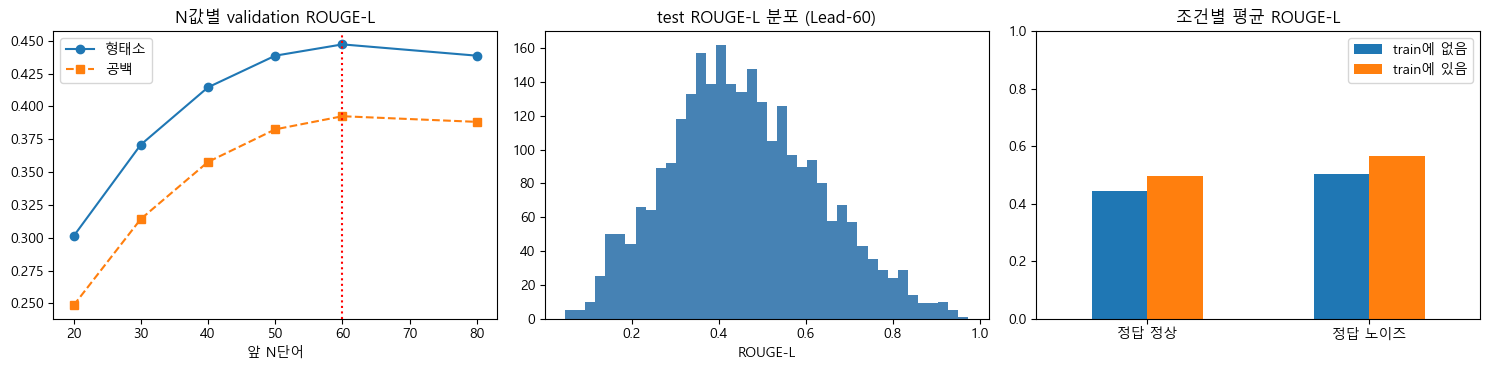


[예시: ROUGE-L 높은 것 / 낮은 것]

--- 높음 (R-L 0.974, 복사율 1.00) ---
[정답] 박일준 산업통상자원부 2차관이  4일 정부세종청사 산업부 전력수급상황실에서  여름철 전력수급 비상대책기간 첫날 전력 유관기관별 상황점검 회의 를 주재하고 있다.
[예측] 서울 연합뉴스 박일준 산업통상자원부 2차관이 4일 정부세종청사 산업부 전력수급상황실에서 여름철 전력수급 비상대책기간 첫날 전력 유관기관별 상황점검 회의 를 주재하고 있다.

--- 낮음 (R-L 0.047, 복사율 1.00) ---
[정답] 4거리 먹거리 물가 오름세가 4일 서울의 서울의 서울의 서울의 한 대형마트에서 시민들이 먹거리 물가 오름세가 4일 서울의 서울의 한 대형마트에서 먹거리 물가 오름세가 4일 서울의 서울의 먹거리 물가 오름세가 4일 서울의 서울의 서울의 서울의 서울의 서울의 서울의 한 대
[예측] 서울 연합뉴스 강민지 기자 먹거리 물가 오름세가 지속 중인 4일 서울의 한 대형마트에서 시민들이 장을 보고 있다.


In [2]:
# ============================================================
# [03-2] 베이스라인 A: 기사 앞 N단어 자르기 (Lead-N)
#   - N은 validation(v1_val)에서 ROUGE-L 최대인 값으로 선택
#   - test 평가 + 조건별(누수/노이즈/길이/분야) 분석
#   출력: outputs/03-2_leadN_search.csv, 03-2_baseline_a_detail.csv, figures/03-2_baseline_a.png
#         experiment_log.csv 에 1행 추가
# ============================================================
import time

val  = pd.read_csv(PROC / "v1_val.csv")       # N 선택용 (누수 제거된 val)
test = pd.read_csv(PROC / "test.csv")

def lead_n(doc, n): return " ".join(doc.split()[:n])

print(f"정답 요약 길이(val): 평균 {val['summary'].str.split().str.len().mean():.1f}단어, "
      f"중앙값 {val['summary'].str.split().str.len().median():.0f}단어")

# ---------- N 탐색 ----------
rows = []
for n in [20, 30, 40, 50, 60, 80]:
    s = evaluate([lead_n(d, n) for d in val["document"]], val["summary"].tolist(), docs=val["document"].tolist())
    s["N"] = n; rows.append(s)
search = pd.DataFrame(rows)[["N", "rouge1", "rouge2", "rougeL", "rougeL_space", "avg_words", "copy_rate"]]
print("\n" + "=" * 70); print("[N값별 validation 성능]"); print("=" * 70)
print(search.to_string(index=False))
best_n = int(search.loc[search["rougeL"].idxmax(), "N"])
print(f"\n→ 최적 N = {best_n} (validation ROUGE-L 기준)")
search.to_csv(OUT / "03-2_leadN_search.csv", index=False, encoding="utf-8-sig")

# ---------- test 평가 ----------
t0 = time.time()
preds = [lead_n(d, best_n) for d in test["document"]]
score, detail = evaluate(preds, test["summary"].tolist(), docs=test["document"].tolist(), per_sample=True)
score.update({"exp": f"baseline_A_lead{best_n}", "data": "-", "model": "lead-N", "time_sec": round(time.time() - t0, 1)})
print("\n" + "=" * 70); print("[베이스라인 A: test 결과]"); print("=" * 70)
for k, v in score.items(): print(f"  {k:<14}: {v}")
log_experiment(score)

# ---------- 조건별 분석 ----------
detail = pd.concat([detail, test[["in_train", "is_noisy", "category"]]], axis=1)
detail["doc_words"] = test["document"].str.split().str.len()
detail["len_group"] = pd.cut(detail["doc_words"], [0, 100, 200, 400, np.inf], labels=["~100", "100~200", "200~400", "400~"])
print("\n[조건별 ROUGE-L (test)]")
for col, lab in [("in_train", "train에 있던 기사"), ("is_noisy", "정답 노이즈"), ("category", "분야"), ("len_group", "본문 단어 수")]:
    g = detail.groupby(col, observed=True)["rougeL"].agg(["mean", "count"]).round(4)
    print(f"\n  {lab}:"); print(g.to_string())
detail.to_csv(OUT / "03-2_baseline_a_detail.csv", index=False, encoding="utf-8-sig")

# ---------- 그래프 ----------
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(search["N"], search["rougeL"], "o-", label="형태소"); ax[0].plot(search["N"], search["rougeL_space"], "s--", label="공백")
ax[0].axvline(best_n, color="red", ls=":"); ax[0].set_title("N값별 validation ROUGE-L"); ax[0].set_xlabel("앞 N단어"); ax[0].legend()
ax[1].hist(detail["rougeL"], bins=40, color="steelblue"); ax[1].set_title(f"test ROUGE-L 분포 (Lead-{best_n})"); ax[1].set_xlabel("ROUGE-L")
g = detail.groupby(["is_noisy", "in_train"])["rougeL"].mean().unstack()
g.index = ["정답 정상", "정답 노이즈"]; g.columns = ["train에 없음", "train에 있음"]
g.plot.bar(ax=ax[2], rot=0); ax[2].set_title("조건별 평균 ROUGE-L"); ax[2].set_ylim(0, 1)
plt.tight_layout(); plt.savefig(FIG / "03-2_baseline_a.png", dpi=130); plt.show()

# ---------- 예시 ----------
print("\n[예시: ROUGE-L 높은 것 / 낮은 것]")
for lab, i in [("높음", detail["rougeL"].idxmax()), ("낮음", detail["rougeL"].idxmin())]:
    print(f"\n--- {lab} (R-L {detail.loc[i, 'rougeL']:.3f}, 복사율 {detail.loc[i, 'copy_rate']:.2f}) ---")
    print("[정답]", test.loc[i, "summary"][:150]); print("[예측]", preds[i][:150])


---
# 4. 파인튜닝

## 4-1. 학습 설정

모든 버전에 **완전히 같은 조건**을 적용했습니다. 바뀌는 것은 데이터뿐입니다.

| 항목 | 값 | 비고 |
|---|---|---|
| 모델 / 시드 | KoBART / 42 | |
| 학습률 | 3e-5, warmup 5%, weight decay 0.01 | |
| 배치 | 4 × 누적 4 = **실제 16** | GPU 8GB 제약으로 나눔. 실제 배치는 동일 |
| 입력 / 요약 길이 | 512 / 160 토큰 | 1-2, 1-4 근거 |
| epoch | 최대 3 + 얼리스타핑 | 200 step마다 검증, 3회 개선 없으면 중단 |
| 정답 처리 | `</s>` 직접 추가, pad → -100 | KoBART는 종료 토큰을 자동으로 붙이지 않음 |
| fp16 | 사용 | |

`VERSIONS` 목록에 적은 버전을 순서대로 자동 학습·평가합니다. 하나가 실패해도 다음 버전은 계속 진행하며, 진행 상황은 `outputs/04_run_status.txt`에 기록됩니다.

In [7]:
# ============================================================
# [04-1] 설정 — 밤새 자동 실행용
#   VERSIONS 에 적은 데이터 버전을 순서대로 학습 → 평가 → 디코딩 실험까지 자동 진행
#   버전 하나가 실패해도 다음 버전은 계속 진행 (에러는 outputs/04_run_status.txt 에 기록)
#   고정: 모델, 시드, lr 3e-5, 배치 8×누적2, 입력 512 / 요약 160, 평가 함수
#   얼리스타핑: 200 step 마다 val loss 측정, 연속 3회 개선 없으면 중단, val loss 최저 모델 사용
# ============================================================
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))
from common import *
import time, json, gc, traceback, torch
from transformers import (AutoTokenizer, BartForConditionalGeneration, DataCollatorForSeq2Seq,
                          Seq2SeqTrainingArguments, Seq2SeqTrainer, EarlyStoppingCallback, set_seed)
from datasets import Dataset

# VERSIONS   = ["v0", "v1", "v2"]     # ← 순서대로 자동 실행
VERSIONS   = ["v2a", "v2b", "v2c"] 
QUICK      = False                  # True면 5,000건·1 epoch (테스트용)
MODEL_NAME = "gogamza/kobart-base-v2"
MAX_SRC, MAX_TGT = 512, 160
CFG = dict(lr=3e-5, max_epochs=1 if QUICK else 3, batch=4, grad_accum=4,
           eval_steps=100 if QUICK else 200, patience=3, n_train=5000 if QUICK else None)

# 디코딩 실험 설정 (학습 후 같은 모델로 생성만 다르게)
# DECODING = {
#     "beam4":            dict(num_beams=4, no_repeat_ngram_size=0, length_penalty=1.0),   # 기본
#     "beam4_norep3":     dict(num_beams=4, no_repeat_ngram_size=3, length_penalty=1.0),   # 반복 억제
#     "greedy":           dict(num_beams=1, no_repeat_ngram_size=0, length_penalty=1.0),
#     "beam8_norep3":     dict(num_beams=8, no_repeat_ngram_size=3, length_penalty=1.0),
#     "beam4_norep3_lp08": dict(num_beams=4, no_repeat_ngram_size=3, length_penalty=0.8),   # 짧게 유도
# }

# DECODING = {
#     "beam4":            dict(num_beams=4, no_repeat_ngram_size=0, length_penalty=1.0),   # 기본
#     "beam4_norep3":     dict(num_beams=4, no_repeat_ngram_size=3, length_penalty=1.0),   # 반복 억제
# }

DECODING = {
    "beam4":  dict(num_beams=4, no_repeat_ngram_size=0),
    "norep6": dict(num_beams=4, no_repeat_ngram_size=6),
}

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
STATUS = OUT / "04_run_status.txt"
def status(msg):
    line = f"[{datetime.datetime.now().strftime('%m-%d %H:%M:%S')}] {msg}"
    print(line); open(STATUS, "a", encoding="utf-8").write(line + "\n")

test_df = pd.read_csv(PROC / "test.csv")
test_docs = test_df["document"].tolist(); test_refs = test_df["summary"].tolist()
print(f"device={DEVICE} | versions={VERSIONS} | quick={QUICK} | cfg={CFG}")
print(f"test {len(test_df):,}건 (공통)")


device=cuda | versions=['v2a', 'v2b', 'v2c'] | quick=False | cfg={'lr': 3e-05, 'max_epochs': 3, 'batch': 4, 'grad_accum': 4, 'eval_steps': 200, 'patience': 3, 'n_train': None}
test 2,740건 (공통)


## 4-2. 함수 정의 — 토큰화 / 학습 / 생성 / 평가

In [8]:
# ============================================================
# [04-2] 함수 정의: 토큰화 / 학습 / 생성·평가
# ============================================================
def build_datasets(tok, train_df, val_df):
    def preprocess(batch):
        enc = tok(batch["document"], max_length=MAX_SRC, truncation=True, return_token_type_ids=False)
        lab = tok(batch["summary"], max_length=MAX_TGT - 1, truncation=True, return_token_type_ids=False)["input_ids"]
        enc["labels"] = [l + [tok.eos_token_id] for l in lab]          # KoBART는 </s>를 자동으로 안 붙임
        return enc
    mk = lambda df: Dataset.from_pandas(df[["document", "summary"]], preserve_index=False).map(
        preprocess, batched=True, remove_columns=["document", "summary"])
    return mk(train_df), mk(val_df)

def train_version(version):
    run = f"{version}_kobart{'_quick' if QUICK else ''}"
    model_dir = ROOT / "models" / run
    set_seed(SEED)
    train_df = pd.read_csv(PROC / f"{version}_train.csv")
    val_df   = pd.read_csv(PROC / f"{version}_val.csv")
    if CFG["n_train"]: train_df = train_df.sample(CFG["n_train"], random_state=SEED)
    val_small = val_df.sample(min(500, len(val_df)), random_state=SEED)

    tok = AutoTokenizer.from_pretrained(MODEL_NAME)
    model = BartForConditionalGeneration.from_pretrained(MODEL_NAME).to(DEVICE)
    if model.config.decoder_start_token_id is None: model.config.decoder_start_token_id = tok.eos_token_id
    model.config.forced_eos_token_id = tok.eos_token_id

    train_ds, val_ds = build_datasets(tok, train_df, val_small)
    collator = DataCollatorForSeq2Seq(tok, model=model, label_pad_token_id=-100)
    s = collator([train_ds[0]])
    assert (s["labels"] == -100).any().item() or len(train_ds[0]["labels"]) == s["labels"].shape[1], "pad→-100 처리 확인 실패"
    status(f"{run}: train {len(train_df):,} | val {len(val_small)} | 정답 끝 토큰 = "
           f"{tok.convert_ids_to_tokens([l for l in s['labels'][0].tolist() if l != -100][-1:])}")

    args = Seq2SeqTrainingArguments(
        output_dir=str(model_dir / "ckpt"), seed=SEED,
        learning_rate=CFG["lr"], num_train_epochs=CFG["max_epochs"],
        per_device_train_batch_size=CFG["batch"], per_device_eval_batch_size=16,
        gradient_accumulation_steps=CFG["grad_accum"],
        fp16=(DEVICE == "cuda"), warmup_ratio=0.05, weight_decay=0.01,
        eval_strategy="steps", eval_steps=CFG["eval_steps"], logging_steps=50,
        save_strategy="steps", save_steps=CFG["eval_steps"], save_total_limit=2,
        load_best_model_at_end=True, metric_for_best_model="eval_loss", greater_is_better=False,
        report_to="none", dataloader_num_workers=0, disable_tqdm=True,
    )
    trainer = Seq2SeqTrainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                             data_collator=collator, tokenizer=tok,
                             callbacks=[EarlyStoppingCallback(early_stopping_patience=CFG["patience"])])
    t0 = time.time(); trainer.train(); train_min = (time.time() - t0) / 60
    trainer.save_model(str(model_dir)); tok.save_pretrained(str(model_dir))

    log = pd.DataFrame(trainer.state.log_history)
    log.to_csv(OUT / f"04-3_{run}_train_log.csv", index=False, encoding="utf-8-sig")
    ev = log[log["eval_loss"].notna()] if "eval_loss" in log else log.iloc[0:0]
    tr = log[log["loss"].notna()] if "loss" in log else log.iloc[0:0]
    best_step = int(ev.loc[ev["eval_loss"].idxmin(), "step"]) if len(ev) else -1
    fig, ax = plt.subplots(figsize=(7, 3.5))
    if len(tr): ax.plot(tr["step"], tr["loss"], label="train loss")
    if len(ev): ax.plot(ev["step"], ev["eval_loss"], "o-", label="val loss"); ax.axvline(best_step, color="red", ls=":", label=f"best step {best_step}")
    ax.set_xlabel("step"); ax.set_title(f"{run} 학습 곡선 ({train_min:.0f}분, 총 {trainer.state.global_step} step)"); ax.legend()
    plt.tight_layout(); plt.savefig(FIG / f"04-3_{run}_loss.png", dpi=130); plt.close()
    info = dict(run=run, n_train=len(train_df), train_min=round(train_min, 1), total_steps=trainer.state.global_step,
                best_step=best_step, best_val_loss=round(float(ev["eval_loss"].min()), 4) if len(ev) else None,
                epochs_done=round(float(trainer.state.epoch), 2))
    status(f"{run}: 학습 완료 {train_min:.0f}분, {trainer.state.global_step} step, best step {best_step} (val loss {info['best_val_loss']})")
    del trainer; gc.collect()
    return model, tok, info

def generate_all(model, tok, docs, gen_cfg, batch=8):
    model.eval(); preds = []
    for i in range(0, len(docs), batch):
        enc = tok(docs[i:i+batch], max_length=MAX_SRC, truncation=True, padding=True,
                  return_tensors="pt", return_token_type_ids=False).to(DEVICE)
        with torch.no_grad():
            out = model.generate(**enc, max_new_tokens=MAX_TGT, **gen_cfg)
        preds.extend(tok.batch_decode(out, skip_special_tokens=True))
    return preds

def evaluate_and_log(preds, run, version, info, gen_name, gen_cfg, gen_min, save_preds=True):
    score, detail = evaluate(preds, test_refs, docs=test_docs, per_sample=True)
    detail = pd.concat([detail, test_df[["in_train", "is_noisy", "category"]]], axis=1)
    detail["pred"] = preds; detail["ref"] = test_refs
    detail["boiler"] = detail["pred"].str.contains("newsis|제보를 기다|반영하겠|재판매 및 DB", regex=True)
    detail["first_word_ok"] = [(p.split()[0] in d) if p.split() else False for p, d in zip(preds, test_docs)]
    clean = detail[~detail["is_noisy"]]; noleak = detail[~detail["in_train"]]
    score.update({"exp": f"{run}__{gen_name}", "data": version, "model": "kobart", "decoding": gen_name,
                  "gen": json.dumps(gen_cfg), "gen_min": round(gen_min, 1),
                  "rougeL_clean": round(clean["rougeL"].mean(), 4),        # 정답 정상인 test만
                  "rougeL_noleak": round(noleak["rougeL"].mean(), 4),      # train에 없던 test만
                  "boiler_rate": round(detail["boiler"].mean() * 100, 2),
                  "first_word_bad": round((~detail["first_word_ok"]).mean() * 100, 2), **info, **CFG})
    log_experiment(score)
    if save_preds:
        detail.to_csv(OUT / f"04-4_{run}__{gen_name}_test_preds.csv", index=False, encoding="utf-8-sig")
    return score, detail

print("함수 정의 완료")


함수 정의 완료


## 4-3. 자동 실행

아래 셀의 출력은 마지막 실행분(v2a/v2b/v2c)입니다. 전체 실행 기록은 `outputs/04_run_status.txt`에 누적되어 있습니다.

In [9]:
# ============================================================
# [04-3] 자동 실행: 버전마다 학습 → 기본 디코딩 평가 → 디코딩 실험 4종
#   실행 후 자리를 비워도 됨. 진행 상황은 outputs/04_run_status.txt 에 기록
# ============================================================
status(f"===== 시작: versions={VERSIONS}, quick={QUICK} =====")
for version in VERSIONS:
    try:
        model, tok, info = train_version(version)
        run = info["run"]
        for gen_name, gen_cfg in DECODING.items():
            t0 = time.time()
            preds = generate_all(model, tok, test_docs, gen_cfg)
            score, _ = evaluate_and_log(preds, run, version, info, gen_name, gen_cfg, (time.time() - t0) / 60,
                                        save_preds=(gen_name in ["beam4", "beam4_norep3"]))
            status(f"{run} [{gen_name}] R-L {score['rougeL']:.4f} | clean {score['rougeL_clean']:.4f} | "
                   f"반복 {score['repeat_rate']}% | 길이 {score['avg_words']}")
        del model; gc.collect(); torch.cuda.empty_cache() if DEVICE == "cuda" else None
    except Exception as e:
        status(f"{version}: 실패 — {type(e).__name__}: {e}")
        open(STATUS, "a", encoding="utf-8").write(traceback.format_exc() + "\n")
        gc.collect(); torch.cuda.empty_cache() if DEVICE == "cuda" else None
status("===== 전체 완료 =====")


[09-20 20:01:46] ===== 시작: versions=['v2a', 'v2b', 'v2c'], quick=False =====


You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
c:\Users\wm032\Documents\news_summary\.venv\Lib\site-packages\transformers\tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(
You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


Map:   0%|          | 0/18591 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

[09-20 20:01:54] v2a_kobart: train 18,591 | val 500 | 정답 끝 토큰 = ['</s>']


...

{'train_runtime': 1051.6792, 'train_samples_per_second': 56.202, 'train_steps_per_second': 3.512, 'train_loss': 0.5231404094696045, 'epoch': 2.43605359317905}
[09-20 22:03:25] v2c_kobart: 학습 완료 18분, 3000 step, best step 2400 (val loss 0.4408)


c:\Users\wm032\Documents\news_summary\common.py:66: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  row = pd.concat([pd.read_csv(path), row], ignore_index=True)


[09-20 22:17:02] v2c_kobart [beam4] R-L 0.5622 | clean 0.5628 | 반복 6.24% | 길이 44.4


c:\Users\wm032\Documents\news_summary\common.py:66: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  row = pd.concat([pd.read_csv(path), row], ignore_index=True)


[09-20 22:34:50] v2c_kobart [norep6] R-L 0.5649 | clean 0.5645 | 반복 0.66% | 길이 40.7
[09-20 22:34:51] ===== 전체 완료 =====


## 4-4. 데이터 버전 비교 결과 (디코딩 beam4)

| 버전 | 전체 | clean | **noleak** | 전체−noleak | 반복률 | 광고문구 |
|---|---|---|---|---|---|---|
| 베이스라인 | 0.4570 | 0.447 | 0.448 | — | 1.86% | — |
| v0 | **0.5743** | 0.5654 | **0.5552** | **0.019** | 7.04% | 0.88% |
| v1 | 0.5653 | 0.5665 | 0.5624 | 0.003 | 6.17% | 0.91% |
| v2 | 0.5692 | 0.5659 | 0.5620 | 0.007 | **2.74%** | **0.11%** |

### ① 전이학습 효과

베이스라인 0.457 → 파인튜닝 0.568. **+0.111 (24% 상승)**

### ② v0의 1등은 착시였다

v0는 전체 점수가 1등이지만 **학습에 없던 기사만 보면 꼴찌**입니다.
전체와 noleak의 차이가 v0는 0.019, v1은 0.003 — **이 0.016이 "시험 문제를 미리 본" 효과**입니다.

더 나아가 v0는 안 본 기사에서 v1·v2보다 **0.007 낮습니다**. 중복 제거가 점수 부풀림을 막을 뿐 아니라
**일반화 성능 자체를 올렸다**는 뜻입니다. (같은 사진 기사를 16번씩 학습해 편향된 것으로 보입니다)

### ③ v1과 v2는 실력이 같고 버릇만 다르다

clean 0.5665 vs 0.5659, noleak 0.5624 vs 0.5620 — **차이 0.0006으로 사실상 동일**합니다.
그런데 반복률은 2.3배, 광고 문구는 8배 줄었습니다. **데이터를 1,665건 버렸는데 성능 손실이 없었습니다.**

→ **기준 버전 = v2**

---
# 5. 교차 검증 — 이상 현상의 원인 규명

## 무엇이 이상했나

| 버전 | 총 step | 최적 지점 | 얼리스타핑 |
|---|---|---|---|
| v0 | 3,200 | 2,600 (1.9 epoch) | 걸림 — 과적합 시작 |
| v1 | 3,000 | 2,400 (1.9 epoch) | 걸림 |
| v2 | 3,402 | 3,400 (3.0 epoch) | **안 걸림 — 끝까지 좋아짐** |

두 가지 해석이 가능했습니다.

- **(a)** 노이즈를 빼서 과적합이 늦게 온다 → 좋은 일
- **(b)** v2의 검증셋 자체가 쉬워졌다 → 착시

## 구분하는 방법

두 모델을 **서로의 검증셋으로 교차 평가**합니다. 학습 없이 평가만 하므로 5분이면 됩니다.

| | v1 검증셋 | v2 검증셋 |
|---|---|---|
| v1 모델 | 0.4538 | 0.4335 |
| v2 모델 | 0.4685 | 0.4385 |

**같은 모델이라도 v2 검증셋에서 loss가 0.02 낮습니다.** 망가진 정답이 빠져 예측하기 쉬운 문제만 남았기 때문입니다.
→ **(b)가 답입니다.** 과적합이 늦게 온 게 아니라 바닥이 낮아서 도달하지 못한 것입니다.

### 부수적으로 알게 된 것 — loss는 모델 비교에 쓸 수 없다

v1 모델이 양쪽 검증셋에서 모두 loss가 낮습니다. 그런데 **ROUGE는 같고 반복률은 2.3배 많습니다.**

loss는 "정답 토큰을 얼마나 잘 예측하나"를 재는데, 정답에 반복이 있으면 반복을 잘 예측하는 모델의 loss가 낮아집니다.
**loss가 낮다 = 정답을 잘 흉내 낸다**이지 요약이 좋다는 뜻이 아닙니다.

→ loss는 얼리스타핑 기준으로만 쓰고, 모델 선택은 ROUGE·반복률·사실성으로 합니다.

> 이 결론은 8장에서 한 번 더 확인됩니다. v2c(광고 문구 113건만 제거)는 v1과 **똑같은 2,400 step**에서 얼리스타핑이 걸렸습니다.

In [9]:
# ============================================================
# [04-6] v2 모델을 v1 val / v2 val 양쪽으로 재평가
#   목적: v2가 3 epoch까지 val loss가 내려간 이유 구분
#     (a) 노이즈 제거로 과적합이 늦게 옴  → v1 val에서도 낮음
#     (b) v2 val 자체가 쉬워짐           → v1 val에서는 높음
#   비교: v1 모델도 같은 두 val로 재평가 (같은 자로 재기 위해)
# ============================================================
from transformers import Seq2SeqTrainingArguments, Seq2SeqTrainer

val_sets = {"v1_val": pd.read_csv(PROC / "v1_val.csv").sample(500, random_state=SEED),
            "v2_val": pd.read_csv(PROC / "v2_val.csv").sample(500, random_state=SEED)}
rows = []
for mv in ["v1", "v2"]:
    mdir = ROOT / "models" / f"{mv}_kobart"
    tok = AutoTokenizer.from_pretrained(str(mdir))
    model = BartForConditionalGeneration.from_pretrained(str(mdir)).to(DEVICE)
    collator = DataCollatorForSeq2Seq(tok, model=model, label_pad_token_id=-100)
    args = Seq2SeqTrainingArguments(output_dir=str(ROOT / "models" / "_tmp_eval"), per_device_eval_batch_size=16,
                                    fp16=(DEVICE == "cuda"), report_to="none", disable_tqdm=True)
    trainer = Seq2SeqTrainer(model=model, args=args, data_collator=collator, tokenizer=tok)
    for vn, vdf in val_sets.items():
        _, ds = build_datasets(tok, vdf.iloc[:1], vdf)      # train 부분은 더미
        loss = trainer.evaluate(eval_dataset=ds)["eval_loss"]
        rows.append({"모델": mv, "평가 val": vn, "val_loss": round(loss, 4)})
        print(f"{mv} 모델 → {vn}: loss {loss:.4f}")
    del model, trainer; gc.collect(); torch.cuda.empty_cache() if DEVICE == "cuda" else None

res = pd.DataFrame(rows).pivot(index="모델", columns="평가 val", values="val_loss")
print("\n" + "=" * 60); print("[모델 × val 교차 loss]"); print("=" * 60)
print(res.to_string())
res.to_csv(OUT / "04-6_cross_val_loss.csv", encoding="utf-8-sig")
print("\n같은 열(같은 val) 안에서 비교: v2 모델이 v1 모델보다 낮으면 (a), 높거나 같으면 (b)")

You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
c:\Users\wm032\Documents\news_summary\.venv\Lib\site-packages\accelerate\accelerator.py:488: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self.scaler = torch.cuda.amp.GradScaler(**kwargs)


Map:   0%|          | 0/1 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

{'eval_loss': 0.4538416862487793, 'eval_model_preparation_time': 0.002, 'eval_runtime': 2.3697, 'eval_samples_per_second': 210.993, 'eval_steps_per_second': 13.504}
v1 모델 → v1_val: loss 0.4538


Map:   0%|          | 0/1 [00:00<?, ? examples/s]

...

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

{'eval_loss': 0.46845853328704834, 'eval_model_preparation_time': 0.001, 'eval_runtime': 2.2274, 'eval_samples_per_second': 224.477, 'eval_steps_per_second': 14.367}
v2 모델 → v1_val: loss 0.4685


Map:   0%|          | 0/1 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

{'eval_loss': 0.43849900364875793, 'eval_model_preparation_time': 0.001, 'eval_runtime': 2.1998, 'eval_samples_per_second': 227.291, 'eval_steps_per_second': 14.547}
v2 모델 → v2_val: loss 0.4385

[모델 × val 교차 loss]
평가 val  v1_val  v2_val
모델                    
v1      0.4538  0.4335
v2      0.4685  0.4385

같은 열(같은 val) 안에서 비교: v2 모델이 v1 모델보다 낮으면 (a), 높거나 같으면 (b)


---
# 6. 정답 없는 지표

정답이 못 미더우니, 정답과 비교하지 않고 **원문만으로** 품질을 재는 지표를 추가했습니다.

| 지표 | 계산 방법 | 편향 (알고 봐야 할 것) |
|---|---|---|
| 숫자 일치율 | 요약의 숫자 집합 ⊆ 원문 숫자 집합 | 베끼면 유리 |
| 고유명사 일치율 | 형태소 분석기 NNP 태그 단어가 원문에 있는가 | 베끼면 유리 |
| 퍼플렉시티 | KoGPT2로 잰 토큰당 값 (중앙값) | **반복하면 낮게(좋게) 나옴** |

In [2]:
from kiwipiepy import Kiwi
_kiwi = Kiwi()
def nnps(t):    return {tk.form for tk in _kiwi.tokenize(t) if tk.tag == "NNP"}

The tokenizer class you load from this checkpoint is not the same type as the class this function is called from. It may result in unexpected tokenization. 
The tokenizer class you load from this checkpoint is 'GPT2Tokenizer'. 
The class this function is called from is 'PreTrainedTokenizerFast'.
c:\Users\wm032\Documents\news_summary\.venv\Lib\site-packages\transformers\tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


baseline_A               숫자  99.78% | 고유명사  99.64% | PPL 중앙값   69.62
v0_kobart__beam4_norep3  숫자  97.92% | 고유명사  90.73% | PPL 중앙값   77.26
v0_kobart__beam4         숫자  99.23% | 고유명사  93.69% | PPL 중앙값   59.21
v1_kobart__beam4_norep3  숫자  98.69% | 고유명사  92.23% | PPL 중앙값   79.05
v1_kobart__beam4         숫자  99.16% | 고유명사  95.44% | PPL 중앙값   61.46
v2_kobart__beam4_norep3  숫자  98.32% | 고유명사  90.95% | PPL 중앙값   79.15
v2_kobart__beam4         숫자  99.34% | 고유명사  95.11% | PPL 중앙값   62.64

[정답 없는 지표]
                         숫자 일치율(%)  고유명사 일치율(%)  둘 다 일치(%)  PPL 중앙값  PPL 평균  평균 단어
run                                                                               
baseline_A                   99.78        99.64      99.42    69.62   89.05   56.9
v0_kobart__beam4_norep3      97.92        90.73      88.83    77.26   97.08   39.1
v0_kobart__beam4             99.23        93.69      92.96    59.21   71.36   44.8
v1_kobart__beam4_norep3      98.69        92.23      90.95    79.05   97.37   37.5
v1_koba

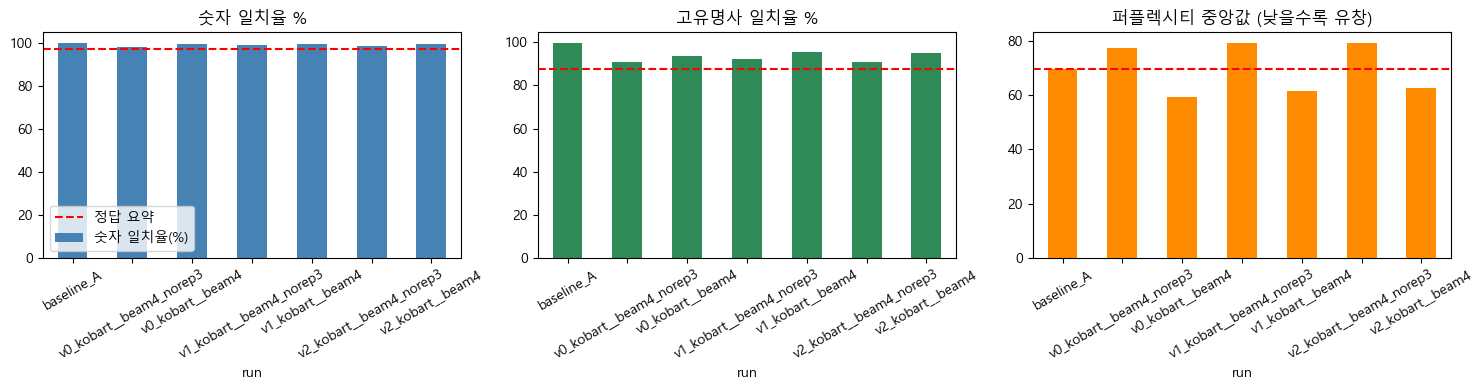

In [3]:
# ============================================================
# [05-1] 정답 없는 지표: 사실성 + 유창성
#   사실성: 요약의 숫자·고유명사(NNP)가 원문에 있는가 (정답 불필요)
#   유창성: 외부 모델(KoGPT2)로 잰 토큰당 퍼플렉시티 (정답 불필요, 낮을수록 자연스러움)
#   대상: 베이스라인 + v0/v1/v2 × beam4/norep3 (저장된 요약)
#   출력: outputs/05-1_extra_metrics.csv, 각 preds 파일에 num_ok/nnp_ok/ppl 컬럼 추가
# ============================================================
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))
from common import *
import re, torch, gc
from transformers import PreTrainedTokenizerFast, GPT2LMHeadModel

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
test = pd.read_csv(PROC / "test.csv")
docs = test["document"].tolist()

# ---------- 사실성 ----------
NUM_RE = re.compile(r"\d+(?:[.,]\d+)?")
def numbers(t): return set(NUM_RE.findall(t.replace(" ", "")))       # "2 300" → "2300"
def nnps(t):    return {tk.form for tk in _kiwi.tokenize(t) if tk.tag == "NNP"}

doc_nums = [numbers(d) for d in docs]
doc_nnps = [nnps(d) for d in docs]

def factuality(preds):
    num_ok, nnp_ok, num_bad_cnt = [], [], []
    for p, dn, dp in zip(preds, doc_nums, doc_nnps):
        pn, pp = numbers(p), nnps(p)
        num_ok.append(pn <= dn); nnp_ok.append(pp <= dp)
        num_bad_cnt.append(len(pn - dn))
    return np.array(num_ok), np.array(nnp_ok), np.array(num_bad_cnt)

# ---------- 유창성 (KoGPT2 퍼플렉시티) ----------
gpt_tok = PreTrainedTokenizerFast.from_pretrained("skt/kogpt2-base-v2",
            bos_token="</s>", eos_token="</s>", unk_token="<unk>", pad_token="<pad>", mask_token="<mask>")
gpt = GPT2LMHeadModel.from_pretrained("skt/kogpt2-base-v2").to(DEVICE).eval()

def perplexity(texts, batch=16):
    out = []
    for i in range(0, len(texts), batch):
        b = [gpt_tok.bos_token + t + gpt_tok.eos_token for t in texts[i:i+batch]]
        enc = gpt_tok(b, return_tensors="pt", padding=True, truncation=True, max_length=256).to(DEVICE)
        labels = enc["input_ids"].clone(); labels[enc["attention_mask"] == 0] = -100
        with torch.no_grad():
            logits = gpt(**enc).logits[:, :-1]
        tgt = labels[:, 1:]
        nll = torch.nn.functional.cross_entropy(logits.transpose(1, 2), tgt, ignore_index=-100, reduction="none")
        n_tok = (tgt != -100).sum(1).clamp(min=1)
        out.extend(torch.exp(nll.sum(1) / n_tok).cpu().tolist())          # 요약별 토큰당 PPL
    return np.array(out)

# ---------- 대상 모음 ----------
def lead_n(doc, n): return " ".join(doc.split()[:n])
targets = {"baseline_A": pd.DataFrame({"pred": [lead_n(d, 60) for d in docs]})}
for p in sorted(OUT.glob("04-4_v*_kobart__beam4*_test_preds.csv")):
    if "quick" in p.name: continue
    targets[p.stem.replace("04-4_", "").replace("_test_preds", "")] = pd.read_csv(p)

# ---------- 계산 ----------
rows = []
for name, df in targets.items():
    preds = df["pred"].fillna("").astype(str).tolist()
    num_ok, nnp_ok, num_bad = factuality(preds)
    ppl = perplexity(preds)
    df["num_ok"], df["nnp_ok"], df["num_bad_cnt"], df["ppl"] = num_ok, nnp_ok, num_bad, ppl
    if name != "baseline_A":
        df.to_csv(OUT / f"04-4_{name}_test_preds.csv", index=False, encoding="utf-8-sig")   # 컬럼 추가 저장
    rows.append({"run": name,
                 "숫자 일치율(%)": round(num_ok.mean() * 100, 2),
                 "고유명사 일치율(%)": round(nnp_ok.mean() * 100, 2),
                 "둘 다 일치(%)": round((num_ok & nnp_ok).mean() * 100, 2),
                 "PPL 중앙값": round(float(np.median(ppl)), 2),
                 "PPL 평균": round(float(ppl.mean()), 2),
                 "평균 단어": round(np.mean([len(p.split()) for p in preds]), 1)})
    print(f"{name:<24} 숫자 {rows[-1]['숫자 일치율(%)']:>6}% | 고유명사 {rows[-1]['고유명사 일치율(%)']:>6}% | PPL 중앙값 {rows[-1]['PPL 중앙값']:>7}")

res = pd.DataFrame(rows).set_index("run")
# 정답 요약 자체의 값 (참고 기준선)
ref_num, ref_nnp, _ = factuality(test["summary"].tolist()); ref_ppl = perplexity(test["summary"].tolist())
res.loc["(정답 요약)"] = [round(ref_num.mean()*100, 2), round(ref_nnp.mean()*100, 2), round((ref_num & ref_nnp).mean()*100, 2),
                       round(float(np.median(ref_ppl)), 2), round(float(ref_ppl.mean()), 2), round(test["summary"].str.split().str.len().mean(), 1)]
print("\n" + "=" * 78); print("[정답 없는 지표]"); print("=" * 78)
print(res.to_string())
res.to_csv(OUT / "05-1_extra_metrics.csv", encoding="utf-8-sig")

# 그래프
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
res_m = res.drop("(정답 요약)")
res_m["숫자 일치율(%)"].plot.bar(ax=ax[0], rot=30, color="steelblue"); ax[0].axhline(res.loc["(정답 요약)", "숫자 일치율(%)"], color="red", ls="--", label="정답 요약"); ax[0].set_title("숫자 일치율 %"); ax[0].legend()
res_m["고유명사 일치율(%)"].plot.bar(ax=ax[1], rot=30, color="seagreen"); ax[1].axhline(res.loc["(정답 요약)", "고유명사 일치율(%)"], color="red", ls="--"); ax[1].set_title("고유명사 일치율 %")
res_m["PPL 중앙값"].plot.bar(ax=ax[2], rot=30, color="darkorange"); ax[2].axhline(res.loc["(정답 요약)", "PPL 중앙값"], color="red", ls="--"); ax[2].set_title("퍼플렉시티 중앙값 (낮을수록 유창)")
plt.tight_layout(); plt.savefig(FIG / "05-1_extra_metrics.png", dpi=130); plt.show()

del gpt; gc.collect(); torch.cuda.empty_cache() if DEVICE == "cuda" else None

## 6-1. 발견 ① 모델이 정답보다 정확하다

| 대상 | 숫자 | 고유명사 | 둘 다 | 퍼플렉시티 |
|---|---|---|---|---|
| 베이스라인 (원문 베끼기) | 99.78 | 99.64 | 99.42 | 69.6 |
| **정답 요약** | 97.15 | **87.74** | **85.26** | 69.5 |
| v0 (beam4) | 99.23 | 93.69 | 92.96 | 59.2 |
| v1 (beam4) | 99.16 | 95.44 | 94.67 | 61.5 |

정답 요약의 고유명사 정확도가 **87.74%** — 즉 **정답의 12%에 원문에 없는 이름이 들어 있습니다.**
("이제너두"→"이제세두", "서울 아파트"→"한국 아파트", "LG유플러스"→"5일유플러스")

그런데 모델은 93~95%입니다. **그 정답으로 배웠는데도 오류를 그대로 따라 하지 않았습니다.**

## 6-2. 발견 ② 퍼플렉시티는 반복을 좋아한다

예상은 "베이스라인이 가장 자연스러울 것"이었는데 정반대가 나왔습니다.

| 대상 | 반복률 | 퍼플렉시티 |
|---|---|---|
| v0 | 7.04% | **59.2 (최저)** |
| v1 | 6.17% | 61.5 |
| v2 | 2.74% | 62.6 |
| 베이스라인 | 1.86% | 69.6 |
| 3단어 금지 | 0.04% | 79.1 |

**반복이 많을수록 퍼플렉시티가 낮습니다.** "서울의 서울의 서울의" 다음에 올 단어는 맞히기가 아주 쉽기 때문입니다.
퍼플렉시티는 "예측 가능성"을 재는 것이지 유창성이 아닙니다. → **반복률과 반드시 짝으로 봐야 합니다.**

## 6-3. 발견 ③ 모든 지표에서 1등인 방법이 있다

**원문을 그대로 베끼는 것**입니다. 베이스라인은 사실성 99.6%, 반복률 1.9%로 모든 형식 지표에서 최고인데 ROUGE-L은 0.457로 꼴찌입니다.

→ **어느 지표도 단독으로 쓰지 않습니다.** 베끼면 유리한 지표(사실성)와 요약다워야 유리한 지표(ROUGE)를 함께 봐야 진짜 실력이 보입니다.

---
# 7. 디코딩 튜닝 — 부작용을 찾아서 고친 과정

디코딩은 학습이 끝난 모델이 요약을 **실제로 만들어내는 방식**입니다. 학습을 다시 하지 않고 생성 설정만 바꾸므로 빠릅니다.

## 7-1. 1차 실험 — 5종 비교

| 설정 | 의미 | ROUGE-L | 반복률 | 시간 |
|---|---|---|---|---|
| greedy (beam 1) | 매번 확률 1등만 선택 | 0.5711 | 5.07% | 3분 |
| **beam4** | 후보 4개를 동시에 탐색 | **0.5743** | 7.04% | 14분 |
| beam8 | 후보 8개 | 0.5586 | 0% | 26분 |
| beam4 + 3단어 반복금지 | 같은 3단어 묶음 재사용 금지 | 0.5652 | **0.04%** | 17분 |
| beam4 + 3단어금지 + 짧게 | 길이 페널티 0.8 | 0.5663 | 0% | 13분 |

**beam8이 오히려 낮았습니다.** 후보를 많이 보면 짧고 안전한 문장을 고르는 경향이 있어 정답과 덜 겹칩니다.
이 시점에서는 반복률 0.04%를 보고 **3단어 반복 금지를 채택**했습니다.

## 7-2. 부작용 발견

6장의 정답 없는 지표를 계산하다가 문제를 발견했습니다.

| 설정 | 반복률 | **고유명사 정확도** | 숫자 | 퍼플렉시티 | clean |
|---|---|---|---|---|---|
| 억제 없음 (beam4) | 2.74% | **95.11%** | 99.34% | 62.6 | 0.5659 |
| 3단어 금지 | 0.04% | **90.95%** | 98.32% | 79.1 | 0.5592 |

**고유명사 정확도가 4.16%p 떨어졌습니다.** 반복을 없애는 대가로 사실성을 잃고 있었습니다.

### 원인 — 정당한 재언급까지 막았다

기사에 "추경호 경제부총리 겸 기획재정부 장관"이 두 번 나오는 것은 자연스럽습니다.
그런데 3단어 금지는 **"경제부총리 겸 기획재정부"**가 두 번째로 나오려는 순간 차단합니다.

```
지금까지: … 추경호 경제부총리 겸 기획재정부 장관이 … 말했다. 추경호 경제부총리 겸
다음 후보:  기획재정부 0.91  /  장관 0.03  /  부총리 0.02

→ 기획재정부가 금지됨 → 확률 2등인 "장관"을 선택
→ "추경호 경제부총리 겸 장관"  ← 직함이 깨짐
```

**틀린 답을 고르는 게 아니라, 맞는 답을 못 고르게 막아서 2등을 고르게 되는 것**입니다.

In [5]:
gpt_tok = PreTrainedTokenizerFast.from_pretrained("skt/kogpt2-base-v2",
            bos_token="</s>", eos_token="</s>", unk_token="<unk>", pad_token="<pad>", mask_token="<mask>")
gpt = GPT2LMHeadModel.from_pretrained("skt/kogpt2-base-v2").to(DEVICE).eval()

The tokenizer class you load from this checkpoint is not the same type as the class this function is called from. It may result in unexpected tokenization. 
The tokenizer class you load from this checkpoint is 'GPT2Tokenizer'. 
The class this function is called from is 'PreTrainedTokenizerFast'.
c:\Users\wm032\Documents\news_summary\.venv\Lib\site-packages\transformers\tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


## 7-3. 2차 실험 — 억제 강도 조절

결과를 보기 **전에** 판단 기준을 먼저 정했습니다. 모든 기준값을 관찰된 값에서 끌어왔습니다.

| | 기준 | 근거 |
|---|---|---|
| 1 | 반복률 ≤ 1% | 정답 요약의 반복률 5.8%의 1/5 수준 |
| 2 | 고유명사 ≥ 94% | 억제 없음(95.11%)이 천장. 거기서 1%p 안쪽 |
| 3 | 퍼플렉시티 62.6~79.2 사이 | 억제 없음과 3단어 금지의 중간 |
| 4 | clean ≥ 0.5592 | 3단어 금지보다는 나아야 |
| 5 | 생성 시간 ≤ 20분 | beam8(26분)은 배제 |

In [ ]:
# ============================================================
# [05-2] 디코딩 재탐색: 반복 억제 강도 조절 (v2 모델, 학습 없음)
#   norep3의 부작용(정당한 재언급 금지 → 고유명사 오류)을 줄이는 설정 탐색
#   판단 기준: 반복률, 고유명사 일치, 숫자 일치, PPL, ROUGE clean — 다섯 개 같이
#   출력: outputs/05-2_decoding_refine.csv, 각 설정의 preds 파일
# ============================================================
from transformers import AutoTokenizer, BartForConditionalGeneration
import time, json

MAX_SRC, MAX_TGT = 512, 160
mdir = ROOT / "models" / "v2_kobart"
tok = AutoTokenizer.from_pretrained(str(mdir))
model = BartForConditionalGeneration.from_pretrained(str(mdir)).to(DEVICE).eval()

CANDIDATES = {
    "norep5":        dict(num_beams=4, no_repeat_ngram_size=5),
    "norep6":        dict(num_beams=4, no_repeat_ngram_size=6),
    "reppen1.2":     dict(num_beams=4, repetition_penalty=1.2),
    "norep6_reppen": dict(num_beams=4, no_repeat_ngram_size=6, repetition_penalty=1.1),
}

def generate_all(docs, gen_cfg, batch=16):
    preds = []
    for i in range(0, len(docs), batch):
        enc = tok(docs[i:i+batch], max_length=MAX_SRC, truncation=True, padding=True,
                  return_tensors="pt", return_token_type_ids=False).to(DEVICE)
        with torch.no_grad():
            out = model.generate(**enc, max_new_tokens=MAX_TGT, length_penalty=1.0, **gen_cfg)
        preds.extend(tok.batch_decode(out, skip_special_tokens=True))
        if (i // batch) % 30 == 0: print(f"  {i + len(out):>5}/{len(docs)}", end="\r")
    return preds

refs = test["summary"].tolist()
rows = []
for name, cfg in CANDIDATES.items():
    t0 = time.time()
    preds = generate_all(docs, cfg)
    score, detail = evaluate(preds, refs, docs=docs, per_sample=True)
    num_ok, nnp_ok, _ = factuality(preds); ppl = perplexity(preds) if "gpt" in dir() else np.full(len(preds), np.nan)
    detail = pd.concat([detail, test[["in_train", "is_noisy", "category"]]], axis=1)
    detail["pred"] = preds; detail["ref"] = refs
    detail["num_ok"], detail["nnp_ok"], detail["ppl"] = num_ok, nnp_ok, ppl
    detail["first_word_ok"] = [(p.split()[0] in d) if p.split() else False for p, d in zip(preds, docs)]
    detail.to_csv(OUT / f"04-4_v2_kobart__{name}_test_preds.csv", index=False, encoding="utf-8-sig")
    clean = detail[~detail["is_noisy"]]
    row = {"decoding": name, "rougeL": score["rougeL"], "rougeL_clean": round(clean["rougeL"].mean(), 4),
           "repeat_rate": score["repeat_rate"], "고유명사 일치(%)": round(nnp_ok.mean() * 100, 2),
           "숫자 일치(%)": round(num_ok.mean() * 100, 2), "PPL 중앙값": round(float(np.nanmedian(ppl)), 2),
           "first_word_bad(%)": round((~detail["first_word_ok"]).mean() * 100, 2),
           "avg_words": score["avg_words"], "gen_min": round((time.time() - t0) / 60, 1)}
    rows.append(row)
    log_experiment({**score, "exp": f"v2_kobart__{name}", "data": "v2", "model": "kobart", "decoding": name,
                    "gen": json.dumps(cfg), "rougeL_clean": row["rougeL_clean"], "nnp_match": row["고유명사 일치(%)"],
                    "num_match": row["숫자 일치(%)"], "ppl_median": row["PPL 중앙값"], "first_word_bad": row["first_word_bad(%)"]})
    print(f"\n{name:<14} R-L {row['rougeL']:.4f} | clean {row['rougeL_clean']:.4f} | 반복 {row['repeat_rate']}% | "
          f"고유명사 {row['고유명사 일치(%)']}% | PPL {row['PPL 중앙값']} | {row['gen_min']}분")

# 기존 beam4 / norep3 (v2) 를 같은 표에
prev = pd.read_csv(OUT / "05-1_extra_metrics.csv", index_col=0)
lg = pd.read_csv(ROOT / "experiment_log.csv").drop_duplicates("exp", keep="last").set_index("exp")
for name in ["beam4", "beam4_norep3"]:
    key = f"v2_kobart__{name}"
    rows.append({"decoding": name, "rougeL": lg.loc[key, "rougeL"], "rougeL_clean": lg.loc[key, "rougeL_clean"],
                 "repeat_rate": lg.loc[key, "repeat_rate"], "고유명사 일치(%)": prev.loc[key, "고유명사 일치율(%)"],
                 "숫자 일치(%)": prev.loc[key, "숫자 일치율(%)"], "PPL 중앙값": prev.loc[key, "PPL 중앙값"],
                 "first_word_bad(%)": lg.loc[key, "first_word_bad"], "avg_words": lg.loc[key, "avg_words"], "gen_min": lg.loc[key, "gen_min"]})

res = pd.DataFrame(rows).set_index("decoding").loc[["beam4", "beam4_norep3", "norep5", "norep6", "reppen1.2", "norep6_reppen"]]
print("\n" + "=" * 90); print("[v2 모델 디코딩 비교]"); print("=" * 90)
print(res.to_string())
res.to_csv(OUT / "05-2_decoding_refine.csv", encoding="utf-8-sig")

fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
for a, col, c in zip(ax, ["repeat_rate", "고유명사 일치(%)", "PPL 중앙값", "rougeL_clean"], ["darkorange", "seagreen", "steelblue", "purple"]):
    res[col].plot.bar(ax=a, rot=30, color=c); a.set_title(col)
plt.tight_layout(); plt.savefig(FIG / "05-2_decoding_refine.png", dpi=130); plt.show()

You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


   2416/2740
norep5         R-L 0.5675 | clean 0.5678 | 반복 0.22% | 고유명사 94.31% | PPL 71.22 | 36.2분


In [1]:
# ============================================================
# [05-2b] norep6만 재실행 (커널 재시작 후, 메모리 최소)
#   KoGPT2는 올리지 않음 → PPL은 [05-2c]에서 따로
# ============================================================
import sys, time, json, gc, re
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))
from common import *
import torch
from transformers import AutoTokenizer, BartForConditionalGeneration
from kiwipiepy import Kiwi

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("여유 메모리 확인:", torch.cuda.memory_allocated() / 1024**3, "GB 사용 중")

test = pd.read_csv(PROC / "test.csv")
docs = test["document"].tolist(); refs = test["summary"].tolist()

_kiwi = Kiwi()
NUM_RE = re.compile(r"\d+(?:[.,]\d+)?")
def numbers(t): return set(NUM_RE.findall(t.replace(" ", "")))
def nnps(t):    return {tk.form for tk in _kiwi.tokenize(t) if tk.tag == "NNP"}
doc_nums = [numbers(d) for d in docs]; doc_nnps = [nnps(d) for d in docs]
def factuality(preds):
    a = np.array([numbers(p) <= dn for p, dn in zip(preds, doc_nums)])
    b = np.array([nnps(p)    <= dp for p, dp in zip(preds, doc_nnps)])
    return a, b

mdir = ROOT / "models" / "v2_kobart"
tok = AutoTokenizer.from_pretrained(str(mdir))
model = BartForConditionalGeneration.from_pretrained(str(mdir)).to(DEVICE).eval()

CFG_NAME, CFG = "norep6", dict(num_beams=4, no_repeat_ngram_size=6)
t0 = time.time(); preds = []
BATCH = 8                                        # 16 → 8 로 줄여 메모리 여유 확보
for i in range(0, len(docs), BATCH):
    enc = tok(docs[i:i+BATCH], max_length=512, truncation=True, padding=True,
              return_tensors="pt", return_token_type_ids=False).to(DEVICE)
    with torch.no_grad():
        out = model.generate(**enc, max_new_tokens=160, length_penalty=1.0, **CFG)
    preds.extend(tok.batch_decode(out, skip_special_tokens=True))
    if (i // BATCH) % 20 == 0:                   # 160건마다 표시
        print(f"  {len(preds):>5}/{len(docs)}  ({(time.time()-t0)/60:.1f}분)", end="\r")
gen_min = (time.time() - t0) / 60

score, detail = evaluate(preds, refs, docs=docs, per_sample=True)
num_ok, nnp_ok = factuality(preds)
detail = pd.concat([detail, test[["in_train", "is_noisy", "category"]]], axis=1)
detail["pred"] = preds; detail["ref"] = refs; detail["num_ok"] = num_ok; detail["nnp_ok"] = nnp_ok
detail["first_word_ok"] = [(p.split()[0] in d) if p.split() else False for p, d in zip(preds, docs)]
detail.to_csv(OUT / f"04-4_v2_kobart__{CFG_NAME}_test_preds.csv", index=False, encoding="utf-8-sig")

clean = detail[~detail["is_noisy"]]
row = {**score, "exp": f"v2_kobart__{CFG_NAME}", "data": "v2", "model": "kobart", "decoding": CFG_NAME,
       "gen": json.dumps(CFG), "gen_min": round(gen_min, 1),
       "rougeL_clean": round(clean["rougeL"].mean(), 4),
       "nnp_match": round(nnp_ok.mean() * 100, 2), "num_match": round(num_ok.mean() * 100, 2),
       "first_word_bad": round((~detail["first_word_ok"]).mean() * 100, 2)}
log_experiment(row)
print(f"\n{CFG_NAME}  R-L {score['rougeL']:.4f} | clean {row['rougeL_clean']:.4f} | 반복 {score['repeat_rate']}% | "
      f"고유명사 {row['nnp_match']}% | 숫자 {row['num_match']}% | 길이 {score['avg_words']} | {gen_min:.1f}분")

del model; gc.collect(); torch.cuda.empty_cache()  

여유 메모리 확인: 0.0 GB 사용 중


You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


   2728/2740  (17.7분)
norep6  R-L 0.5685 | clean 0.5684 | 반복 0.15% | 고유명사 95.0% | 숫자 99.2% | 길이 41.7 | 17.7분


## 7-4. 결과 — 6단어 금지로 확정

| 설정 | 반복률 | 고유명사 | 퍼플렉시티 | clean | 길이 |
|---|---|---|---|---|---|
| 억제 없음 | 2.74% | 95.11% | 62.6 | 0.5659 | 43.6 |
| 3단어 금지 | 0.04% | 90.95% | 79.1 | 0.5592 | 39.3 |
| 5단어 금지 | 0.22% | 94.31% | 71.2 | 0.5678 | 41.4 |
| **6단어 금지 (확정)** | **0.15%** | **95.00%** | **69.4** | **0.5684** | **41.7** |

### 왜 6단어가 맞는가

n-gram 금지는 "같은 N단어 묶음이 두 번 나오는 것"을 막습니다. N을 키우면 짧은 반복은 허용됩니다.

| N | 짧은 재언급 (직함·기관명 3~4단어) | 긴 무한 반복 |
|---|---|---|
| 3 | **막음 (부작용)** | 막음 |
| 6 | **허용** | 막음 (무한 반복은 6단어 이상 이어지므로) |
| 없음 | 허용 | **못 막음** |

### 퍼플렉시티가 확정 근거를 하나 더 준다

| | 퍼플렉시티 | |
|---|---|---|
| 억제 없음 (반복 2.74%) | 62.6 | 반복 덕에 인위적으로 낮음 |
| **6단어 금지** | **69.4** | |
| 정답 요약 | 69.5 | ← 사람이 쓴 뉴스 문장 기준선 |
| 원문 그대로 베끼기 | 69.6 | ← 같은 기준선 |
| 3단어 금지 | 79.1 | 억제로 문장이 뒤틀림 |

**6단어 금지의 69.4는 사람이 쓴 뉴스 문장(69.5~69.6)과 같은 수준**입니다.

## 최종 디코딩

### `beam4 + no_repeat_ngram_size = 6`

이후 모든 실험은 이 설정 하나로 생성합니다.

## 7-5. BERTScore 추가

ROUGE가 감점하는 "뜻이 같은 다른 표현"을 보완하기 위해 klue/roberta-base 기반 BERTScore를 추가했습니다.

| 대상 | BERTScore | ROUGE-L |
|---|---|---|
| 베이스라인 | 0.7554 | 0.457 |
| 모델들 | 0.803~0.811 | 0.558~0.574 |

**순위가 ROUGE와 같습니다.** 모델이 베이스라인보다 뜻으로도 낫다는 것이 확인됐습니다.

다만 모델끼리는 차이가 0.006 안쪽이라 **설정 간 미세 비교에는 구분력이 약합니다.**
그리고 v0가 0.8111로 1등인데 noleak은 꼴찌입니다 — **BERTScore도 누수에 속습니다.**

대상: ['baseline_A', '(정답 요약)', 'v0_kobart__beam4_norep3', 'v0_kobart__beam4', 'v1_kobart__beam4_norep3', 'v1_kobart__beam4', 'v2_kobart__beam4_norep3', 'v2_kobart__beam4', 'v2_kobart__norep5', 'v2_kobart__norep6']


The tokenizer class you load from this checkpoint is not the same type as the class this function is called from. It may result in unexpected tokenization. 
The tokenizer class you load from this checkpoint is 'GPT2Tokenizer'. 
The class this function is called from is 'PreTrainedTokenizerFast'.
c:\Users\wm032\Documents\news_summary\.venv\Lib\site-packages\transformers\tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


  baseline_A: PPL 계산 완료 (중앙값 69.6)
  (정답 요약): PPL 계산 완료 (중앙값 69.5)
  v0_kobart__beam4_norep3: PPL 이미 있음
  v0_kobart__beam4: PPL 이미 있음
  v1_kobart__beam4_norep3: PPL 이미 있음
  v1_kobart__beam4: PPL 이미 있음
  v2_kobart__beam4_norep3: PPL 이미 있음
  v2_kobart__beam4: PPL 이미 있음
  v2_kobart__norep5: PPL 이미 있음
  v2_kobart__norep6: PPL 계산 완료 (중앙값 69.4)


tokenizer_config.json:   0%|          | 0.00/375 [00:00<?, ?B/s]

c:\Users\wm032\Documents\news_summary\.venv\Lib\site-packages\huggingface_hub\file_download.py:159: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\wm032\.cache\huggingface\hub\models--klue--roberta-base. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to see activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


...

c:\Users\wm032\Documents\news_summary\.venv\Lib\site-packages\transformers\tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


config.json:   0%|          | 0.00/546 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/443M [00:00<?, ?B/s]

Some weights of RobertaModel were not initialized from the model checkpoint at klue/roberta-base and are newly initialized: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  baseline_A: BERTScore 0.7554
  v0_kobart__beam4_norep3: BERTScore 0.8069
  v0_kobart__beam4: BERTScore 0.8111
  v1_kobart__beam4_norep3: BERTScore 0.8046
  v1_kobart__beam4: BERTScore 0.8078
  v2_kobart__beam4_norep3: BERTScore 0.8034
  v2_kobart__beam4: BERTScore 0.8088
  v2_kobart__norep5: BERTScore 0.8087
  v2_kobart__norep6: BERTScore 0.8092

[전체 지표 종합]
                         rougeL   clean  noleak  BERTScore  반복(%)  고유명사 일치(%)  숫자 일치(%)  PPL 중앙값  평균 단어
run                                                                                                    
baseline_A                  NaN     NaN     NaN     0.7554    NaN       99.64     99.78     69.6   56.9
(정답 요약)                     NaN     NaN     NaN     1.0000    NaN       87.74     97.15     69.5   42.1
v0_kobart__beam4_norep3  0.5652  0.5606  0.5497     0.8069   0.00       90.73     97.92     77.3   39.1
v0_kobart__beam4         0.5743  0.5654  0.5552     0.8111   7.04       93.69     99.23     59.2   44.8
v1_kobart__bea

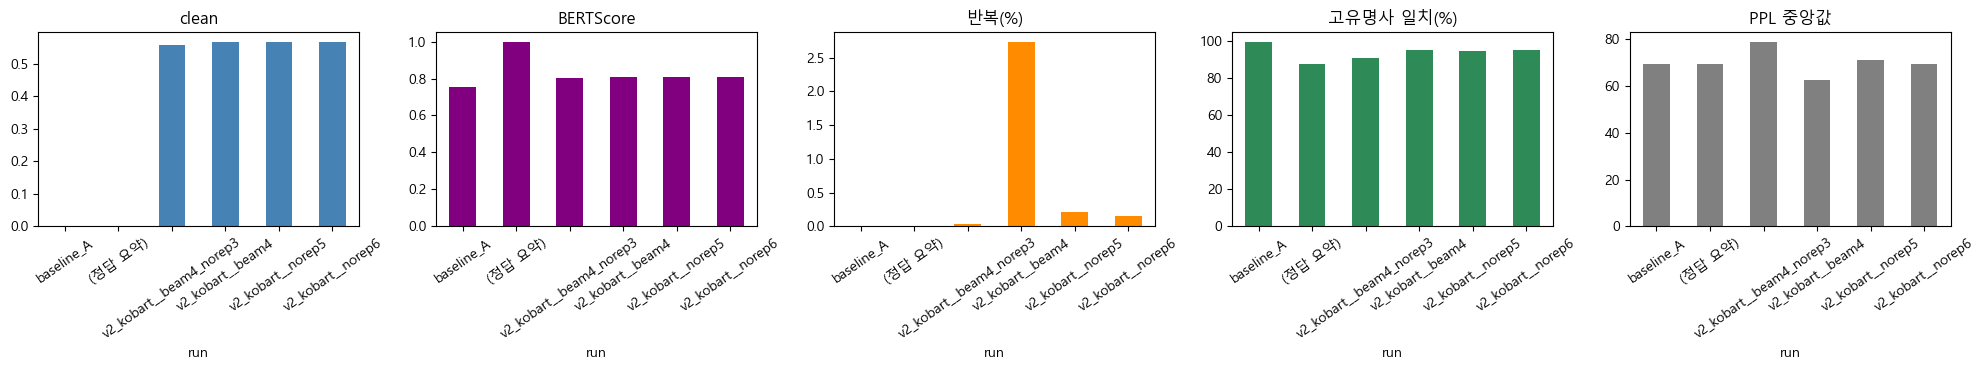

In [2]:
# ============================================================
# [05-3] PPL 보완 + BERTScore 추가
#   대상: 저장된 모든 preds (v0/v1/v2 × beam4·norep3, v2 × norep5·norep6) + 베이스라인 + 정답 요약
#   1) KoGPT2로 PPL (없는 것만) → 모델 내림
#   2) klue/roberta-base로 BERTScore → 모델 내림
#   출력: outputs/05-3_all_metrics.csv, figures/05-3_all_metrics.png, 각 preds에 컬럼 추가
#   필요: pip install bert-score
# ============================================================
import sys, gc, re
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))
from common import *
import torch
from transformers import PreTrainedTokenizerFast, GPT2LMHeadModel
from kiwipiepy import Kiwi

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
test = pd.read_csv(PROC / "test.csv")
docs = test["document"].tolist(); refs = test["summary"].tolist()

# ---------- 대상 모으기 ----------
def lead_n(doc, n): return " ".join(doc.split()[:n])
targets = {"baseline_A": pd.DataFrame({"pred": [lead_n(d, 60) for d in docs]}),
           "(정답 요약)": pd.DataFrame({"pred": refs})}
for p in sorted(OUT.glob("04-4_v*_test_preds.csv")):
    if "quick" in p.name: continue
    targets[p.stem.replace("04-4_", "").replace("_test_preds", "")] = pd.read_csv(p)
print("대상:", list(targets))

# ---------- 1) PPL (KoGPT2) ----------
gpt_tok = PreTrainedTokenizerFast.from_pretrained("skt/kogpt2-base-v2",
            bos_token="</s>", eos_token="</s>", unk_token="<unk>", pad_token="<pad>", mask_token="<mask>")
gpt = GPT2LMHeadModel.from_pretrained("skt/kogpt2-base-v2").to(DEVICE).eval()

def perplexity(texts, batch=8):
    out = []
    for i in range(0, len(texts), batch):
        b = [gpt_tok.bos_token + t + gpt_tok.eos_token for t in texts[i:i+batch]]
        enc = gpt_tok(b, return_tensors="pt", padding=True, truncation=True, max_length=256).to(DEVICE)
        labels = enc["input_ids"].clone(); labels[enc["attention_mask"] == 0] = -100
        with torch.no_grad():
            logits = gpt(**enc).logits[:, :-1]
        tgt = labels[:, 1:]
        nll = torch.nn.functional.cross_entropy(logits.transpose(1, 2), tgt, ignore_index=-100, reduction="none")
        out.extend(torch.exp(nll.sum(1) / (tgt != -100).sum(1).clamp(min=1)).cpu().tolist())
    return np.array(out)

for name, df in targets.items():
    if "ppl" in df and df["ppl"].notna().all():
        print(f"  {name}: PPL 이미 있음"); continue
    df["ppl"] = perplexity(df["pred"].fillna("").astype(str).tolist())
    print(f"  {name}: PPL 계산 완료 (중앙값 {np.median(df['ppl']):.1f})")
del gpt; gc.collect(); torch.cuda.empty_cache()

# ---------- 2) BERTScore (klue/roberta-base) ----------
from bert_score import BERTScorer
scorer = BERTScorer(model_type="klue/roberta-base", num_layers=9, lang="ko",
                    rescale_with_baseline=False, device=DEVICE, batch_size=16)
for name, df in targets.items():
    if name == "(정답 요약)":
        df["bertscore"] = 1.0; continue          # 정답 자기 자신
    _, _, F1 = scorer.score(df["pred"].fillna("").astype(str).tolist(), refs)
    df["bertscore"] = F1.numpy()
    print(f"  {name}: BERTScore {F1.mean():.4f}")
del scorer; gc.collect(); torch.cuda.empty_cache()

# ---------- 3) 사실성 (없는 것만) ----------
_kiwi = Kiwi()
NUM_RE = re.compile(r"\d+(?:[.,]\d+)?")
doc_nums = [set(NUM_RE.findall(d.replace(" ", ""))) for d in docs]
doc_nnps = [{t.form for t in _kiwi.tokenize(d) if t.tag == "NNP"} for d in docs]
for name, df in targets.items():
    if "num_ok" in df and df["num_ok"].notna().all(): continue
    preds = df["pred"].fillna("").astype(str).tolist()
    df["num_ok"] = [set(NUM_RE.findall(p.replace(" ", ""))) <= dn for p, dn in zip(preds, doc_nums)]
    df["nnp_ok"] = [{t.form for t in _kiwi.tokenize(p) if t.tag == "NNP"} <= dp for p, dp in zip(preds, doc_nnps)]

# ---------- 4) 표 ----------
is_noisy = test["is_noisy"].values; in_train = test["in_train"].values
rows = []
for name, df in targets.items():
    r = {"run": name,
         "BERTScore": round(float(df["bertscore"].mean()), 4),
         "PPL 중앙값": round(float(np.median(df["ppl"])), 1),
         "숫자 일치(%)": round(df["num_ok"].mean() * 100, 2),
         "고유명사 일치(%)": round(df["nnp_ok"].mean() * 100, 2),
         "평균 단어": round(df["pred"].fillna("").astype(str).str.split().str.len().mean(), 1)}
    if "rougeL" in df:
        r["rougeL"] = round(df["rougeL"].mean(), 4)
        r["clean"] = round(df.loc[~is_noisy, "rougeL"].mean(), 4)
        r["noleak"] = round(df.loc[~in_train, "rougeL"].mean(), 4)
        r["반복(%)"] = round(df["repeat"].mean() * 100, 2)
    rows.append(r)
    if name not in ["baseline_A", "(정답 요약)"]:
        df.to_csv(OUT / f"04-4_{name}_test_preds.csv", index=False, encoding="utf-8-sig")

cols = ["rougeL", "clean", "noleak", "BERTScore", "반복(%)", "고유명사 일치(%)", "숫자 일치(%)", "PPL 중앙값", "평균 단어"]
res = pd.DataFrame(rows).set_index("run").reindex(columns=cols)
print("\n" + "=" * 100); print("[전체 지표 종합]"); print("=" * 100)
print(res.to_string())
res.to_csv(OUT / "05-3_all_metrics.csv", encoding="utf-8-sig")

# ---------- 5) 그래프: v2 디코딩 4종 + 베이스라인 ----------
pick = [r for r in res.index if r.startswith("v2_kobart") or r in ["baseline_A", "(정답 요약)"]]
sub = res.loc[pick]
fig, ax = plt.subplots(1, 5, figsize=(20, 3.8))
for a, c, col in zip(ax, ["steelblue", "purple", "darkorange", "seagreen", "gray"],
                     ["clean", "BERTScore", "반복(%)", "고유명사 일치(%)", "PPL 중앙값"]):
    sub[col].plot.bar(ax=a, rot=35, color=c); a.set_title(col)
plt.tight_layout(); plt.savefig(FIG / "05-3_all_metrics.png", dpi=130); plt.show()

---
# 8. 노이즈 항목별 분해

v2는 6항목을 한꺼번에 뺐습니다. 어느 항목이 무엇을 담당했는지 하나씩 분리했습니다.
(데이터 생성은 2-3, 학습은 4-3의 자동 실행에서 수행)

## 결과 (디코딩 beam4)

| 버전 | 뺀 항목 | 제거 | 반복률 | 변화 | 광고문구율 | 변화 | clean |
|---|---|---|---|---|---|---|---|
| v1 | 없음 (기준) | 0 | 6.17% | — | 0.91% | — | 0.5665 |
| v2a | 반복 | 1,224 | **2.48%** | **−3.69** | 1.17% | **+0.26** | 0.5648 |
| v2b | 길이 | 857 | 4.05% | −2.12 | 1.24% | **+0.33** | 0.5643 |
| v2c | 광고 | 113 | 6.24% | +0.07 | **0.11%** | **−0.80** | 0.5628 |
| v2 | 전부 | 1,665 | 2.74% | −3.43 | **0.11%** | **−0.80** | 0.5659 |

## 알게 된 것

### ① 반복률은 반복 항목이 담당한다

v2a 단독으로 −3.69%p입니다. 6항목을 다 뺀 v2(−3.43%p)보다도 큽니다.
길이 항목(v2b, −2.12%p)도 효과가 있는데, 이는 **길이 역전 기사의 51%가 반복 기사이기도 하기 때문**입니다. 두 항목은 독립적이지 않습니다.

### ② 광고 문구는 광고 항목만 담당한다

v2c가 113건(0.6%)만 뺐는데 광고문구율이 0.91% → 0.11%로 떨어졌습니다. v2와 정확히 같은 값입니다.

### ③ 부분 제거는 오히려 위험할 수 있다 — 예상 밖의 발견

**v2a와 v2b에서 광고문구율이 오히려 늘었습니다** (0.91% → 1.17%, 1.24%).

광고 문구가 있는 기사 중 일부는 반복·길이 문제도 함께 갖고 있었는데(겹침 23+23건), 그것들이 v2a·v2b에서 빠졌습니다.
남은 광고 기사는 **"다른 문제 없이 광고만 있는" 깨끗한 기사**들이라, 모델이 그 패턴을 더 선명하게 학습한 것으로 보입니다.

> **노이즈를 부분적으로만 제거하면, 남은 노이즈가 더 강하게 학습될 수 있습니다.**

### ④ 따라서 v2(전부 제거)가 최선이다

v2만 두 지표를 동시에 낮춥니다. 어느 하나만 빼면 다른 쪽이 남거나 오히려 나빠집니다.

### ⑤ 요약 실력 자체는 데이터 정리에 둔감하다

clean 점수가 다섯 버전 모두 0.563~0.568로 0.005 안쪽입니다. **바뀌는 것은 "버릇"이지 "실력"이 아닙니다.**

### ⑥ 얼리스타핑 가설이 세 번째로 확인됐다

| 버전 | 최적 지점 | 반복 요약을 뺐나 |
|---|---|---|
| v1 | 2,400 (1.9 ep) | 아니오 |
| **v2c** | **2,400 (1.9 ep)** | **아니오 (113건만)** |
| v2a / v2b / v2 | 3,400 (2.9~3.0 ep) | 예 |

v2c가 v1과 **정확히 같은 지점**에서 멈췄습니다. 113건으로는 검증 난이도가 바뀌지 않았습니다. 5장의 결론이 재확인됐습니다.

---
# 9. 하이퍼파라미터

학습률과 epoch를 비교합니다. 데이터는 v2, 디코딩은 6단어 금지로 고정했습니다.

| 실험 | 학습률 | 최대 epoch | 확인하려는 것 |
|---|---|---|---|
| 기존 | 3e-5 | 3 | 기준점 |
| ① | 1e-5 | 5 | 세 학습률을 같은 조건에서 비교 |
| ② | 3e-5 | 5 | ↑ + 기존과 비교하면 epoch 효과 |
| ③ | 5e-5 | 5 | ↑ |

In [13]:
import shutil

In [14]:
# ============================================================
# [04-7] 하이퍼파라미터 실험: 학습률 3종 × max_epoch 5
#   데이터 v2 고정, 디코딩 norep6 고정, 학습률만 변경
#   기존 v2(lr 3e-5, max_epoch 3)와 비교하면 epoch 효과도 확인 가능
#   실험 하나가 실패해도 다음으로 진행
# ============================================================
import copy

LR_LIST = [1e-5, 3e-5, 5e-5]
HP_VERSION = "v2"
HP_DECODING = {"norep6": dict(num_beams=4, no_repeat_ngram_size=6)}
CFG_BASE = copy.deepcopy(CFG)

status(f"===== 하이퍼파라미터 실험 시작: lr={LR_LIST}, max_epoch=5, data={HP_VERSION} =====")
for lr in LR_LIST:
    tag = f"lr{lr:.0e}".replace("-0", "-")          # lr1e-5 형태
    try:
        CFG.clear()
        CFG.update({**CFG_BASE, "lr": lr, "max_epochs": 5})
        status(f"--- {tag}: lr={lr}, max_epochs=5 ---")

        model, tok, info = train_version(HP_VERSION)
        run = f"{HP_VERSION}_kobart_{tag}"
        info["run"] = run
        # 모델 폴더 이름이 겹치지 않도록 이동
        src = ROOT / "models" / f"{HP_VERSION}_kobart"
        dst = ROOT / "models" / run
        if src.exists() and src != dst:
            if dst.exists(): shutil.rmtree(dst)
            shutil.move(str(src), str(dst))

        for gen_name, gen_cfg in HP_DECODING.items():
            t0 = time.time()
            preds = generate_all(model, tok, test_docs, gen_cfg)
            score, _ = evaluate_and_log(preds, run, HP_VERSION, info, gen_name, gen_cfg,
                                        (time.time() - t0) / 60, save_preds=True)
            status(f"{run} [{gen_name}] R-L {score['rougeL']:.4f} | clean {score['rougeL_clean']:.4f} | "
                   f"반복 {score['repeat_rate']}% | 길이 {score['avg_words']} | "
                   f"best step {info['best_step']} ({info['epochs_done']} ep)")
        del model; gc.collect()
        torch.cuda.empty_cache() if DEVICE == "cuda" else None
    except Exception as e:
        status(f"{tag}: 실패 — {type(e).__name__}: {e}")
        open(STATUS, "a", encoding="utf-8").write(traceback.format_exc() + "\n")
        gc.collect(); torch.cuda.empty_cache() if DEVICE == "cuda" else None

CFG.clear(); CFG.update(CFG_BASE)                    # 원래 설정 복구
status("===== 하이퍼파라미터 실험 완료 =====")

[09-20 22:40:24] ===== 하이퍼파라미터 실험 시작: lr=[1e-05, 3e-05, 5e-05], max_epoch=5, data=v2 =====
[09-20 22:40:24] --- lr1e-5: lr=1e-05, max_epochs=5 ---


You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
c:\Users\wm032\Documents\news_summary\.venv\Lib\site-packages\transformers\tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(
You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


Map:   0%|          | 0/18150 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

[09-20 22:40:35] v2_kobart: train 18,150 | val 500 | 정답 끝 토큰 = ['</s>']


...

{'eval_loss': 0.4536748230457306, 'eval_runtime': 2.6025, 'eval_samples_per_second': 192.126, 'eval_steps_per_second': 12.296, 'epoch': 2.46804759806082}


There were missing keys in the checkpoint model loaded: ['model.encoder.embed_tokens.weight', 'model.decoder.embed_tokens.weight', 'lm_head.weight'].
Some non-default generation parameters are set in the model config. These should go into a GenerationConfig file (https://huggingface.co/docs/transformers/generation_strategies#save-a-custom-decoding-strategy-with-your-model) instead. This warning will be raised to an exception in v4.41.
Non-default generation parameters: {'forced_eos_token_id': 1}


{'train_runtime': 995.4604, 'train_samples_per_second': 91.164, 'train_steps_per_second': 5.696, 'train_loss': 0.49760232652936665, 'epoch': 2.46804759806082}
[09-21 00:23:37] v2_kobart: 학습 완료 17분, 2800 step, best step 2200 (val loss 0.4425)


c:\Users\wm032\Documents\news_summary\common.py:66: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  row = pd.concat([pd.read_csv(path), row], ignore_index=True)


[09-21 00:43:40] v2_kobart_lr5e-5 [norep6] R-L 0.5584 | clean 0.5557 | 반복 0.58% | 길이 44.2 | best step 2200 (2.47 ep)
[09-21 00:43:41] ===== 하이퍼파라미터 실험 완료 =====


## 9-1. 결과

| 설정 | best step | val loss | clean | noleak | 반복률 |
|---|---|---|---|---|---|
| **3e-5 / max_ep 3 (기존)** | 3,400 (3.0 ep) | **0.4385** | **0.5684** | **0.5632** | **0.15%** |
| 1e-5 / max_ep 5 | 5,400 (5.0 ep) | 0.4500 | 0.5636 | 0.5580 | 0.36% |
| 3e-5 / max_ep 5 | 2,200 (2.47 ep) | 0.4429 | 0.5577 | 0.5525 | 0.36% |
| 5e-5 / max_ep 5 | 2,200 (2.47 ep) | 0.4425 | 0.5557 | 0.5505 | 0.58% |

### ① 학습률에 둔감하다

세 학습률의 검증 loss 차이가 최대 0.0075입니다. 3e-5와 5e-5는 0.0004 차이로 사실상 같습니다.

### ② 1e-5는 너무 낮다

| epoch | 1e-5 | 3e-5 |
|---|---|---|
| 1 | 0.501 | 0.468 |
| 2 | 0.469 | 0.446 |
| 3 | 0.455 | **0.439** |
| 4 | 0.452 | — |
| 5 | 0.450 | — |

**5 epoch를 모두 사용하고도 3e-5의 3 epoch를 못 따라잡았습니다.** 학습 시간은 1.7배 걸렸습니다.

### ③ 5e-5는 과적합이 가장 빠르다

| lr | 2.47 epoch의 train loss |
|---|---|
| 1e-5 | 0.43 |
| 3e-5 | 0.32 |
| **5e-5** | **0.27** |

학습률이 높을수록 train을 더 외웠는데 검증 loss는 셋 다 비슷했습니다. **외운 만큼 새 데이터에 도움이 안 됐습니다.**

`grad_norm`은 세 조건 모두 1.6~3.4로 안정적이었습니다. 5e-5도 KoBART에는 감당 가능한 범위였습니다.

### ④ max_epoch는 상한이 아니라 학습률 스케줄 설정이다 — 실험 설계의 함정

동일한 3e-5에서 max_epoch만 3→5로 바꾸자 성능이 **하락**했습니다 (0.5684 → 0.5577).

학습률은 고정값이 아니라 총 step 수에 맞춰 감쇠하는 곡선입니다.

| | max_epoch 3 | max_epoch 5 |
|---|---|---|
| 예정 총 step | 3,402 | 5,670 |
| 2,200 step 시점 학습률 | 약 1.0e-5 | **약 1.85e-5** |

같은 2,200 step이어도 max_epoch 5에서는 학습률이 아직 높아 **덜 수렴한 상태**이고, 얼리스타핑이 그 지점을 최적으로 잡았습니다.

> **"한 번에 하나만 변경한다"는 원칙을 지켰다고 생각했으나, 하이퍼파라미터 간 상호작용으로 실제로는 두 변수가 동시에 바뀐 사례입니다.**
> epoch 효과는 학습률 스케줄과 분리해서 측정하지 못했으며, 이는 한계로 기록합니다.

---
# 10. 스플릿 비율

train:val 비율을 바꿔 학습 데이터 양의 영향을 확인합니다. test는 고정이며, 학습 조건은 기존 v2와 동일(lr 3e-5, max_epoch 3)합니다.

In [16]:
# ============================================================
# [04-9] 스플릿 비율 실험 자동 실행
#   v2_s80(80:20), v2_s70(70:30)을 순서대로 학습·평가
#   기존 v2(약 90:10)와 같은 조건: lr 3e-5, max_epoch 3, norep6
#   실패해도 다음 버전 계속 진행
# ============================================================
import copy, shutil

SPLIT_VERSIONS = ["v2_s80", "v2_s70"]
SPLIT_DECODING = {"norep6": dict(num_beams=4, no_repeat_ngram_size=6)}
CFG_SAVE = copy.deepcopy(CFG)

# 기존 v2와 동일 조건으로 고정 (max_epochs=3 이 중요)
CFG.clear()
CFG.update(dict(lr=3e-5, max_epochs=3, batch=4, grad_accum=4,
                eval_steps=200, patience=3, n_train=None))

status(f"===== 스플릿 비율 실험 시작: {SPLIT_VERSIONS}, cfg={CFG} =====")
for version in SPLIT_VERSIONS:
    try:
        model, tok, info = train_version(version)
        run = info["run"]
        for gen_name, gen_cfg in SPLIT_DECODING.items():
            t0 = time.time()
            preds = generate_all(model, tok, test_docs, gen_cfg)
            score, _ = evaluate_and_log(preds, run, version, info, gen_name, gen_cfg,
                                        (time.time() - t0) / 60, save_preds=True)
            status(f"{run} [{gen_name}] R-L {score['rougeL']:.4f} | clean {score['rougeL_clean']:.4f} | "
                   f"반복 {score['repeat_rate']}% | 길이 {score['avg_words']} | "
                   f"best step {info['best_step']} ({info['epochs_done']} ep)")
        del model; gc.collect()
        torch.cuda.empty_cache() if DEVICE == "cuda" else None
    except Exception as e:
        status(f"{version}: 실패 — {type(e).__name__}: {e}")
        open(STATUS, "a", encoding="utf-8").write(traceback.format_exc() + "\n")
        gc.collect(); torch.cuda.empty_cache() if DEVICE == "cuda" else None

CFG.clear(); CFG.update(CFG_SAVE)
status("===== 스플릿 비율 실험 완료 =====")

[09-21 00:45:47] ===== 스플릿 비율 실험 시작: ['v2_s80', 'v2_s70'], cfg={'lr': 3e-05, 'max_epochs': 3, 'batch': 4, 'grad_accum': 4, 'eval_steps': 200, 'patience': 3, 'n_train': None} =====


You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
c:\Users\wm032\Documents\news_summary\.venv\Lib\site-packages\transformers\tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(
You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


Map:   0%|          | 0/16187 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

[09-21 00:45:56] v2_s80_kobart: train 16,187 | val 500 | 정답 끝 토큰 = ['</s>']


...

{'eval_loss': 0.45365968346595764, 'eval_runtime': 2.9939, 'eval_samples_per_second': 167.008, 'eval_steps_per_second': 10.689, 'epoch': 2.9370234397062975}
{'loss': 0.3244, 'grad_norm': 1.7897331714630127, 'learning_rate': 1.070578905630452e-07, 'epoch': 2.9935046597006494}


Some non-default generation parameters are set in the model config. These should go into a GenerationConfig file (https://huggingface.co/docs/transformers/generation_strategies#save-a-custom-decoding-strategy-with-your-model) instead. This warning will be raised to an exception in v4.41.
Non-default generation parameters: {'forced_eos_token_id': 1}
There were missing keys in the checkpoint model loaded: ['model.encoder.embed_tokens.weight', 'model.decoder.embed_tokens.weight', 'lm_head.weight'].
Some non-default generation parameters are set in the model config. These should go into a GenerationConfig file (https://huggingface.co/docs/transformers/generation_strategies#save-a-custom-decoding-strategy-with-your-model) instead. This warning will be raised to an exception in v4.41.
Non-default generation parameters: {'forced_eos_token_id': 1}


{'train_runtime': 923.5813, 'train_samples_per_second': 46.005, 'train_steps_per_second': 2.875, 'train_loss': 0.5027309849661847, 'epoch': 2.9991527817000847}
[09-21 01:33:31] v2_s70_kobart: 학습 완료 15분, 2655 step, best step 2600 (val loss 0.4537)


c:\Users\wm032\Documents\news_summary\common.py:66: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  row = pd.concat([pd.read_csv(path), row], ignore_index=True)


[09-21 01:50:33] v2_s70_kobart [norep6] R-L 0.5641 | clean 0.5646 | 반복 0.11% | 길이 40.8 | best step 2600 (3.0 ep)
[09-21 01:50:33] ===== 스플릿 비율 실험 완료 =====


## 10-1. 결과 (디코딩 norep6)

| 비율 | train | clean | noleak | 반복률 | best step |
|---|---|---|---|---|---|
| **90:10 (v2)** | 18,150 | **0.5684** | **0.5632** | 0.15% | 3,400 (3.0 ep) |
| 80:20 | 16,187 | 0.5657 | 0.5607 | 0.18% | 3,000 (3.0 ep) |
| 70:30 | 14,163 | 0.5646 | 0.5591 | 0.11% | 2,600 (3.0 ep) |

**학습 데이터를 22% 줄였는데 clean이 0.0038밖에 떨어지지 않았습니다.**

이는 데이터 버전 실험과 일치합니다.

| 비교 | train 감소 | clean 변화 |
|---|---|---|
| v0 → v2 | −4,044 (18%) | −0.0005 (변화 없음) |
| v2 → s70 | −3,987 (22%) | −0.0038 |

→ **데이터 양이 성능을 좌우하는 구간을 이미 지났습니다.** 14,000건이면 이 과제에 충분합니다.

세 비율 모두 **3 epoch를 완주**했습니다. 비율을 바꿔도 "3 epoch가 최적"이라는 패턴은 유지됐습니다.

> 검증 loss는 90:10이 0.4385, 70:30이 0.4537로 차이가 나지만, **검증셋이 다르므로 비교할 수 없습니다**(5장).
> clean·noleak으로 판단해야 합니다.

---
# 11. 전체 비교표

실험 23회의 결과를 한곳에 모읍니다.

In [18]:
p = OUT / "04-4_v2_kobart__norep6_test_preds.csv"
print("파일 존재:", p.exists())
if p.exists():
    d = pd.read_csv(p)
    print("컬럼:", list(d.columns))
    print("행 수:", len(d))

파일 존재: True
컬럼: ['rouge1', 'rouge2', 'rougeL', 'rougeL_space', 'pred_len', 'pred_words', 'repeat', 'empty', 'copy_rate', 'in_train', 'is_noisy', 'category', 'pred', 'ref', 'num_ok', 'nnp_ok', 'first_word_ok', 'ppl', 'bertscore']
행 수: 2740


In [20]:
# v2 norep6 누락 지표 계산 (저장된 예측 재사용, 생성 불필요)
test = pd.read_csv(PROC / "test.csv")
d = pd.read_csv(OUT / "04-4_v2_kobart__norep6_test_preds.csv")
d["in_train"] = test["in_train"].values
d["is_noisy"] = test["is_noisy"].values

row = {
    "exp": "v2_kobart__norep6", "data": "v2", "model": "kobart", "decoding": "norep6",
    "rougeL": round(d["rougeL"].mean(), 4),
    "rougeL_clean": round(d.loc[~d["is_noisy"].astype(bool), "rougeL"].mean(), 4),
    "rougeL_noleak": round(d.loc[~d["in_train"].astype(bool), "rougeL"].mean(), 4),
    "rouge1": round(d["rouge1"].mean(), 4), "rouge2": round(d["rouge2"].mean(), 4),
    "avg_words": round(d["pred_words"].mean(), 1),
    "repeat_rate": round(d["repeat"].mean() * 100, 2),
    "copy_rate": round(d["copy_rate"].mean(), 4),
    "best_step": 3400, "epochs_done": 3.0, "n_train": 18150,
}
if "boiler" in d: row["boiler_rate"] = round(d["boiler"].mean() * 100, 2)
if "first_word_ok" in d: row["first_word_bad"] = round((~d["first_word_ok"].astype(bool)).mean() * 100, 2)

log_experiment(row)
print(pd.Series(row).to_string())

exp               v2_kobart__norep6
data                             v2
model                        kobart
decoding                     norep6
rougeL                       0.5685
rougeL_clean                 0.5684
rougeL_noleak                0.5632
rouge1                       0.6529
rouge2                       0.5449
avg_words                      41.7
repeat_rate                    0.15
copy_rate                    0.9449
best_step                      3400
epochs_done                     3.0
n_train                       18150
first_word_bad                  5.4



[표 1-beam4] 데이터 버전 비교
            rougeL  rougeL_clean  rougeL_noleak  rouge1  rouge2  avg_words  repeat_rate  boiler_rate  first_word_bad  copy_rate  best_step  epochs_done
version                                                                                                                                                
v0          0.5743        0.5654         0.5552  0.6534  0.5495       44.8         7.04         0.88            6.64     0.9460     2600.0         2.31
v1          0.5653        0.5665         0.5624  0.6450  0.5403       43.8         6.17         0.91            4.74     0.9516     2400.0         2.42
v2          0.5692        0.5659         0.5620  0.6516  0.5443       43.6         2.74         0.11            5.36     0.9495     3400.0         3.00
v2a         0.5702        0.5648         0.5615  0.6525  0.5452       43.6         2.48         1.17            6.35     0.9471     3400.0         3.00
v2b         0.5688        0.5643         0.5611  0.6519  0.5452  

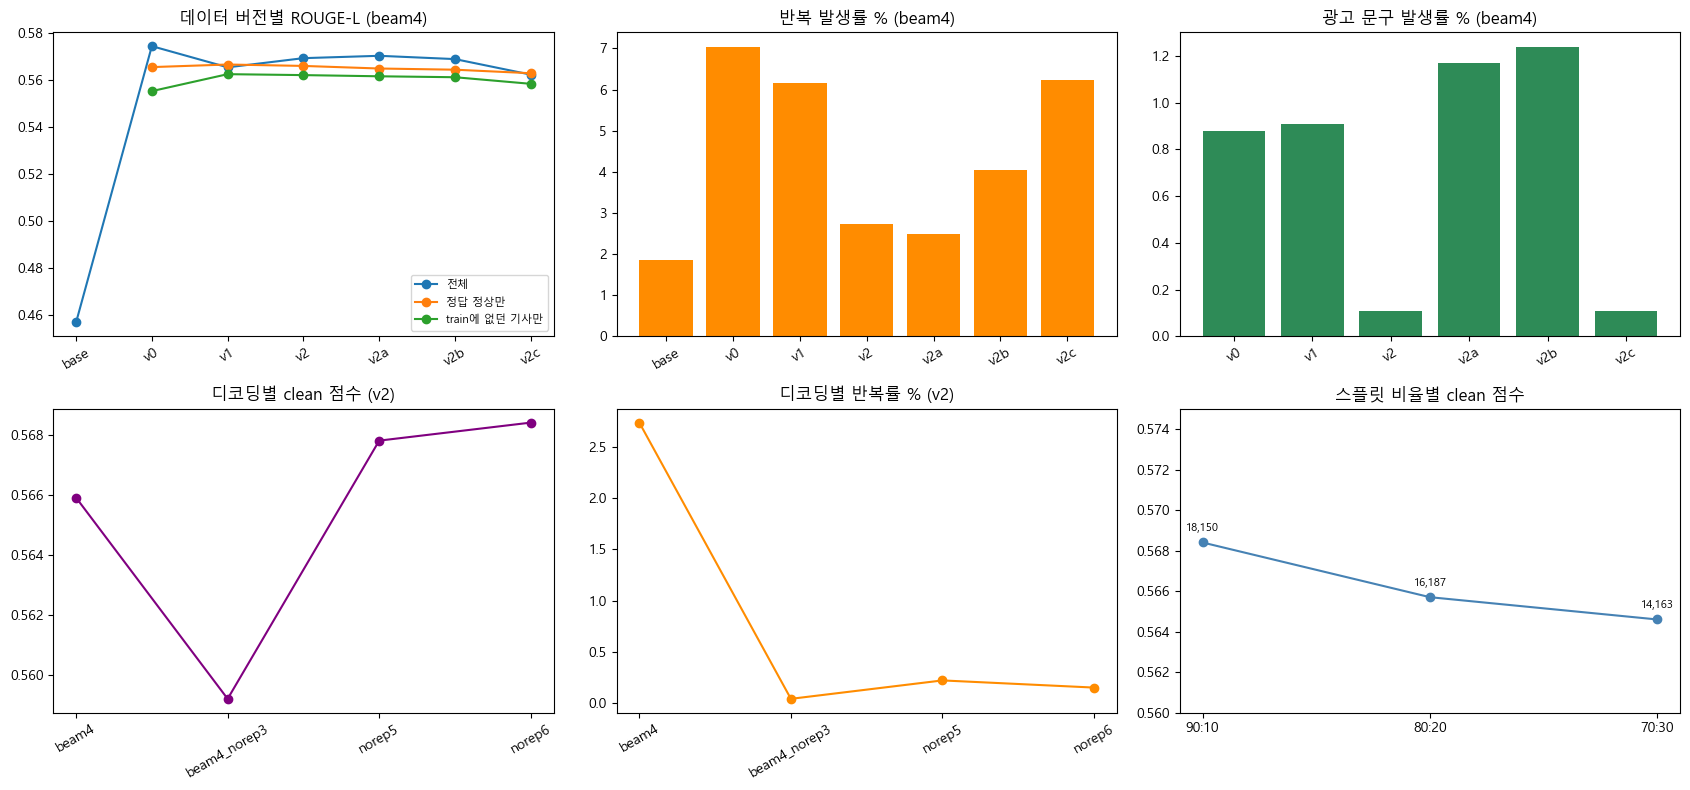

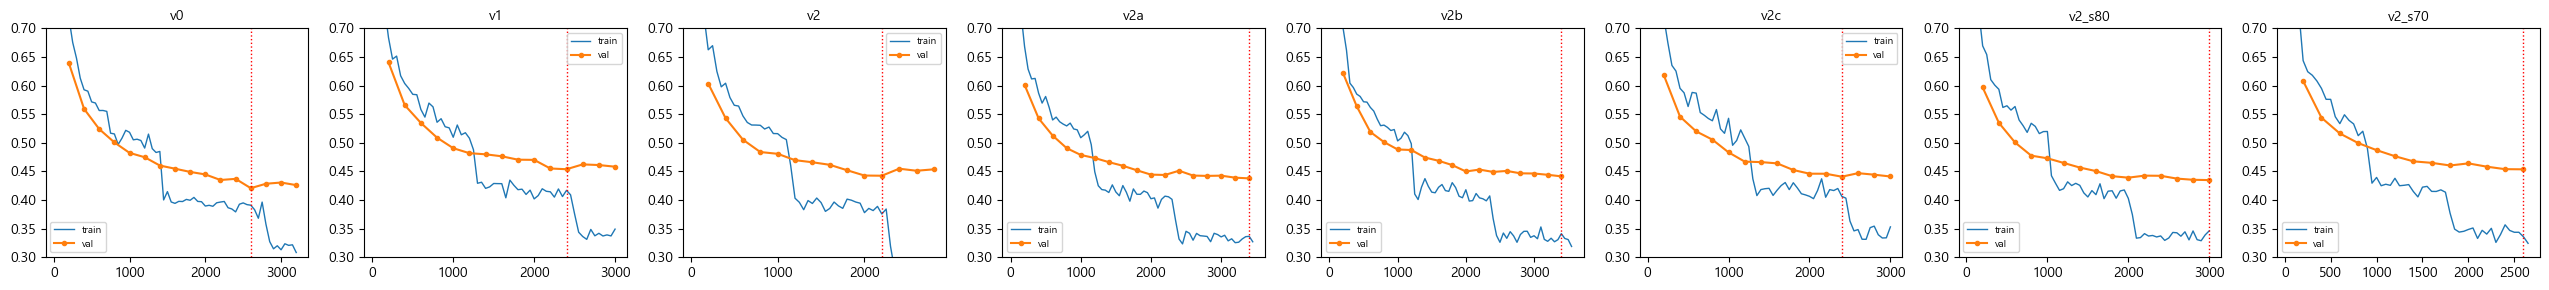

In [21]:
# ============================================================
# [04-10] 전체 비교표 (최종)
#   데이터 버전 8종 + 하이퍼파라미터 3종 + 디코딩 7종
# ============================================================
logdf = pd.read_csv(ROOT / "experiment_log.csv").drop_duplicates("exp", keep="last")
base = logdf[logdf["model"] == "lead-N"].iloc[0]
runs = logdf[(logdf["model"] == "kobart") & ~logdf["exp"].str.contains("quick")].copy()

# 하이퍼파라미터 실험은 exp 이름으로 구분 (data 컬럼이 전부 v2라서)
runs["version"] = runs.apply(
    lambda r: r["exp"].split("__")[0].replace("_kobart", "") if "_lr" in r["exp"] else r["data"], axis=1)
runs = runs.drop_duplicates(["version", "decoding"], keep="last")

VER_ORDER = ["v0", "v1", "v2", "v2a", "v2b", "v2c", "v2_s80", "v2_s70"]
HP_ORDER  = ["v2", "v2_lr1e-5", "v2_lr3e-5", "v2_lr5e-5"]
DEC_ORDER = ["beam4", "greedy", "beam8_norep3", "beam4_norep3", "beam4_norep3_lp08", "norep5", "norep6"]
cols = ["rougeL", "rougeL_clean", "rougeL_noleak", "rouge1", "rouge2",
        "avg_words", "repeat_rate", "boiler_rate", "first_word_bad", "copy_rate", "best_step", "epochs_done"]

def show(df, title, path=None):
    print("\n" + "=" * 104); print(title); print("=" * 104)
    print(df.round(4).to_string())
    if path: df.to_csv(OUT / path, encoding="utf-8-sig")

# ---------- 표 1: 데이터 버전 (디코딩별) ----------
for dec in ["beam4", "norep6"]:
    t = runs[runs["decoding"] == dec].set_index("version").reindex(VER_ORDER)
    t = t[[c for c in cols if c in t.columns]].dropna(how="all")
    t.loc["baseline_A"] = base.reindex(t.columns)
    show(t, f"[표 1-{dec}] 데이터 버전 비교", f"04-10_versions_{dec}.csv")

# ---------- 표 2: 노이즈 항목별 기여 ----------
b4 = runs[runs["decoding"] == "beam4"].set_index("version")
NAMES = {"v2a": "반복 2항목", "v2b": "길이 2항목", "v2c": "광고 문구", "v2": "6항목 전부"}
n_tr = {v: len(pd.read_csv(PROC / f"{v}_train.csv")) for v in ["v1"] + list(NAMES)}
rows = [{"버전": v, "뺀 항목": "없음 (기준)" if v == "v1" else NAMES[v],
         "train": n_tr[v], "제거": n_tr["v1"] - n_tr[v],
         "반복률": b4.loc[v, "repeat_rate"],
         "반복 변화": round(b4.loc[v, "repeat_rate"] - b4.loc["v1", "repeat_rate"], 2),
         "광고문구율": b4.loc[v, "boiler_rate"],
         "광고 변화": round(b4.loc[v, "boiler_rate"] - b4.loc["v1", "boiler_rate"], 2),
         "clean": b4.loc[v, "rougeL_clean"], "noleak": b4.loc[v, "rougeL_noleak"]}
        for v in ["v1"] + [k for k in NAMES if k in b4.index]]
show(pd.DataFrame(rows).set_index("버전"), "[표 2] 노이즈 항목별 기여 (v1 대비, beam4)", "04-10_ablation.csv")

# ---------- 표 3: 스플릿 비율 ----------
n6 = runs[runs["decoding"] == "norep6"].set_index("version")
sp = [v for v in ["v2", "v2_s80", "v2_s70"] if v in n6.index]
t3 = n6.loc[sp, [c for c in ["rougeL", "rougeL_clean", "rougeL_noleak", "repeat_rate", "avg_words", "best_step", "epochs_done"] if c in n6.columns]]
t3.insert(0, "train", [len(pd.read_csv(PROC / f"{v}_train.csv")) for v in sp])
t3.insert(1, "비율", ["90:10", "80:20", "70:30"][:len(sp)])
show(t3, "[표 3] 스플릿 비율 (디코딩 norep6)", "04-10_split.csv")

# ---------- 표 4: 하이퍼파라미터 ----------
hp = [v for v in HP_ORDER if v in n6.index]
if hp:
    t4 = n6.loc[hp, [c for c in ["rougeL", "rougeL_clean", "rougeL_noleak", "repeat_rate", "avg_words", "best_step", "epochs_done"] if c in n6.columns]]
    t4.insert(0, "설정", ["lr 3e-5 / max_ep 3 (기준)", "lr 1e-5 / max_ep 5",
                        "lr 3e-5 / max_ep 5", "lr 5e-5 / max_ep 5"][:len(hp)])
    show(t4, "[표 4] 하이퍼파라미터 (데이터 v2, 디코딩 norep6)", "04-10_hparam.csv")

# ---------- 표 5: 디코딩 ----------
t5 = runs[runs["version"] == "v2"].set_index("decoding").reindex(DEC_ORDER).dropna(how="all")
t5 = t5[[c for c in ["rougeL", "rougeL_clean", "repeat_rate", "avg_words", "gen_min"] if c in t5.columns]]
show(t5, "[표 5] 디코딩 전략 (데이터 v2)", "04-10_decoding.csv")

# ---------- 그래프 ----------
fig, ax = plt.subplots(2, 3, figsize=(17, 8))
present = [v for v in VER_ORDER if v in b4.index]
x = ["base"] + present
for k, lab in [("rougeL", "전체"), ("rougeL_clean", "정답 정상만"), ("rougeL_noleak", "train에 없던 기사만")]:
    ax[0, 0].plot(x, [base[k]] + b4.loc[present, k].tolist(), "o-", label=lab)
ax[0, 0].set_title("데이터 버전별 ROUGE-L (beam4)"); ax[0, 0].legend(fontsize=8); ax[0, 0].tick_params(axis="x", rotation=30)

ax[0, 1].bar(x, [base["repeat_rate"]] + b4.loc[present, "repeat_rate"].tolist(), color="darkorange")
ax[0, 1].set_title("반복 발생률 % (beam4)"); ax[0, 1].tick_params(axis="x", rotation=30)

ax[0, 2].bar(present, b4.loc[present, "boiler_rate"], color="seagreen")
ax[0, 2].set_title("광고 문구 발생률 % (beam4)"); ax[0, 2].tick_params(axis="x", rotation=30)

t5p = t5.dropna(subset=["rougeL_clean"])
ax[1, 0].plot(t5p.index, t5p["rougeL_clean"], "o-", color="purple")
ax[1, 0].set_title("디코딩별 clean 점수 (v2)"); ax[1, 0].tick_params(axis="x", rotation=30)
ax[1, 1].plot(t5p.index, t5p["repeat_rate"], "o-", color="darkorange")
ax[1, 1].set_title("디코딩별 반복률 % (v2)"); ax[1, 1].tick_params(axis="x", rotation=30)

ax[1, 2].plot(t3["비율"], t3["rougeL_clean"], "o-", color="steelblue")
ax[1, 2].set_title("스플릿 비율별 clean 점수"); ax[1, 2].set_ylim(0.56, 0.575)
for i, (r, c, n) in enumerate(zip(t3["비율"], t3["rougeL_clean"], t3["train"])):
    ax[1, 2].annotate(f"{n:,}", (i, c), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "04-10_compare.png", dpi=130); plt.show()

# ---------- 학습 곡선 ----------
logs = {v: pd.read_csv(OUT / f"04-3_{v}_kobart_train_log.csv") for v in VER_ORDER
        if (OUT / f"04-3_{v}_kobart_train_log.csv").exists()}
if logs:
    n = len(logs); fig, ax = plt.subplots(1, n, figsize=(3.2 * n, 3), squeeze=False)
    for a, (v, lg) in zip(ax[0], logs.items()):
        tr = lg[lg["loss"].notna()]; ev = lg[lg["eval_loss"].notna()]
        a.plot(tr["step"], tr["loss"], label="train", lw=1)
        a.plot(ev["step"], ev["eval_loss"], "o-", label="val", ms=3)
        a.axvline(ev.loc[ev["eval_loss"].idxmin(), "step"], color="red", ls=":", lw=1)
        a.set_ylim(0.3, 0.7); a.set_title(v, fontsize=10); a.legend(fontsize=7)
    plt.tight_layout(); plt.savefig(FIG / "04-10_loss_curves.png", dpi=130); plt.show()

## 11-1. 학습 곡선 8개에서 읽을 것

빨간 점선(최적 지점)의 위치가 두 그룹으로 갈립니다.

| 그룹 | 최적 지점 | 노이즈를 뺐나 |
|---|---|---|
| v0, v1, v2c | 곡선 중간 — 검증선이 반등 | 아니오 |
| v2, v2a, v2b, s80, s70 | 끝부분 — 검증선이 평평하게 지속 | 예 |

train loss는 계속 내려가는데 val loss가 올라가는 구간이 **과적합**이며, 얼리스타핑이 그 직전에서 멈췄습니다.

> **주의** — 학습 곡선의 **v2 칸은 최종 모델이 아니라 하이퍼파라미터 실험(lr 5e-5) 기록**입니다. 9장 실험이 같은 파일 이름(`04-3_v2_kobart_train_log.csv`)에 덮어썼습니다. 최종 모델(lr 3e-5, epoch 3)의 수치(best 3,400 step, val loss 0.4385)는 실행 로그(`04_run_status.txt`)와 `experiment_log.csv`에 남아 있습니다.

---
# 12. 오류분석

최종 모델(v2 + norep6)의 요약 2,740건을 유형별로 분류하고, 사례를 직접 확인했습니다.

## 12-1. 자동 검출과 통계

| 유형 | 검출 기준 | 성격 |
|---|---|---|
| 숫자 오류 | 요약 숫자 ⊄ 원문 | 모델 오류 |
| 이름 오류 | 요약 고유명사 ⊄ 원문 | 모델 오류 |
| 반복 | 3단어 묶음 3회 이상 | 모델 오류 |
| 첫 단어 깨짐 | 첫 단어가 원문에 없음 | 모델 오류 |
| 문장 어색 | 퍼플렉시티 상위 5% | 모델 오류 (상대 기준) |
| **정답 문제** | 정답 요약 자체가 망가짐 | **모델 잘못 아님** |

In [2]:
# ============================================================
# [05-4] 오류분석 ① 자동 검출과 통계
#   최종 모델(v2_kobart, norep6)의 요약 2,740건을 유형별로 분류
#   출력: outputs/05-4_error_detail.csv (행별 유형 표시)
# ============================================================
import sys, re
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))
from common import *
from kiwipiepy import Kiwi

RUN = "v2_kobart__norep6"
test = pd.read_csv(PROC / "test.csv")
d = pd.read_csv(OUT / f"04-4_{RUN}_test_preds.csv")
d["document"] = test["document"].values
d["title"] = test["title"].values
d["press"] = test["press"].values
d["ref"] = test["summary"].values
print(f"{RUN}: {len(d):,}건 | 컬럼: {[c for c in d.columns if c not in ['document','pred','ref','title']]}")

# ---------- 없는 지표 보충 ----------
_kiwi = Kiwi()
NUM_RE = re.compile(r"\d+(?:[.,]\d+)?")
preds = d["pred"].fillna("").astype(str).tolist()
docs  = d["document"].tolist()

if "num_ok" not in d:
    d["num_ok"] = [set(NUM_RE.findall(p.replace(" ", ""))) <= set(NUM_RE.findall(doc.replace(" ", "")))
                   for p, doc in zip(preds, docs)]
if "nnp_ok" not in d:
    nnp = lambda t: {tk.form for tk in _kiwi.tokenize(t) if tk.tag == "NNP"}
    d["nnp_ok"] = [nnp(p) <= nnp(doc) for p, doc in zip(preds, docs)]
if "first_word_ok" not in d:
    d["first_word_ok"] = [(p.split()[0] in doc) if p.split() else False for p, doc in zip(preds, docs)]

# ---------- 오류 유형 정의 ----------
d["E_숫자오류"]   = ~d["num_ok"].astype(bool)
d["E_이름오류"]   = ~d["nnp_ok"].astype(bool)
d["E_반복"]       = d["repeat"].astype(bool)
d["E_첫단어깨짐"] = ~d["first_word_ok"].astype(bool)
if "ppl" in d:
    d["E_문장어색"] = d["ppl"] >= d["ppl"].quantile(0.95)
else:
    d["E_문장어색"] = False
d["E_정답문제"]   = d["is_noisy"].astype(bool)
d["E_점수낮음"]   = d["rougeL"] < 0.3

ETYPES = ["E_숫자오류", "E_이름오류", "E_반복", "E_첫단어깨짐", "E_문장어색", "E_정답문제", "E_점수낮음"]
d["오류개수"] = d[ETYPES[:5]].sum(axis=1)          # 모델 오류만 (정답문제·점수낮음 제외)

# ---------- 기사 길이 구간 ----------
d["doc_words"] = [len(doc.split()) for doc in docs]
d["길이구간"] = pd.cut(d["doc_words"], [0, 100, 200, 300, 500, 10000],
                    labels=["~100", "100-200", "200-300", "300-500", "500+"])

d.to_csv(OUT / "05-4_error_detail.csv", index=False, encoding="utf-8-sig")

# ---------- 표 1: 유형별 건수 ----------
print("\n" + "=" * 78); print("[표 1] 오류 유형별 건수"); print("=" * 78)
t1 = pd.DataFrame({
    "건수": [d[c].sum() for c in ETYPES],
    "비율(%)": [round(d[c].mean() * 100, 2) for c in ETYPES],
    "평균 ROUGE-L": [round(d.loc[d[c], "rougeL"].mean(), 4) for c in ETYPES],
}, index=[c[2:] for c in ETYPES])
t1.loc["전체"] = [len(d), 100.0, round(d["rougeL"].mean(), 4)]
print(t1.to_string())

# ---------- 표 2: 모델 오류 개수 분포 ----------
print("\n" + "=" * 78); print("[표 2] 한 요약에 몇 개의 오류가 있나 (모델 오류 5종 기준)"); print("=" * 78)
t2 = d["오류개수"].value_counts().sort_index().to_frame("건수")
t2["비율(%)"] = (t2["건수"] / len(d) * 100).round(2)
t2["평균 ROUGE-L"] = [round(d.loc[d["오류개수"] == i, "rougeL"].mean(), 4) for i in t2.index]
t2.index.name = "오류 개수"
print(t2.to_string())

# ---------- 표 3: 길이 구간별 ----------
print("\n" + "=" * 78); print("[표 3] 기사 길이 구간별 오류율 (%)"); print("=" * 78)
t3 = d.groupby("길이구간", observed=True)[ETYPES[:5]].mean().mul(100).round(2)
t3.columns = [c[2:] for c in t3.columns]
t3.insert(0, "건수", d.groupby("길이구간", observed=True).size())
t3["평균 R-L"] = d.groupby("길이구간", observed=True)["rougeL"].mean().round(4)
print(t3.to_string())

# ---------- 표 4: 점수 낮은 기사의 원인 ----------
print("\n" + "=" * 78); print("[표 4] ROUGE-L 0.3 미만 기사의 원인"); print("=" * 78)
low = d[d["E_점수낮음"]]
t4 = pd.DataFrame({
    "건수": [len(low),
           low["E_정답문제"].sum(),
           (~low["E_정답문제"] & (low["오류개수"] > 0)).sum(),
           (~low["E_정답문제"] & (low["오류개수"] == 0)).sum()],
}, index=["점수 낮은 기사 전체", "└ 정답이 망가진 경우", "└ 모델 오류가 있는 경우", "└ 원인 불명(내용 선택 차이)"])
t4["비율(%)"] = (t4["건수"] / len(low) * 100).round(1)
print(t4.to_string())
print(f"\n전체 대비 점수 낮은 기사: {len(low)/len(d)*100:.1f}%")

v2_kobart__norep6: 2,740건 | 컬럼: ['rouge1', 'rouge2', 'rougeL', 'rougeL_space', 'pred_len', 'pred_words', 'repeat', 'empty', 'copy_rate', 'in_train', 'is_noisy', 'category', 'num_ok', 'nnp_ok', 'first_word_ok', 'ppl', 'bertscore', 'press']

[표 1] 오류 유형별 건수
           건수   비율(%)  평균 ROUGE-L
숫자오류     22.0    0.80      0.6583
이름오류    137.0    5.00      0.5630
반복        4.0    0.15      0.6463
첫단어깨짐   148.0    5.40      0.5630
문장어색    137.0    5.00      0.5592
정답문제    342.0   12.48      0.5697
점수낮음    227.0    8.28      0.2274
전체     2740.0  100.00      0.5685

[표 2] 한 요약에 몇 개의 오류가 있나 (모델 오류 5종 기준)
         건수  비율(%)  평균 ROUGE-L
오류 개수                         
0      2343  85.51      0.5693
1       348  12.70      0.5600
2        47   1.72      0.5920
3         2   0.07      0.5989

[표 3] 기사 길이 구간별 오류율 (%)
          건수  숫자오류  이름오류    반복  첫단어깨짐  문장어색  평균 R-L
길이구간                                               
~100     583  1.89  7.38  0.69   6.17  8.40  0.6358
100-200  802  0.37  5.11  0.00  

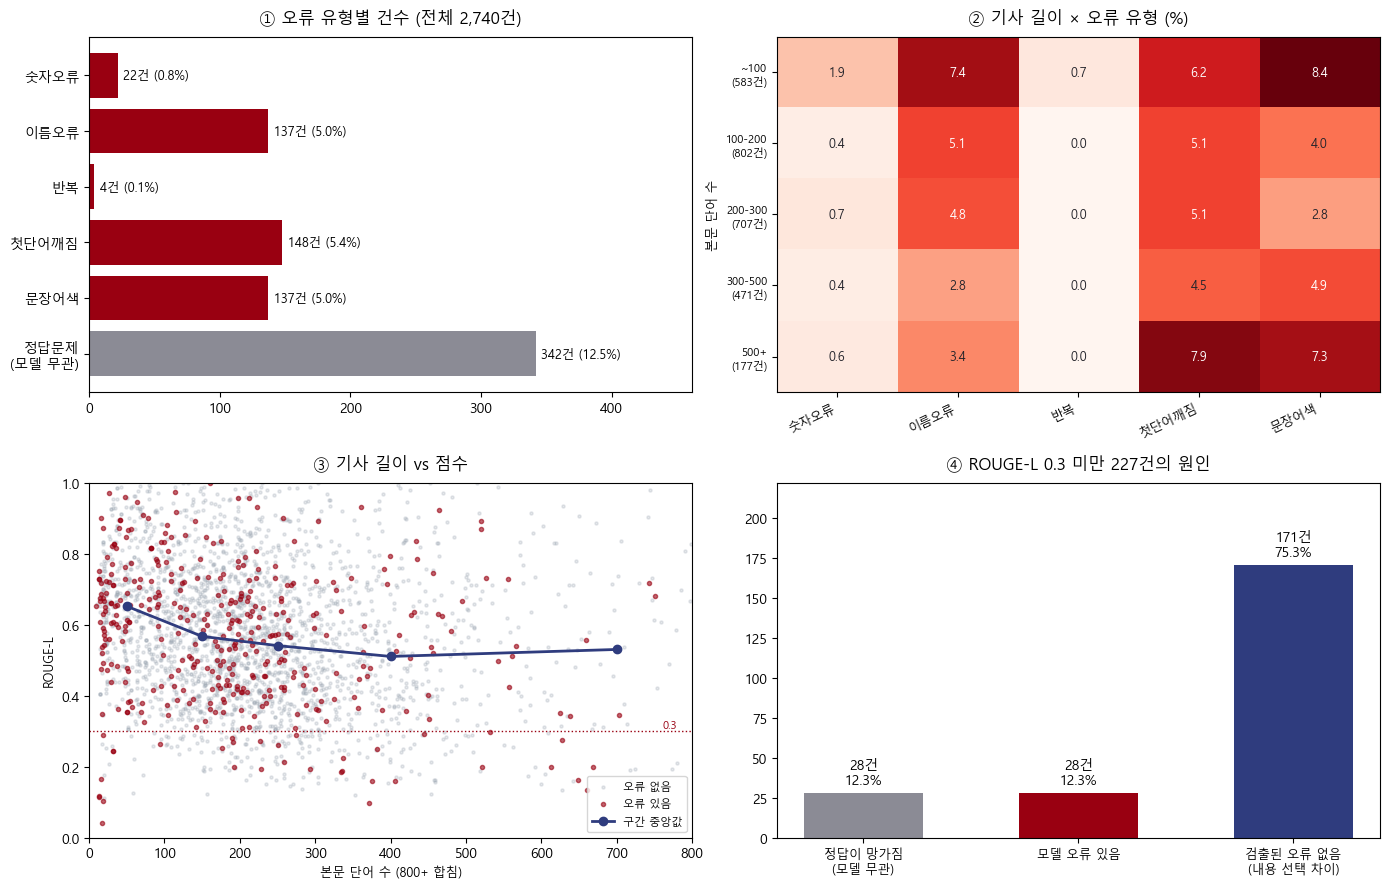

[보조표] 데이터 버전별 오류율 (%)
                  반복  이름오류  숫자오류  첫단어깨짐
v0              7.04  6.31  0.77   6.64
v1              6.17  4.56  0.84   4.74
v2 (beam4)      2.74  4.89  0.66   5.36
v2 (최종 norep6)  0.15  5.00  0.80   5.40


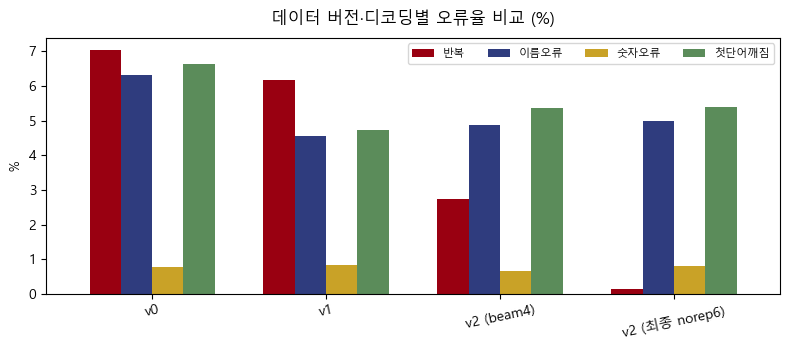

In [4]:
# ============================================================
# [05-5] 오류분석 ② 시각화 4종
#   출력: figures/05-5_error_analysis.png
# ============================================================
ETYPES5 = ["E_숫자오류", "E_이름오류", "E_반복", "E_첫단어깨짐", "E_문장어색"]
LABELS5 = [c[2:] for c in ETYPES5]

fig, ax = plt.subplots(2, 2, figsize=(14, 9))

# ---------- ① 유형별 건수 ----------
cnt = [d[c].sum() for c in ETYPES5] + [d["E_정답문제"].sum()]
lab = LABELS5 + ["정답문제\n(모델 무관)"]
col = ["#990011"] * 5 + ["#8b8b95"]
b = ax[0, 0].barh(lab, cnt, color=col)
ax[0, 0].bar_label(b, labels=[f"{c}건 ({c/len(d)*100:.1f}%)" for c in cnt], padding=4, fontsize=9)
ax[0, 0].set_xlim(0, max(cnt) * 1.35)
ax[0, 0].set_title("① 오류 유형별 건수 (전체 2,740건)", fontsize=12, pad=10)
ax[0, 0].invert_yaxis()

# ---------- ② 길이 × 유형 히트맵 ----------
hm = d.groupby("길이구간", observed=True)[ETYPES5].mean().mul(100)
hm.columns = LABELS5
im = ax[0, 1].imshow(hm.values, cmap="Reds", aspect="auto", vmin=0, vmax=hm.values.max())
ax[0, 1].set_xticks(range(len(LABELS5))); ax[0, 1].set_xticklabels(LABELS5, rotation=25, ha="right", fontsize=9)
ax[0, 1].set_yticks(range(len(hm))); ax[0, 1].set_yticklabels(
    [f"{i}\n({n}건)" for i, n in zip(hm.index, d.groupby("길이구간", observed=True).size())], fontsize=8)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        v = hm.values[i, j]
        ax[0, 1].text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=9,
                      color="white" if v > hm.values.max() * 0.55 else "#24242b")
ax[0, 1].set_title("② 기사 길이 × 오류 유형 (%)", fontsize=12, pad=10)
ax[0, 1].set_ylabel("본문 단어 수", fontsize=9)

# ---------- ③ 길이 vs 점수 ----------
ok = d["오류개수"] == 0
ax[1, 0].scatter(d.loc[ok, "doc_words"], d.loc[ok, "rougeL"], s=5, alpha=0.25, color="#9aa5b1", label="오류 없음")
ax[1, 0].scatter(d.loc[~ok, "doc_words"], d.loc[~ok, "rougeL"], s=9, alpha=0.6, color="#990011", label="오류 있음")
med = d.groupby("길이구간", observed=True)["rougeL"].median()
xs = [50, 150, 250, 400, 700]
ax[1, 0].plot(xs[:len(med)], med.values, "o-", color="#2f3c7e", lw=2, ms=6, label="구간 중앙값")
ax[1, 0].axhline(0.3, color="#990011", ls=":", lw=1)
ax[1, 0].text(760, 0.31, "0.3", fontsize=8, color="#990011")
ax[1, 0].set_xlim(0, 800); ax[1, 0].set_ylim(0, 1)
ax[1, 0].set_xlabel("본문 단어 수 (800+ 합침)", fontsize=9); ax[1, 0].set_ylabel("ROUGE-L", fontsize=9)
ax[1, 0].set_title("③ 기사 길이 vs 점수", fontsize=12, pad=10); ax[1, 0].legend(fontsize=8)

# ---------- ④ 점수 낮은 기사의 원인 ----------
low = d[d["E_점수낮음"]]
parts = [low["E_정답문제"].sum(),
         (~low["E_정답문제"] & (low["오류개수"] > 0)).sum(),
         (~low["E_정답문제"] & (low["오류개수"] == 0)).sum()]
names = ["정답이 망가짐\n(모델 무관)", "모델 오류 있음", "검출된 오류 없음\n(내용 선택 차이)"]
cols = ["#8b8b95", "#990011", "#2f3c7e"]
bars = ax[1, 1].bar(names, parts, color=cols, width=0.55)
ax[1, 1].bar_label(bars, labels=[f"{p}건\n{p/len(low)*100:.1f}%" for p in parts], padding=4, fontsize=10)
ax[1, 1].set_ylim(0, max(parts) * 1.3)
ax[1, 1].set_title(f"④ ROUGE-L 0.3 미만 {len(low)}건의 원인", fontsize=12, pad=10)
ax[1, 1].tick_params(axis="x", labelsize=9)

plt.tight_layout()
plt.savefig(FIG / "05-5_error_analysis.png", dpi=130, bbox_inches="tight")
plt.show()

# ---------- 보조: 데이터 버전별 오류 비교 ----------
comp = {}
for v, run in [("v0", "v0_kobart__beam4"), ("v1", "v1_kobart__beam4"),
               ("v2 (beam4)", "v2_kobart__beam4"), ("v2 (최종 norep6)", "v2_kobart__norep6")]:
    p = OUT / f"04-4_{run}_test_preds.csv"
    if not p.exists(): continue
    x = pd.read_csv(p)
    comp[v] = {
        "반복": round(x["repeat"].mean() * 100, 2),
        "이름오류": round((~x["nnp_ok"].astype(bool)).mean() * 100, 2) if "nnp_ok" in x else None,
        "숫자오류": round((~x["num_ok"].astype(bool)).mean() * 100, 2) if "num_ok" in x else None,
        "첫단어깨짐": round((~x["first_word_ok"].astype(bool)).mean() * 100, 2) if "first_word_ok" in x else None,
    }
cdf = pd.DataFrame(comp).T
print("=" * 70); print("[보조표] 데이터 버전별 오류율 (%)"); print("=" * 70)
print(cdf.to_string())

fig2, a = plt.subplots(figsize=(8, 3.6))
cdf.plot.bar(ax=a, rot=12, width=0.72, color=["#990011", "#2f3c7e", "#c9a227", "#5b8c5a"])
a.set_title("데이터 버전·디코딩별 오류율 비교 (%)", fontsize=12, pad=10)
a.legend(fontsize=8, ncol=4); a.set_ylabel("%", fontsize=9)
plt.tight_layout(); plt.savefig(FIG / "05-5_version_errors.png", dpi=130, bbox_inches="tight"); plt.show()

## 12-2. 사례 추출과 조원 확인

자동 검출에는 오탐이 있습니다. 원문을 그대로 베끼는 베이스라인의 고유명사 일치율이 100%가 아니라 **99.64%**였던 것이 그 증거입니다.

유형당 3~6건씩 총 20건을 뽑아 **"자동 검출이 맞았는지" O/X로 확인**했습니다. 점수를 매기는 것이 아니므로 주관이 거의 개입하지 않습니다.

In [4]:
# ============================================================
# [05-6] 오류분석 ③ 사례 추출 (조원 확인용)
#   유형별 대표 사례를 엑셀로 저장 + 노트북에서 바로 보기
#   출력: outputs/05-6_확인용_20건.xlsx
# ============================================================
from IPython.display import display, HTML

# ---------- 유형별 샘플링 ----------
SAMPLE = [
    ("① 이름 오류",      d["E_이름오류"] & ~d["E_정답문제"], 4),
    ("② 첫 단어 깨짐",   d["E_첫단어깨짐"] & ~d["E_정답문제"], 4),
    ("③ 숫자 오류",      d["E_숫자오류"] & ~d["E_정답문제"], 3),
    ("④ 문장 어색",      d["E_문장어색"] & ~d["E_정답문제"], 3),
    ("⑤ 점수 낮음·오류 없음", d["E_점수낮음"] & ~d["E_정답문제"] & (d["오류개수"] == 0), 6),
]

rows = []
for name, mask, n in SAMPLE:
    sub = d[mask]
    if len(sub) == 0:
        print(f"[없음] {name}"); continue
    for i in sub.sample(min(n, len(sub)), random_state=SEED).index:
        r = d.loc[i]
        types = [c[2:] for c in ["E_숫자오류","E_이름오류","E_반복","E_첫단어깨짐","E_문장어색"] if r[c]]
        rows.append({
            "번호": i, "검사 항목": name,
            "자동 검출": ", ".join(types) if types else "(없음)",
            "확인 O/X": "", "메모": "",
            "ROUGE-L": round(r["rougeL"], 3),
            "언론사": r["press"], "제목": r["title"],
            "원문": r["document"][:700],
            "정답 요약": str(r["ref"])[:400],
            "모델 요약": str(r["pred"])[:400],
        })

chk = pd.DataFrame(rows)
COLS = ["번호","검사 항목","자동 검출","확인 O/X","메모","ROUGE-L","언론사","제목","원문","정답 요약","모델 요약"]
chk = chk[COLS]

# ---------- 엑셀 저장 (열 너비·줄바꿈 설정) ----------
xlsx = OUT / "05-6_확인용_20건.xlsx"
with pd.ExcelWriter(xlsx, engine="openpyxl") as w:
    chk.to_excel(w, index=False, sheet_name="확인")
    ws = w.sheets["확인"]
    from openpyxl.styles import Alignment, Font, PatternFill
    widths = {"A":6,"B":16,"C":18,"D":10,"E":22,"F":9,"G":11,"H":30,"I":60,"J":45,"K":45}
    for col, wd in widths.items(): ws.column_dimensions[col].width = wd
    for cell in ws[1]:
        cell.font = Font(bold=True, color="FFFFFF")
        cell.fill = PatternFill("solid", fgColor="24242B")
        cell.alignment = Alignment(vertical="center", horizontal="center")
    for row in ws.iter_rows(min_row=2):
        for cell in row:
            cell.alignment = Alignment(wrap_text=True, vertical="top")
    for i in range(2, len(chk) + 2): ws.row_dimensions[i].height = 110
    ws.freeze_panes = "D2"
print(f"저장: {xlsx}  ({len(chk)}건)")

# ---------- 노트북에서 바로 보기 ----------
def mark(doc, txt):
    dw = set(doc.split())
    return " ".join(w if w in dw else f'<span style="background:#ffd6d6">{w}</span>' for w in str(txt).split())

for name, _, _ in SAMPLE:
    sub = chk[chk["검사 항목"] == name]
    if len(sub) == 0: continue
    display(HTML(f'<h3 style="margin:18px 0 6px;border-bottom:2px solid #990011;padding-bottom:4px">{name} ({len(sub)}건)</h3>'))
    for _, r in sub.iterrows():
        full = d.loc[r["번호"]]
        display(HTML(f"""
        <div style="border:1px solid #ddd;border-radius:6px;padding:10px;margin:8px 0;font-size:13px;line-height:1.7">
          <div style="color:#666;border-bottom:1px solid #eee;padding-bottom:5px;margin-bottom:7px">
            #{r['번호']} | {r['언론사']} | {r['제목']}<br>
            ROUGE-L {r['ROUGE-L']} · 자동 검출: <b style="color:#990011">{r['자동 검출']}</b>
          </div>
          <b>원문</b><br><span style="color:#444">{full['document'][:450]}…</span><br><br>
          <b>정답</b><br>{mark(full['document'], full['ref'])[:600]}<br><br>
          <b>모델</b><br>{mark(full['document'], full['pred'])}
        </div>"""))
display(HTML('<p style="font-size:11px;color:#888">빨강 = 원문에 없는 단어</p>'))

저장: C:\Users\wm032\Documents\news_summary_v2\outputs\05-6_확인용_20건.xlsx  (20건)


## 12-3. 사례 확인 결과

### ① 이름 오류 4건 → 2건만 실제 오류

| 번호 | 판정 | 내용 |
|---|---|---|
| #2230 | X | 원문 그대로 인용. 형태소 분석 오탐 |
| #1359 | X | "임상재 기자", "장영재 점장" — 원문에 있음 |
| #1851 | **O** | "린나 린나이가" — 린나이가 **린나**로 깨짐 |
| #1122 | **O** | "독일 괴류연구소" — 괴팅겐라이프니츠가 **괴류**로 깨짐 |

O 2건이 전부 첫 단어 깨짐과 같은 현상입니다.

### ② 첫 단어 깨짐 4건 → 4건 모두 실제 오류, 그리고 정답도 같이 깨짐

| 번호 | 모델 | 정답 |
|---|---|---|
| #397 | "5일수학연맹" | **"5일수학연맹"** ← 정답도 똑같이 깨짐 |
| #974 | "지난디" | "지난 강남구" |
| #980 | "4사회를 위한" | (정답은 정상) |
| #1933 | "지난아이" | "신들은 안 그래요" ← 정답도 깨짐 |

**#397이 결정적입니다.** 원문은 "국제수학연맹 IMU은"인데 정답과 모델이 **똑같이 "5일수학연맹"**으로 만들었습니다.
본문의 날짜 "5일"이 "국제"를 밀어낸 것으로, **모델이 정답의 오류를 그대로 학습한 직접 증거**입니다.

### ③ 숫자 오류 3건 → 3건 모두 오탐

| 번호 | 원인 |
|---|---|
| #797 | 원문 `26 813㎢` → 모델 `26 813km2` |
| #1004 | 원문 `727㎡` → 모델 `727m2` |
| #66 | 원문 `21만 1570m2` → 같은 패턴 |

**단위 기호(㎡/㎢)를 m2/km2로 바꾼 것**뿐이고 숫자는 정확합니다. 검출 규칙이 단위 기호를 숫자로 인식했습니다.

### ④ 문장 어색 3건 → 1건만 실제

퍼플렉시티 상위 5%는 **상대 기준**이라 정의상 항상 5%가 걸립니다. 오탐이 많습니다.

### ⑤ 점수 낮음·오류 없음 6건 → **6건 모두 타당한 요약**

| 번호 | 모델이 고른 것 | 정답이 고른 것 |
|---|---|---|
| #1427 | 국제선 회복 목표 가시화 | 월별 여객 수치 |
| #861 | 상반기 적자 103억, 역대 최대 | 에너지 가격 원인 |
| #866 | 인플레·에너지 쇼크 대응 | 반도체 종합대책 |
| #2167 | 펀드 수익률 급락, 관망 주문 | 코스닥 지수 수치 |
| #2535 | **1분기 흑자전환** (제목과 일치) | LED 유리 사업 (같은 문장 2회 반복) |
| #1083 | 손배소송·투쟁 격화 | 파업 지속 상황 |

**#2535가 압권입니다.** 제목이 "글람 1분기 흑자전환 성공"인데 모델은 흑자전환을 요약했고, 정답은 엉뚱하게 LED 유리 사업을 요약하면서 같은 문장을 두 번 반복합니다.
**모델 요약이 정답보다 낫습니다. 그런데 ROUGE-L은 0.167입니다.**

## 12-4. 검출 규칙 수정 후 재계산

사례 확인 결과를 반영해 규칙을 고쳤습니다.

- **숫자**: 단위 기호 13종 정규화 (㎡→m2, ㎢→km2, ℃→C 등), 쉼표·공백 제거
- **이름**: 형태소 경계 대신 문자열 포함 여부로 비교 (조사 차이 무시)

In [5]:
# ============================================================
# [05-7] 오류분석 ④ 검출 규칙 수정 후 재계산
#   사례 확인 결과 반영:
#   - 숫자 오류: 단위 기호(㎡→m2, ㎢→km2 등) 변환이 오류로 잡혔음 → 정규화
#   - 이름 오류: 형태소 분석 오탐 다수 → 원문에 부분 포함되면 정상으로 간주
#   출력: outputs/05-7_error_revised.csv
# ============================================================
import re

# ---------- 단위 기호 정규화 ----------
UNIT_MAP = {"㎡": "m2", "㎢": "km2", "㎥": "m3", "㎝": "cm", "㎜": "mm", "㎞": "km",
            "㎏": "kg", "㎎": "mg", "㏊": "ha", "℃": "C", "％": "%", "㎾": "kw", "㎿": "mw"}
def norm(t):
    t = str(t)
    for k, v in UNIT_MAP.items():
        t = t.replace(k, v)
    return t.replace(" ", "").replace(",", "")

NUM_RE = re.compile(r"\d+(?:\.\d+)?")
d["num_ok2"] = [set(NUM_RE.findall(norm(p))) <= set(NUM_RE.findall(norm(doc)))
                for p, doc in zip(d["pred"].fillna("").astype(str), d["document"])]

# ---------- 고유명사: 원문에 부분 포함되면 정상 ----------
def nnp_check(pred, doc):
    """요약의 고유명사가 원문에 '문자열로' 있는지 확인 (형태소 경계 무시)"""
    docn = norm(doc)
    bad = [t.form for t in _kiwi.tokenize(str(pred)) if t.tag == "NNP" and norm(t.form) not in docn]
    return len(bad) == 0, bad

res = [nnp_check(p, doc) for p, doc in zip(d["pred"].fillna(""), d["document"])]
d["nnp_ok2"] = [r[0] for r in res]
d["nnp_bad"] = [", ".join(r[1][:3]) for r in res]

# ---------- 비교 ----------
print("=" * 78); print("[규칙 수정 전후 비교]"); print("=" * 78)
cmp = pd.DataFrame({
    "수정 전": [(~d["num_ok"].astype(bool)).sum(), (~d["nnp_ok"].astype(bool)).sum()],
    "수정 후": [(~d["num_ok2"]).sum(), (~d["nnp_ok2"]).sum()],
}, index=["숫자 오류", "이름 오류"])
cmp["감소"] = cmp["수정 전"] - cmp["수정 후"]
cmp["수정 후 비율(%)"] = (cmp["수정 후"] / len(d) * 100).round(2)
print(cmp.to_string())

# ---------- 오류 유형 재정의 ----------
d["E_숫자오류"] = ~d["num_ok2"]
d["E_이름오류"] = ~d["nnp_ok2"]
ETYPES5 = ["E_숫자오류", "E_이름오류", "E_반복", "E_첫단어깨짐", "E_문장어색"]
d["오류개수"] = d[ETYPES5].sum(axis=1)

print("\n" + "=" * 78); print("[표 1 수정본] 오류 유형별 건수"); print("=" * 78)
ETYPES = ETYPES5 + ["E_정답문제", "E_점수낮음"]
t1 = pd.DataFrame({
    "건수": [d[c].sum() for c in ETYPES],
    "비율(%)": [round(d[c].mean() * 100, 2) for c in ETYPES],
    "평균 ROUGE-L": [round(d.loc[d[c], "rougeL"].mean(), 4) for c in ETYPES],
}, index=[c[2:] for c in ETYPES])
t1.loc["전체"] = [len(d), 100.0, round(d["rougeL"].mean(), 4)]
print(t1.to_string())

print("\n" + "=" * 78); print("[표 4 수정본] ROUGE-L 0.3 미만 기사의 원인"); print("=" * 78)
low = d[d["E_점수낮음"]]
t4 = pd.DataFrame({"건수": [
    len(low), low["E_정답문제"].sum(),
    (~low["E_정답문제"] & (low["오류개수"] > 0)).sum(),
    (~low["E_정답문제"] & (low["오류개수"] == 0)).sum()]},
    index=["점수 낮은 기사 전체", "└ 정답이 망가진 경우", "└ 모델 오류가 있는 경우", "└ 검출된 오류 없음"])
t4["비율(%)"] = (t4["건수"] / len(low) * 100).round(1)
print(t4.to_string())

# ---------- 남은 이름 오류의 실제 내용 ----------
print("\n" + "=" * 78); print("[참고] 수정 후에도 남은 이름 오류 상위 20건"); print("=" * 78)
bad = d.loc[d["E_이름오류"] & (d["nnp_bad"] != ""), "nnp_bad"]
from collections import Counter
cnt = Counter(w.strip() for s in bad for w in s.split(","))
print(pd.Series(dict(cnt.most_common(20))).to_string())

d.to_csv(OUT / "05-7_error_revised.csv", index=False, encoding="utf-8-sig")
print(f"\n저장: {OUT / '05-7_error_revised.csv'}")

[규칙 수정 전후 비교]
       수정 전  수정 후   감소  수정 후 비율(%)
숫자 오류    22    10   12        0.36
이름 오류   137    27  110        0.99

[표 1 수정본] 오류 유형별 건수
           건수   비율(%)  평균 ROUGE-L
숫자오류     10.0    0.36      0.7525
이름오류     27.0    0.99      0.4920
반복        4.0    0.15      0.6463
첫단어깨짐   148.0    5.40      0.5630
문장어색    137.0    5.00      0.5592
정답문제    342.0   12.48      0.5697
점수낮음    227.0    8.28      0.2274
전체     2740.0  100.00      0.5685

[표 4 수정본] ROUGE-L 0.3 미만 기사의 원인
                 건수  비율(%)
점수 낮은 기사 전체     227  100.0
└ 정답이 망가진 경우     28   12.3
└ 모델 오류가 있는 경우   23   10.1
└ 검출된 오류 없음     176   77.5

[참고] 수정 후에도 남은 이름 오류 상위 20건
쌍용차        4
야생생동물센터    1
카카빌리티      1
천지엠        1
포포브스       1
홍석주        1
엠일         1
프레지        1
브로         1
증권럴드경제     1
삼성증권       1
5일동제약      1
괴류연구소      1
배태근이       1
목원원대학교     1
프레테일       1
독프         1
한국수학회      1
대웅공장       1
오니섬        1

저장: C:\Users\wm032\Documents\news_summary_v2\outputs\05-7_error_revised.csv


### 수정 효과

| | 수정 전 | 수정 후 | 감소 |
|---|---|---|---|
| 숫자 오류 | 22건 (0.80%) | **10건 (0.36%)** | −55% |
| 이름 오류 | 137건 (5.00%) | **27건 (0.99%)** | **−80%** |

이름 오류 137건 중 **110건이 형태소 경계 오탐**이었습니다.

### 남은 27건의 정체

| 단어 | 원래 | 유형 |
|---|---|---|
| 5일동제약 | 일동제약 | **첫 단어 깨짐** |
| 괴류연구소 | 괴팅겐라이프니츠영장류연구소 | 축약 깨짐 |
| 증권럴드경제 | 헤럴드경제 | 깨짐 |
| 카카빌리티 | 카카오모빌리티 | 축약 깨짐 |
| 쌍용차 (4건) | 쌍용자동차 | **정당한 축약 (오탐)** |

**대부분이 첫 단어 깨짐과 같은 계열**입니다. 정당한 축약까지 빼면 실제 오류는 20건 안팎(0.7%)입니다.

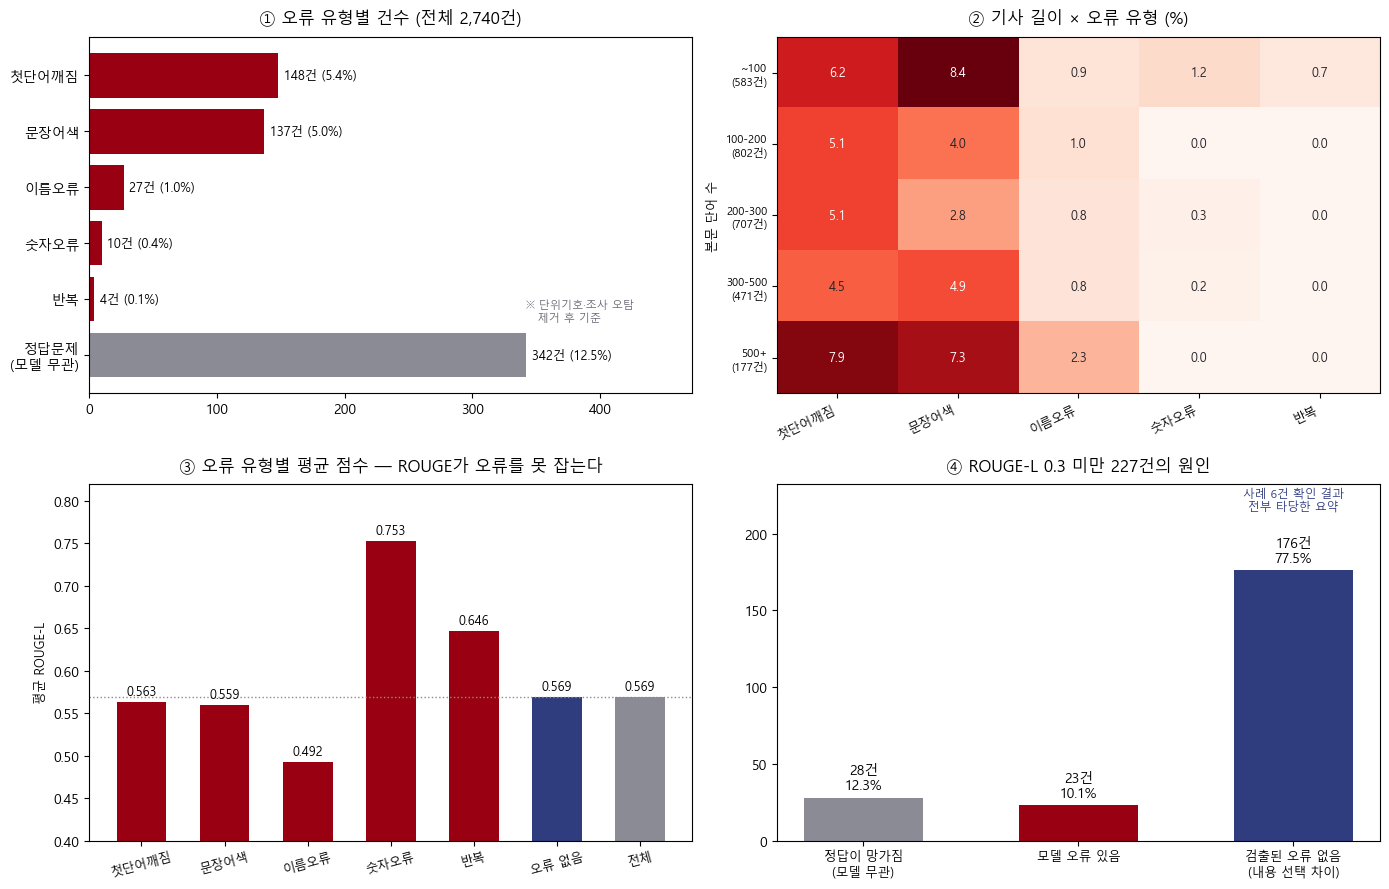

[버전별 오류율 (%) — 수정 규칙 적용]
                반복  이름오류  숫자오류  첫단어깨짐
v0            7.04  1.09  0.40   6.64
v1            6.17  0.69  0.47   4.74
v2 beam4      2.74  0.73  0.22   5.36
v2 최종 norep6  0.15  0.99  0.36   5.40


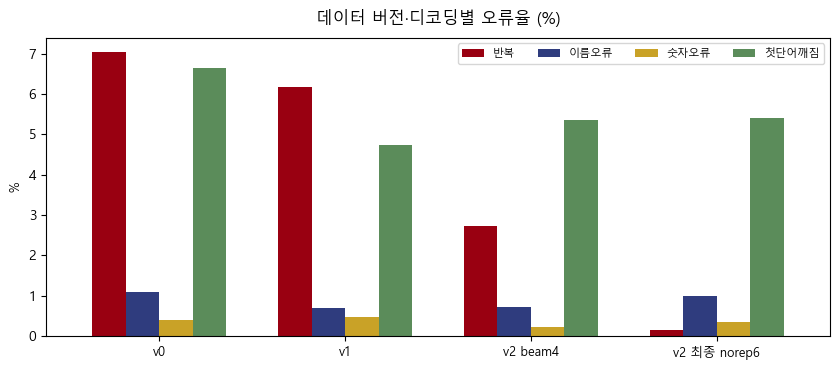

In [8]:
# ============================================================
# [05-8] 오류분석 시각화 (수정 규칙 반영, 최종본)
#   출력: figures/05-8_error_analysis.png, 05-8_version_errors.png
# ============================================================
ETYPES5 = ["E_숫자오류", "E_이름오류", "E_반복", "E_첫단어깨짐", "E_문장어색"]
LABELS5 = [c[2:] for c in ETYPES5]

fig, ax = plt.subplots(2, 2, figsize=(14, 9))

# ---------- ① 유형별 건수 ----------
order = ["E_첫단어깨짐", "E_문장어색", "E_이름오류", "E_숫자오류", "E_반복"]
cnt = [d[c].sum() for c in order] + [d["E_정답문제"].sum()]
lab = [c[2:] for c in order] + ["정답문제\n(모델 무관)"]
col = ["#990011"] * 5 + ["#8b8b95"]
b = ax[0, 0].barh(lab, cnt, color=col)
ax[0, 0].bar_label(b, labels=[f"{c}건 ({c/len(d)*100:.1f}%)" for c in cnt], padding=4, fontsize=9)
ax[0, 0].set_xlim(0, max(cnt) * 1.38)
ax[0, 0].set_title("① 오류 유형별 건수 (전체 2,740건)", fontsize=12, pad=10)
ax[0, 0].invert_yaxis()
ax[0, 0].text(max(cnt)*1.0, 4.4, "※ 단위기호·조사 오탐\n   제거 후 기준", fontsize=8, color="#6b6b75")

# ---------- ② 길이 × 유형 히트맵 ----------
hm = d.groupby("길이구간", observed=True)[order].mean().mul(100)
hm.columns = [c[2:] for c in order]
ax[0, 1].imshow(hm.values, cmap="Reds", aspect="auto", vmin=0, vmax=hm.values.max())
ax[0, 1].set_xticks(range(len(hm.columns))); ax[0, 1].set_xticklabels(hm.columns, rotation=25, ha="right", fontsize=9)
ax[0, 1].set_yticks(range(len(hm))); ax[0, 1].set_yticklabels(
    [f"{i}\n({n}건)" for i, n in zip(hm.index, d.groupby("길이구간", observed=True).size())], fontsize=8)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        v = hm.values[i, j]
        ax[0, 1].text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=9,
                      color="white" if v > hm.values.max() * 0.55 else "#24242b")
ax[0, 1].set_title("② 기사 길이 × 오류 유형 (%)", fontsize=12, pad=10)
ax[0, 1].set_ylabel("본문 단어 수", fontsize=9)

# ---------- ③ 오류 유형별 평균 점수 ----------
names = [c[2:] for c in order] + ["오류 없음", "전체"]
vals = [d.loc[d[c], "rougeL"].mean() for c in order] + \
       [d.loc[d["오류개수"] == 0, "rougeL"].mean(), d["rougeL"].mean()]
cols = ["#990011"] * 5 + ["#2f3c7e", "#8b8b95"]
bb = ax[1, 0].bar(names, vals, color=cols, width=0.6)
ax[1, 0].bar_label(bb, fmt="%.3f", padding=3, fontsize=9)
ax[1, 0].axhline(d["rougeL"].mean(), color="#8b8b95", ls=":", lw=1)
ax[1, 0].set_ylim(0.4, 0.82); ax[1, 0].set_ylabel("평균 ROUGE-L", fontsize=9)
ax[1, 0].set_title("③ 오류 유형별 평균 점수 — ROUGE가 오류를 못 잡는다", fontsize=12, pad=10)
ax[1, 0].tick_params(axis="x", labelsize=9, rotation=15)

# ---------- ④ 점수 낮은 기사의 원인 ----------
low = d[d["E_점수낮음"]]
parts = [low["E_정답문제"].sum(),
         (~low["E_정답문제"] & (low["오류개수"] > 0)).sum(),
         (~low["E_정답문제"] & (low["오류개수"] == 0)).sum()]
nm = ["정답이 망가짐\n(모델 무관)", "모델 오류 있음", "검출된 오류 없음\n(내용 선택 차이)"]
cl = ["#8b8b95", "#990011", "#2f3c7e"]
bars = ax[1, 1].bar(nm, parts, color=cl, width=0.55)
ax[1, 1].bar_label(bars, labels=[f"{p}건\n{p/len(low)*100:.1f}%" for p in parts], padding=4, fontsize=10)
ax[1, 1].set_ylim(0, max(parts) * 1.32)
ax[1, 1].set_title(f"④ ROUGE-L 0.3 미만 {len(low)}건의 원인", fontsize=12, pad=10)
ax[1, 1].tick_params(axis="x", labelsize=9)
ax[1, 1].text(2, max(parts)*1.22, "사례 6건 확인 결과\n전부 타당한 요약", fontsize=8.5,
              ha="center", color="#2f3c7e", style="italic")

plt.tight_layout()
plt.savefig(FIG / "05-8_error_analysis.png", dpi=130, bbox_inches="tight")
plt.show()

# ---------- 버전별 오류 비교 (같은 규칙 적용) ----------
def rate(x, docs):
    n = [set(NUM_RE.findall(norm(p))) <= set(NUM_RE.findall(norm(doc)))
         for p, doc in zip(x["pred"].fillna("").astype(str), docs)]
    nn = [nnp_check(p, doc)[0] for p, doc in zip(x["pred"].fillna(""), docs)]
    return {"반복": round(x["repeat"].mean()*100, 2),
            "이름오류": round((~pd.Series(nn)).mean()*100, 2),
            "숫자오류": round((~pd.Series(n)).mean()*100, 2),
            "첫단어깨짐": round((~x["first_word_ok"].astype(bool)).mean()*100, 2)}

docs = d["document"].tolist()
comp = {}
for v, run in [("v0", "v0_kobart__beam4"), ("v1", "v1_kobart__beam4"),
               ("v2 beam4", "v2_kobart__beam4"), ("v2 최종 norep6", "v2_kobart__norep6")]:
    p = OUT / f"04-4_{run}_test_preds.csv"
    if p.exists(): comp[v] = rate(pd.read_csv(p), docs)
cdf = pd.DataFrame(comp).T
print("=" * 70); print("[버전별 오류율 (%) — 수정 규칙 적용]"); print("=" * 70)
print(cdf.to_string())

fig2, a = plt.subplots(figsize=(8.5, 3.8))
cdf.plot.bar(ax=a, rot=0, width=0.72, color=["#990011", "#2f3c7e", "#c9a227", "#5b8c5a"])
a.set_title("데이터 버전·디코딩별 오류율 (%)", fontsize=12, pad=10)
a.legend(fontsize=8, ncol=4); a.set_ylabel("%", fontsize=9)
a.tick_params(axis="x", labelsize=9)
plt.tight_layout(); plt.savefig(FIG / "05-8_version_errors.png", dpi=130, bbox_inches="tight"); plt.show()

## 12-5. 오류분석 결론

### 최종 오류 현황

| 유형 | 건수 | 비율 | 평균 ROUGE-L |
|---|---|---|---|
| **첫 단어 깨짐** | **148** | **5.40%** | 0.5630 |
| 문장 어색 | 137 | 5.00% | 0.5592 |
| 이름 오류 | 27 | 0.99% | 0.4920 |
| 숫자 오류 | 10 | 0.36% | **0.7525** |
| 반복 | 4 | 0.15% | 0.6463 |
| (정답 문제) | 342 | 12.48% | 0.5697 |
| 전체 | 2,740 | 100% | 0.5685 |

### ① ROUGE는 오류를 잡아내지 못한다

**숫자를 틀린 요약의 평균 점수가 0.7525로 가장 높습니다.** 오류 없는 요약(0.569)보다 0.18 높습니다.
숫자 하나 틀려도 나머지 40단어가 맞으면 점수가 높게 나오기 때문입니다. 사실성 지표를 따로 둔 이유가 여기서 증명됩니다.

### ② 실제 모델 오류는 첫 단어 깨짐이 거의 전부다

148건(5.4%)이며, 이름 오류 27건도 대부분 같은 현상입니다.
그리고 이것은 **정답에서 배운 것**입니다 — #397처럼 정답과 모델이 똑같이 "5일수학연맹"을 만듭니다.

### ③ 전처리와 디코딩은 반복만 고쳤다

| | v0 | v1 | v2 beam4 | v2 최종 |
|---|---|---|---|---|
| **반복** | 7.04 | 6.17 | 2.74 | **0.15** |
| 이름 오류 | 1.09 | 0.69 | 0.73 | 0.99 |
| 숫자 오류 | 0.40 | 0.47 | 0.22 | 0.36 |
| 첫 단어 깨짐 | 6.64 | 4.74 | 5.36 | 5.40 |

반복만 계단처럼 내려가고 나머지는 평평합니다. **"무엇을 고쳤고 무엇을 못 고쳤는지"**가 명확합니다.

### ④ 점수가 낮은 기사의 77.5%는 모델 잘못이 아니다

```
ROUGE-L 0.3 미만 227건 (8.3%)
├ 정답이 망가짐        28건 (12.3%)
├ 모델 오류 있음       23건 (10.1%)
└ 검출된 오류 없음    176건 (77.5%)   ← 사례 6건 확인 결과 전부 타당한 요약
```

모델이 원문의 **다른 부분을 타당하게 요약**했을 뿐이며, 하나는 정답보다 나았습니다.

> **이것이 이 프로젝트의 핵심 주장인 "ROUGE는 좋은 요약이 아니라 정답 흉내를 측정한다"의 직접 증거입니다.**

---
# 13. 사례 확인 도구

원문·정답·모델 요약을 나란히 놓고 보는 도구입니다. 원문에 없는 단어를 빨갛게 표시합니다.

숫자만으로는 "왜"가 보이지 않습니다. 7장의 부작용 발견도 "추경호 경제부총리 겸 장관"처럼 직함이 잘린 것을 **눈으로 봐야** 원인을 알 수 있었습니다.

In [1]:
# ============================================================
# [07-1] 요약 사례 확인 도구
#   저장된 preds 파일을 읽어 원문·정답·모델 요약을 나란히 표시
#   유형별로 필터링해서 어떤 오류가 실제로 나는지 눈으로 확인
# ============================================================
import sys, re
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))
from common import *
from IPython.display import display, HTML
import difflib

RUN = "v2_kobart__norep6"            # ← 보고 싶은 실험
df = pd.read_csv(OUT / f"04-4_{RUN}_test_preds.csv")
test = pd.read_csv(PROC / "test.csv")
df["document"] = test["document"].values
df["title"] = test["title"].values
df["press"] = test["press"].values
print(f"{RUN}: {len(df):,}건 | 컬럼: {[c for c in df.columns if c not in ['document','pred','ref']]}")

# ---------- 표시 함수 ----------
def _mark(a, b):
    """b에만 있는 부분을 색칠 (a=원문, b=요약)"""
    aw = set(a.split())
    return " ".join(w if w in aw else f'<span style="background:#ffd6d6">{w}</span>' for w in b.split())

def show_case(i, max_doc=400):
    r = df.loc[i]
    flags = []
    for c, label in [("repeat", "반복"), ("nnp_ok", "고유명사"), ("num_ok", "숫자"), ("first_word_ok", "첫단어")]:
        if c in r and pd.notna(r[c]):
            ok = bool(r[c]) if c != "repeat" else not bool(r[c])
            flags.append(f'<span style="color:{"#1b7a3d" if ok else "#b3261e"}">{label} {"OK" if ok else "X"}</span>')
    meta = (f'#{i} | {r["press"]} | {r["title"]}<br>'
            f'ROUGE-L {r["rougeL"]:.3f} | 복사율 {r["copy_rate"]:.2f} | '
            f'{"정답노이즈 " if r["is_noisy"] else ""}{"train에있음 " if r["in_train"] else ""}'
            + " | ".join(flags))
    html = f"""
    <div style="border:1px solid #ccc;border-radius:6px;padding:10px;margin:8px 0;font-size:13px;line-height:1.7">
      <div style="color:#555;border-bottom:1px solid #eee;padding-bottom:6px;margin-bottom:8px">{meta}</div>
      <b>원문</b><br><span style="color:#444">{r["document"][:max_doc]}{"..." if len(r["document"]) > max_doc else ""}</span><br><br>
      <b>정답</b><br>{_mark(r["document"], str(r["ref"]))}<br><br>
      <b>모델</b><br>{_mark(r["document"], str(r["pred"]))}
    </div>
    <p style="font-size:11px;color:#888">빨강 = 원문에 없는 단어 (지어냈거나 표현을 바꾼 것)</p>"""
    display(HTML(html))

def show_group(name, mask, n=3, seed=42):
    sub = df[mask]
    print("\n" + "#" * 78); print(f"# {name}  ({len(sub):,}건, 전체의 {len(sub)/len(df)*100:.1f}%)"); print("#" * 78)
    if len(sub) == 0: print("해당 없음"); return
    for i in sub.sample(min(n, len(sub)), random_state=seed).index: show_case(i)

# ---------- 유형별 현황 ----------
print("\n" + "=" * 70); print("[유형별 건수]"); print("=" * 70)
groups = {
    "고유명사 불일치": ~df["nnp_ok"].astype(bool) if "nnp_ok" in df else None,
    "숫자 불일치":     ~df["num_ok"].astype(bool) if "num_ok" in df else None,
    "반복 발생":       df["repeat"].astype(bool),
    "첫 단어 원문에 없음": ~df["first_word_ok"].astype(bool) if "first_word_ok" in df else None,
    "ROUGE-L 0.3 미만": df["rougeL"] < 0.3,
    "정답 노이즈":     df["is_noisy"].astype(bool),
}
for k, m in groups.items():
    if m is not None: print(f"  {k:<22} {m.sum():>5}건 ({m.mean()*100:5.1f}%)")

# ---------- 사례 보기 ----------
show_group("① 고유명사 불일치 (사실 오류 의심)", ~df["nnp_ok"].astype(bool), n=3)
show_group("② ROUGE-L 낮음 + 정답 정상 (모델 문제)", (df["rougeL"] < 0.3) & ~df["is_noisy"].astype(bool), n=3)
show_group("③ ROUGE-L 낮음 + 정답 노이즈 (정답 문제)", (df["rougeL"] < 0.3) & df["is_noisy"].astype(bool), n=2)
show_group("④ 무작위 (전형적인 모습)", pd.Series(True, index=df.index), n=3)

v2_kobart__norep6: 2,740건 | 컬럼: ['rouge1', 'rouge2', 'rougeL', 'rougeL_space', 'pred_len', 'pred_words', 'repeat', 'empty', 'copy_rate', 'in_train', 'is_noisy', 'category', 'num_ok', 'nnp_ok', 'first_word_ok', 'ppl', 'bertscore', 'title', 'press']

[유형별 건수]
  고유명사 불일치                 137건 (  5.0%)
  숫자 불일치                    22건 (  0.8%)
  반복 발생                      4건 (  0.1%)
  첫 단어 원문에 없음              148건 (  5.4%)
  ROUGE-L 0.3 미만           227건 (  8.3%)
  정답 노이즈                   342건 ( 12.5%)

##############################################################################
# ① 고유명사 불일치 (사실 오류 의심)  (137건, 전체의 5.0%)
##############################################################################



##############################################################################
# ② ROUGE-L 낮음 + 정답 정상 (모델 문제)  (199건, 전체의 7.3%)
##############################################################################



##############################################################################
# ③ ROUGE-L 낮음 + 정답 노이즈 (정답 문제)  (28건, 전체의 1.0%)
##############################################################################



##############################################################################
# ④ 무작위 (전형적인 모습)  (2,740건, 전체의 100.0%)
##############################################################################


## 13-2. 같은 기사를 여러 모델로 비교

In [2]:
# ============================================================
# [07-2] 같은 기사 × 여러 모델 비교
#   저장된 preds 파일들을 모아 한 기사에 대한 각 모델 요약을 나란히 표시
# ============================================================
# 비교할 실험 (파일이 있는 것만 자동으로 걸러냄)
WANT = ["v0_kobart__beam4", "v1_kobart__beam4", "v2_kobart__beam4",
        "v2_kobart__beam4_norep3", "v2_kobart__norep6"]

runs = {}
for name in WANT:
    p = OUT / f"04-4_{name}_test_preds.csv"
    if p.exists(): runs[name] = pd.read_csv(p)
    else: print(f"[없음] {name}")
test = pd.read_csv(PROC / "test.csv")
base60 = [" ".join(d.split()[:60]) for d in test["document"]]
print("비교 대상:", list(runs))

def compare_case(i, max_doc=400, show_base=True):
    doc, ref = test.loc[i, "document"], test.loc[i, "summary"]
    head = (f'#{i} | {test.loc[i, "press"]} | {test.loc[i, "title"]}<br>'
            f'<span style="color:#666">본문 {len(doc)}자 · '
            f'{"정답노이즈 " if test.loc[i, "is_noisy"] else ""}'
            f'{"train에있음" if test.loc[i, "in_train"] else ""}</span>')
    rows = [f'<tr style="background:#f7f7f7"><td style="padding:6px;white-space:nowrap"><b>정답</b></td>'
            f'<td style="padding:6px">{_mark(doc, str(ref))}</td></tr>']
    if show_base:
        rows.append(f'<tr><td style="padding:6px;white-space:nowrap">베이스라인<br>'
                    f'<span style="font-size:11px;color:#888">앞 60단어</span></td>'
                    f'<td style="padding:6px;color:#666">{base60[i][:200]}...</td></tr>')
    for name, df in runs.items():
        r = df.loc[i]
        tags = []
        if r.get("repeat", False): tags.append("반복")
        if "nnp_ok" in r and not r["nnp_ok"]: tags.append("고유명사X")
        if "num_ok" in r and not r["num_ok"]: tags.append("숫자X")
        tag = f' <span style="color:#b3261e;font-size:11px">{" ".join(tags)}</span>' if tags else ""
        rows.append(f'<tr><td style="padding:6px;white-space:nowrap">{name.replace("_kobart__", " · ")}<br>'
                    f'<span style="font-size:11px;color:#888">R-L {r["rougeL"]:.3f}</span>{tag}</td>'
                    f'<td style="padding:6px">{_mark(doc, str(r["pred"]))}</td></tr>')
    display(HTML(f"""
    <div style="border:1px solid #ccc;border-radius:6px;padding:10px;margin:10px 0;font-size:13px;line-height:1.7">
      <div style="color:#555;border-bottom:1px solid #eee;padding-bottom:6px;margin-bottom:8px">{head}</div>
      <div style="color:#444;margin-bottom:10px"><b>원문</b><br>{doc[:max_doc]}{"..." if len(doc) > max_doc else ""}</div>
      <table style="width:100%;border-collapse:collapse;table-layout:fixed">
        <colgroup><col style="width:130px"><col></colgroup>{"".join(rows)}</table>
    </div>
    <p style="font-size:11px;color:#888">빨강 = 원문에 없는 단어</p>"""))

# ---------- 모델 간 차이가 큰 기사 찾기 ----------
score_mat = pd.DataFrame({n: d["rougeL"] for n, d in runs.items()})
spread = score_mat.max(axis=1) - score_mat.min(axis=1)
print("\n모델 간 ROUGE-L 차이:", f"평균 {spread.mean():.3f} | 최대 {spread.max():.3f}")

print("\n" + "#" * 78); print("# 모델 간 차이가 가장 큰 기사 3건"); print("#" * 78)
for i in spread.nlargest(3).index: compare_case(i)

print("\n" + "#" * 78); print("# 무작위 3건"); print("#" * 78)
for i in test.sample(3, random_state=42).index: compare_case(i)

비교 대상: ['v0_kobart__beam4', 'v1_kobart__beam4', 'v2_kobart__beam4', 'v2_kobart__beam4_norep3', 'v2_kobart__norep6']

모델 간 ROUGE-L 차이: 평균 0.187 | 최대 0.886

##############################################################################
# 모델 간 차이가 가장 큰 기사 3건
##############################################################################


정답,"3일 3일 서울의 서울의 한 재래시장에서 수박이 판매되고 있으며, 3일 서울의 한 서울의 한 재래시장에서 수박이 판매되고 있고, 3일 서울의 서울의 한 재래시장에서 수박이 판매되고 있다."
베이스라인앞 60단어,서울 연합뉴스 박동주 기자 폭염이 이어진 3일 서울의 한 재래시장에서 수박이 판매되고 있다....
v0 · beam4R-L 0.962 반복,"3일 3일 서울의 한 재래시장에서 수박이 판매되고 있으며, 3일 서울의 한 서울의 한 재래시장에서 수박이 판매되고 있고, 3일 서울의 한 재래시장에서 수박이 판매되고 있다."
v1 · beam4R-L 0.075 반복,3일 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의 서울의
v2 · beam4R-L 0.735 반복,3일 서울의 한 재래시장에서 폭염이 이어진 3일 서울의 한 재래시장에서 수박이 판매되고 있으며 폭염이 이어진 3일 서울의 한 재래시장에서 수박이 판매되고 있다.
v2 · beam4_norep3R-L 0.435,3일 서울의 한 재래시장에서 수박이 판매되고 있다.
v2 · norep6R-L 0.674,3일 서울의 한 재래시장에서 수박이 판매되고 있으며 폭염이 이어진 3일 서울의 한 재래시장 수박이 판매되고 있다.


정답,세계국의 최대 전자상거래 시장인 아마존에서 인기를 끌고 있는 ‘김치 가루’는 100그램짜리 한 통에 9달러로 지난 2020년 4월 출시됐으며 누적 판매량은 30만개로 일본 ‘시치미’ 베트남 ‘칠리파우더’ 등과 경쟁하며 출시 이후 아마존 10위권을 지키고 있다.
베이스라인앞 60단어,아마존 칠리파우더 부문 판매 1위 대기업 중심 식품시장에서 잡초처럼 살아남아 안태양 푸드컬쳐랩 대표 사장의 맛 세계 최대 전자상거래 시장인 아마존에서 인기를 끌고 있는 ‘김치 가루’가 있습니다. 100그램짜리 한 통에 9달러로 지난 2020년 4월 출시했습니다. 싸지 않은 가격인데도 7개월 후 ‘칠리파우더’ 부문 1등에도 올랐습니다. 누적 판매량은 30만개...
v0 · beam4R-L 0.972,세계 최대 전자상거래 시장인 아마존에서 인기를 끌고 있는 ‘김치 가루’가 100그램짜리 한 통에 9달러로 지난 2020년 4월 출시되었으며 누적 판매량은 30만개로 일본 ‘시치미’ 베트남 ‘칠리파우더’ 등과 경쟁하며 출시 이후 아마존 10위권을 지키고 있다.
v1 · beam4R-L 0.972,세계 최대 전자상거래 시장인 아마존에서 인기를 끌고 있는 ‘김치 가루’가 100그램짜리 한 통에 9달러로 지난 2020년 4월 출시되었으며 누적 판매량은 30만개로 일본 ‘시치미’ 베트남 ‘칠리파우더’ 등과 경쟁하며 출시 이후 아마존 10위권을 지키고 있다.
v2 · beam4R-L 0.120,안태양 37 푸드컬쳐랩 대표는 김치 시즈닝을 넘어 김치짜장면 김치스낵 김치우동 김치말이국수 김치바삭김 등 그야말로 김치 전문 회사로 초고속 성장하고 있으며 2017년 김치시즈닝 아이디어를 떠올린 안 대표는 3년간 식품업계 전문가를 찾아 사업을 구체화했다.
v2 · beam4_norep3R-L 0.120,안태양 37 푸드컬쳐랩 대표는 김치 시즈닝을 넘어 김치짜장면 김치스낵 김치우동 김치말이국수 김치바삭김 등 그야말로 김치 전문 회사로 초고속 성장하고 있으며 2017년 김치시즈닝 아이디어를 떠올린 안 대표는 3년간 식품업계 전문가를 찾아 사업을 구체화했다.
v2 · norep6R-L 0.120,안태양 37 푸드컬쳐랩 대표는 김치 시즈닝을 넘어 김치짜장면 김치스낵 김치우동 김치말이국수 김치바삭김 등 그야말로 김치 전문 회사로 초고속 성장하고 있으며 2017년 김치시즈닝 아이디어를 떠올린 안 대표는 3년간 식품업계 전문가를 찾아 사업을 구체화했다.


정답,4일 4일 경기도 부천시 대원냉동산업사에서 직원이 얼음을 옮기고 있다.
베이스라인앞 60단어,부천 연합뉴스 박동주 기자 무더위가 계속된 4일 경기도 부천시 대원냉동산업사에서 직원이 얼음을 옮기고 있다....
v0 · beam4R-L 1.000,4일 4일 경기도 부천시 대원냉동산업사에서 직원이 얼음을 옮기고 있다.
v1 · beam4R-L 0.162 반복,4일 경기도 부천시 대원냉동산업사에서 직원이 얼음을 옮기고 무더위가 계속된 4일 경기도 부천시 대원냉동산업사에서 직원이 얼음을 옮기고 얼음을 옮기고 얼음을 옮기고 얼음을 옮기고 얼음을 옮기고 얼음을 옮기고 얼음을 옮기고 얼음을 옮기고 얼음을 옮기고 얼음을 옮기고 얼음을 옮기고 얼음을 옮기고 얼음을 옮기고 얼음을 옮기고 얼음을 옮기고 얼음을 옮기고 얼음을 옮기고 얼음을 옮기고 얼음을 옮기고 얼음을 옮기고 얼음을 옮기고 얼음을 옮기고 얼음을 옮기고 얼음을 옮기고 얼음을 옮기고 얼음을 옮기고 얼음을 옮기고 얼음을 옮기고 얼음을 옮기고 얼음을 옮기고 얼음을 옮기고 얼음을 옮기고 얼음을 옮
v2 · beam4R-L 0.507 반복,4일 경기도 부천시 대원냉동산업사에서 직원이 얼음을 옮기고 무더위가 계속된 4일 경기도 부천시 대원냉동산업사에서 직원이 얼음을 옮기는 등 무더위가 계속된 4일 경기도 부천시 대원냉동산업사에서 직원이 얼음을 옮기고 있다.
v2 · beam4_norep3R-L 0.484 고유명사X 숫자X,"무더위가 계속된 4일 경기도 부천시 대원냉동산업사에서 직원이 얼음을 옮기는 등 무더운 날씨가 계속된 4, 4일 경기도부천시 대원 냉동산업사에 직원이 얼음이 옮기고 있다."
v2 · norep6R-L 0.405,무더위가 계속된 4일 경기도 부천시 대원냉동산업사에서 직원이 얼음을 옮기고 얼음을 옮기는 등 무더운 날씨가 계속된 4일 경기도 부천시의 대원냉동산업사에서 얼음을 옮기는 직원이 얼음을 옮기는 등 얼음을 옮기는 일을 했다.



##############################################################################
# 무작위 3건
##############################################################################


정답,올해 6월까지 전년보다 매출이 67%까지 신장하며 고공 성장 중인 시코르의 공식 온라인몰 시코르닷컴은 오픈 2주년을 맞아 최대 75% 할인 행사를 열고 에스티로더 오리진스 시세이도 크리니크 등 글로벌 럭셔리 브랜드의 정품 세트 증정과 함께 행사 참여 시 최대 75% 할인 혜택을 제공한다고 5일 밝혔다.
베이스라인앞 60단어,시코르닷컴 올해 매출 67% 신장…MZ세대 럭셔리 뷰티 플랫폼으로 에스티로더·맥·바비브라운 등 총 400여개 브랜드 참여 할인 행사 시코르닷컴 2주년 할인 행사. 시코르의 공식 온라인몰 시코르닷컴은 오픈 2주년을 맞아 최대 75% 할인 행사를 연다고 5일 밝혔다. 시코르닷컴은 오는 6일부터 시코르닷컴에 입점한 400여개 브랜드가 다양한 특가 상품을 선보인다...
v0 · beam4R-L 0.601,시코르닷컴은 오는 6일부터 시코르닷컴에 입점한 400여개 브랜드가 다양한 특가 상품을 선보이는 오픈 2주년을 맞아 최대 75% 할인 행사를 연다고 5일 밝혔으며 에스티로더 오리진스 시세이도 크리니크 등 글로벌 럭셔리 브랜드의 정품 세트 증정과 함께 행사 참여 시 최대 75% 할인 혜택을 제공한다고 설명했다.
v1 · beam4R-L 0.644,시코르의 공식 온라인몰 시코르닷컴은 오픈 2주년을 맞아 오는 6일부터 시코르닷컴에 입점한 400여개 브랜드가 다양한 특가 상품을 선보이는데 에스티로더 오리진스 시세이도 크리니크 등 글로벌 럭셔리 브랜드의 정품 세트 증정과 함께 행사 참여 시 최대 75% 할인 혜택을 제공한다고 5일 밝혔다.
v2 · beam4R-L 0.548,시코르의 공식 온라인몰 시코르닷컴은 오는 6일부터 시코르닷컴에 입점한 400여개 브랜드가 다양한 특가 상품을 선보이며 글로벌 럭셔리 브랜드의 정품 세트 증정과 함께 행사 참여 시 최대 75% 할인 혜택을 제공한다고 5일 밝혔다.
v2 · beam4_norep3R-L 0.746,시코르의 공식 온라인몰 시코르닷컴은 오픈 2주년을 맞아 오는 6일부터 에스티로더 오리진스 시세이도 크리니크 등 글로벌 럭셔리 브랜드의 정품 세트 증정과 함께 행사 참여 시 최대 75% 할인 혜택을 제공한다고 5일 밝혔다.
v2 · norep6R-L 0.548,시코르의 공식 온라인몰 시코르닷컴은 오는 6일부터 시코르닷컴에 입점한 400여개 브랜드가 다양한 특가 상품을 선보이며 글로벌 럭셔리 브랜드의 정품 세트 증정과 함께 행사 참여 시 최대 75% 할인 혜택을 제공한다고 5일 밝혔다.


정답,"5일 정부서울청사에서 열린 이임식에서 이임식에서 고승범 금융위원장이 이임식에서 꽃다발을 받고, 고승범 금융위원장이 5일 정부서울청사에서 열린 이임식에서 꽃다발을 받고, 5일 정부서울청사에서 열린 이임식에서 꽃다발을 받고, 고승범 금융위원장이 5일 정부서울청사에서 열린 이임식에서 이임식에서 꽃다발을 받고 꽃다발을 받고, 5일 정부서울청사에서 이임식에서 이임식에서 이임식에서 꽃다발을 받고 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승 해주 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승승두 김승두 김승승두 김승승두 김승승두 김승승두 김승두 김승승두 김승승두 김승승두 김승승두 김승승두 김승승두 김승승두 김승승두 김승승두 김승승두 김승승두 김승승두 김승승두 김승승두 김승승두 김승승두 김승승두 김승승두 김승승두 김승승두 김승승두 김승승두 김승승두 김승승두 김승승두 김승승승승두 김승두 김승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승승"
베이스라인앞 60단어,서울 연합뉴스 김승두 기자 고승범 금융위원장이 5일 정부서울청사에서 열린 이임식에서 꽃다발을 받고 있다....
v0 · beam4R-L 0.339 반복 고유명사X,5일 정부서울청사에서 열린 이임식에서 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두 김승두
v1 · beam4R-L 0.171 반복 고유명사X,5일 정부서울청사에서 열린 이임식에서 고승범 금융위원장이 꽃다발을 받고 고승범 금융위원장이 5일 정부서울청사에서 열린 이임식에서 꽃다발을 받고 꽃다발을 받고 꽃다발을 받고 꽃다발을 받고 꽃다발을 받고 꽃다발을 받고 꽃다발을 받고 꽃다발을 받고 꽃다발을 받고 꽃다발을 받고 꽃다발을 받고 꽃다발을 받고 꽃다발을 받고 꽃다발을 받고 꽃다발을 받고 꽃다발을 받고 꽃다발을 받고 꽃다발을 받고 꽃다발을 받고 꽃다발을 받고 꽃다발을 받고 꽃다발을 받고 꽃다발을 받고 꽃다발을 받고 꽃다발을 받고 꽃다발을 받고 꽃다발을 받고 꽃다발을 받고 꽃다발을 받고 꽃다발을 받고 꽃다발을 받고 꽃다발을
v2 · beam4R-L 0.175 반복 고유명사X,고승범 금융위원장이 5일 정부서울청사에서 열린 이임식에서 꽃다발을 받았는데 고승범 금융위원장이 5일 정부서울청사에서 열린 이임식에서 꽃다발을 받았고 고승범 금융위원장이 5일 정부서울청사에서 열린 이임식에서 꽃다발을 받았다.
v2 · beam4_norep3R-L 0.095 고유명사X,고승범 금융위원장이 5일 정부서울청사에서 열린 이임식에서 꽃다발을 받고 정부서울청사 이임식 꽃다발로 꽃다발 받았다.
v2 · norep6R-L 0.115 고유명사X,고승범 금융위원장이 5일 정부서울청사에서 열린 이임식에서 꽃다발을 받았는데 5일 정부서울청사에서 고승범 금융위원장이 고승범 금융위원장에게 꽃다발을 받았다.


정답,'기업성장 여력이 큰 상위 기업들이 성과보상 또는 인재 확보라는 명분하에 경쟁적으로 높은 임금 상승을 주도하고 있다' 고 추경호 경제부총리 겸 기획재정부장관이 대기업의 과도한 임금 인상 자제를 요구한 것을 두고 노동계 반발과 함께 야당을 중심으로 정치권에서는 정부가 임금 문제에 개입한 것 이라며 비판의 강도를 높이고 있다.
베이스라인앞 60단어,기사내용 요약 秋 경총 간담회서 큰 기업 임금 인상 주도 노동계 반발…야당 정부가 임금 문제 개입 전문가 의견 갈려… 이치 안 맞아 vs 필요 임금 인상 자제 발언 전 고물가 상황 언급 물가 올라 임금 상승…원인은 자산불균형 대기업 중소기업 간 임금격차 우려 발언도 서울 뉴시스 추상철 기자 추경호 경제부총리가 지난달 28일 서울 마포구 경총에서 열린 경제부...
v0 · beam4R-L 0.625,추경호 경제부총리 겸 기획재정부장관이 지난달 28일 한국경영자총협회 경총 회장단 간담회에서 소위 잘나가는 여력이 큰 상위 기업들이 성과보상 또는 인재 확보라는 명분하에 경쟁적으로 높은 임금 상승을 주도하고 있다며 과도한 임금 인상은 고물가 상황을 심화시킬 뿐 아니라 대기업과 중소기업 간 임금 격차를 더욱 확대해 중소기업 근로취약계층의 상대적 박탈감을 키우고 이로 인한 사회적 갈등을 증폭시킬 우려가 있다 고 발언한 것을 두고 노동계 반발과 함께 야당을 중심으로 정치권에서는 정부가 임금 문제에 개입한 것 이라며 비판의 강도를 높이고 있다.
v1 · beam4R-L 0.625,추경호 경제부총리 겸 기획재정부장관이 지난달 28일 한국경영자총협회 경총 회장단 간담회에서 소위 잘나가는 여력이 큰 상위 기업들이 성과보상 또는 인재 확보라는 명분하에 경쟁적으로 높은 임금 상승을 주도하고 있다며 과도한 임금 인상은 고물가 상황을 심화시킬 뿐 아니라 대기업과 중소기업 간 임금 격차를 더욱 확대해 중소기업 근로취약계층의 상대적 박탈감을 키우고 이로 인한 사회적 갈등을 증폭시킬 우려가 있다 고 발언한 것을 두고 노동계 반발과 함께 야당을 중심으로 정치권에서는 정부가 임금 문제에 개입한 것 이라며 비판의 강도를 높이고 있다.
v2 · beam4R-L 0.735,추경호 경제부총리 겸 기획재정부장관이 지난달 28일 한국경영자총협회 경총 간담회에서 소위 잘나가는 여력이 큰 상위 기업들이 성과보상 또는 인재 확보라는 명분하에 경쟁적으로 높은 임금 상승을 주도하고 있다 고 발언한 것에 대해 노동계 반발과 함께 야당을 중심으로 정치권에서는 정부가 임금 문제에 개입한 것 이라며 비판의 강도를 높이고 있다.
v2 · beam4_norep3R-L 0.735,추경호 경제부총리 겸 기획재정부장관이 지난달 28일 한국경영자총협회 경총 간담회에서 소위 잘나가는 여력이 큰 상위 기업들이 성과보상 또는 인재 확보라는 명분하에 경쟁적으로 높은 임금 상승을 주도하고 있다 고 발언한 것에 대해 노동계 반발과 함께 야당을 중심으로 정치권에서는 정부가 임금 문제에 개입한 것 이라며 비판의 강도를 높이고 있다.
v2 · norep6R-L 0.735,추경호 경제부총리 겸 기획재정부장관이 지난달 28일 한국경영자총협회 경총 간담회에서 소위 잘나가는 여력이 큰 상위 기업들이 성과보상 또는 인재 확보라는 명분하에 경쟁적으로 높은 임금 상승을 주도하고 있다 고 발언한 것에 대해 노동계 반발과 함께 야당을 중심으로 정치권에서는 정부가 임금 문제에 개입한 것 이라며 비판의 강도를 높이고 있다.


## 13-3. 실제 네이버 기사 요약 (2026년 기사)

학습에 쓰지 않은 **최신 기사**에 모델을 적용했습니다.

> **사용 모델: `v2_s80_kobart`** — 최종 모델과 같은 데이터 처리·학습 설정(lr 3e-5, epoch 3, 배치 16)이며 분할 비율만 80:20입니다(clean 0.5657).
> 최종 모델 파일(`models/v2_kobart`)은 9장 하이퍼파라미터 실험이 같은 폴더에 덮어써 유실되었습니다. **평가 결과 파일(`04-4_v2_kobart__norep6_test_preds.csv`)은 보존**되어 있어 보고서의 모든 수치는 유효합니다.

### 결과

| 기사 | 요약이 담은 핵심 | 오류 |
|---|---|---|
| 삼성 HVAC 광주공장 (사회 섹션) | 광주사업장 제3캠퍼스 · HVAC 라인 · 2만1800m² · 2028년 가동 | "**21일00억 원**" — 투자 금액 앞자리 소실 |
| 삼성 광주사업장 37년 만의 투자 (사회 섹션) | 37년 만의 대규모 투자 · 냉난방공조 글로벌 거점 · 착공식 | "**생성9년**" — 1989년이 깨짐 |

- 학습 분야(경제·IT) 밖의 섹션이지만 기업 투자 기사라 **요지는 정확히** 담았습니다.
- 숫자 오류는 12장의 **첫 단어 오류와 같은 계열**(본문의 날짜가 옆 단어에 섞임)입니다. 이번에는 문장 **중간**에서 발생해 첫 단어 검사로는 잡히지 않았습니다 → 실제 숫자·날짜 오류는 12장의 집계보다 많을 수 있습니다(한계).

In [6]:
# ============================================================
# [07-3] 실제 네이버 기사 요약 (단독 실행용)
#   모델: v2_s80_kobart (최종 모델과 동일 데이터·설정, 분할 비율 80:20)
#   필요 패키지: torch, transformers, requests, beautifulsoup4
#   없으면 먼저 실행:  %pip install beautifulsoup4 requests
# ============================================================
import re
from pathlib import Path
from urllib.parse import urlparse, parse_qs

import torch
import requests
from bs4 import BeautifulSoup
from transformers import AutoTokenizer, BartForConditionalGeneration

# ---------- 1. 경로 · 장치 ----------
ROOT = Path.home() / "Documents" / "news_summary_v2"
MDIR = ROOT / "models" / "v2_s80_kobart"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

if not MDIR.exists():
    raise FileNotFoundError(f"모델 폴더가 없습니다: {MDIR}")

# ---------- 2. 모델 · 토크나이저 ----------
try:
    tok = AutoTokenizer.from_pretrained(str(MDIR))
except Exception:
    tok = AutoTokenizer.from_pretrained("gogamza/kobart-base-v2")
model = BartForConditionalGeneration.from_pretrained(str(MDIR)).to(DEVICE).eval()
print(f"모델 불러옴: {MDIR.name} | 장치: {DEVICE}")

# ---------- 3. 섹션 코드 ----------
SID = {"100": "정치", "101": "경제", "102": "사회", "103": "생활/문화", "104": "세계", "105": "IT/과학"}
IN_SCOPE = ("경제", "IT", "과학")

# ---------- 4. 전처리 · 요약 ----------
def clean(text):
    text = re.sub(r"[\w.+-]+@[\w-]+\.[\w.]+", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

def summarize(text):
    enc = tok(clean(text), max_length=512, truncation=True,
              return_tensors="pt", return_token_type_ids=False).to(DEVICE)
    with torch.no_grad():
        out = model.generate(**enc, num_beams=4, no_repeat_ngram_size=6,
                             max_length=160, early_stopping=True)
    return tok.decode(out[0], skip_special_tokens=True).strip()

# ---------- 5. 네이버 기사 가져오기 ----------
def fetch_naver(url):
    html = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=10).text
    soup = BeautifulSoup(html, "html.parser")

    title = soup.select_one("h2.media_end_head_headline, #title_area")
    body = soup.select_one("#dic_area, #newsct_article")
    if body is None:
        raise ValueError("본문을 찾지 못했습니다. 본문을 복사해서 show('', 본문)으로 넣어 주세요.")
    for t in body.select("em.img_desc, span.end_photo_org, script, style"):
        t.decompose()

    sec = soup.select_one("em.media_end_categorize_item")
    if sec:
        section = sec.get_text(strip=True)
    else:
        sid = parse_qs(urlparse(url).query).get("sid", [""])[0]
        section = SID.get(sid, "확인 불가")

    return (title.get_text(strip=True) if title else ""), body.get_text(" ", strip=True), section

# ---------- 6. 출력 ----------
def show(title, body, section=""):
    s = summarize(body)
    n_tok = len(tok(clean(body))["input_ids"])
    first_ok = bool(s) and s.split()[0] in body
    print("=" * 80)
    if title:
        print("제목 :", title)
    if section:
        tag = "학습 범위 안" if any(k in section for k in IN_SCOPE) else "학습 범위 밖 · 품질 저하 가능"
        print(f"섹션 : {section} ({tag})")
    print(f"원문 : {len(body):,}자 · {n_tok}토큰" + ("  (512 초과 → 앞부분만 사용)" if n_tok > 512 else ""))
    print("-" * 80)
    print("요약 :", s)
    print("-" * 80)
    print(f"요약 {len(s)}자 · {len(s.split())}단어 · 첫 단어 원문 포함: {'예' if first_ok else '아니오 ← 확인 필요'}")
    return s

# ---------- 7. 실행 ----------
URLS = [
    "https://n.news.naver.com/mnews/article/421/0009183021?sid=102",
    "https://n.news.naver.com/mnews/article/421/0009180748",
]
results = []
for u in URLS:
    try:
        t, b, sec = fetch_naver(u)
        results.append({"url": u, "제목": t, "섹션": sec, "요약": show(t, b, sec)})
    except Exception as e:
        print("=" * 80)
        print(f"실패: {u}\n  → {type(e).__name__}: {e}")

You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


모델 불러옴: v2_s80_kobart | 장치: cuda
제목 : 삼성은 왜 플랙트그룹 냉난방공조 한국공장으로 광주를 택했나
섹션 : 사회 (학습 범위 밖 · 품질 저하 가능)
원문 : 1,587자 · 632토큰  (512 초과 → 앞부분만 사용)
--------------------------------------------------------------------------------
요약 : 삼성전자는 21일00억 원을 투자해 광주사업장 제3캠퍼스에 연면적 2만1800m2(6600평) 규모의 HVAC 생산라인을 구축하고 2028년 초부터 본격 가동될 예정이다.
--------------------------------------------------------------------------------
요약 95자 · 17단어 · 첫 단어 원문 포함: 예
제목 : 삼성전자 광주사업장 37년 만의 대규모 투자…HVAC 공장 첫삽
섹션 : 사회 (학습 범위 밖 · 품질 저하 가능)
원문 : 1,260자 · 537토큰  (512 초과 → 앞부분만 사용)
--------------------------------------------------------------------------------
요약 : 삼성전자는 생성9년 광주사업장 설립 이후 37년 만의 대규모 생산시설 투자로 기존 AI 가전 생산기지인 광주를 냉난방공조까지 아우르는 글로벌 생산거점으로 육성한다는 구상으로 21일 오전 10시 전남광주 북구 광주사업장 제3캠퍼스에서 플랙트그룹 신규 생산시설 착공식이 열린다.
--------------------------------------------------------------------------------
요약 153자 · 33단어 · 첫 단어 원문 포함: 예


---
# 부록 A. 중복 유형 분석 (탐색 과정)

1장의 발견에 이르기까지의 상세한 분석 과정입니다. 본 실험에 직접 쓰이지는 않았으나, 근거의 출처입니다.

| 셀 | 내용 |
|---|---|
| P1 | 원본 불러오기 + 비교 도구 |
| P2 | 완전 일치 중복 인벤토리 (유형 A~D) |
| P3 | 유형별 사례 확인 |
| P4 | 시간 구분 + 전체 유사도 계산 |
| P5-1 | 본문 유사도 구간별 사례 |
| P6 | 광고 문구·기자 표기 제거 |
| P6-2 | 정리 함수 재구성 |
| P7 | 보완 패턴 적용 + 유사도 재계산 |
| P8 | 기자 표기 패턴 수정 → 재정리 → 정리 후 기준 완전 일치 |
| P5-2 | 요약 유사도 계산 + 사례 |

### 여기서 나온 주요 발견

**광고 문구가 유사도를 왜곡했다**

뉴시스 기사 끝의 "사진 영상 제보받습니다… 적극 반영하겠습니다"(약 100자)가 짧은 기사의 절반을 차지했습니다.

| 구간 | 제거 전 | 제거 후 | 변화 |
|---|---|---|---|
| 뉴시스 쌍 유사도 0.6~0.7 | 27,583 | 757 | **−97%** |
| 0.7 이상 | 거의 변화 없음 (진짜 유사한 기사) | | |

언론사별 고정 문구 비율: 더팩트 100%, 노컷뉴스 84.9%, MBC 61.7%.

**중복 유형 분류**

| 유형 | 내용 | 쌍 수 |
|---|---|---|
| A-1a | 수집 중복 (같은 시각) | 1,392 |
| A-1b | 재게시 | 1,136 |
| A-2 | 본문 같고 제목 다름 | 5,274 |
| C | 요약 같고 본문 다름 (끝 문장만 차이) | 203 |
| D | 제목 같고 본문 다름 | 1,952 |

**B유형 150쌍** — 광고 문구·기자 표기를 제거하면 본문이 같아지는데 요약이 다른 쌍입니다.
1-4의 증거 ②에 해당하며, 정답이 기사 앞부분에 민감하다는 근거입니다.

**유사 중복은 미처리** — 본문 유사도 0.8 이상 train-test 쌍이 6,117건 남아 있습니다.
기준값에 자연스러운 절단점이 없어 자의성이 있고, 데이터 4,000건 감소가 성능에 영향을 주지 않았음을 확인했으므로 제거하지 않았습니다(한계로 기재).

In [1]:
# ============================================================
# Cell P1. 원본 불러오기 + 비교 도구
# ============================================================
import os, re, difflib
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
from IPython.display import display, HTML

SEED = 42
np.random.seed(SEED)

DATA_DIR = Path("data")
raw = {
    "train": pd.read_csv(DATA_DIR / "train.csv"),
    "val":   pd.read_csv(DATA_DIR / "validation.csv"),
    "test":  pd.read_csv(DATA_DIR / "test.csv"),
}

# 원본에 어느 스플릿에서 왔는지, 원래 몇 번째 행인지 표시
for name, df in raw.items():
    df["split"] = name
    df["orig_idx"] = df.index
    df["press"] = df["press"].str.strip()

all_df = pd.concat(raw.values(), ignore_index=True)
print("전체:", all_df.shape, "| 스플릿별:", {k: len(v) for k, v in raw.items()})

# ---------- 비교 도구 ----------
def _mark_diff(a, b):
    """두 문자열의 차이를 단어 단위로 표시 (a 기준)"""
    sm = difflib.SequenceMatcher(None, a.split(), b.split())
    out_a, out_b = [], []
    for tag, i1, i2, j1, j2 in sm.get_opcodes():
        wa = " ".join(a.split()[i1:i2])
        wb = " ".join(b.split()[j1:j2])
        if tag == "equal":
            out_a.append(wa); out_b.append(wb)
        else:
            out_a.append(f'<span style="background:#ffd6d6">{wa}</span>')
            out_b.append(f'<span style="background:#d6f0ff">{wb}</span>')
    return " ".join(out_a), " ".join(out_b)

def show_pair(row_a, row_b, label_a="A", label_b="B", max_chars=None):
    """
    두 기사를 나란히 표시. 다른 부분은 색으로 표시.
    row_a, row_b : all_df의 행 (Series)
    max_chars    : 본문 표시 글자 수 제한 (None이면 전체)
    """
    doc_a = row_a["document"] if max_chars is None else row_a["document"][:max_chars]
    doc_b = row_b["document"] if max_chars is None else row_b["document"][:max_chars]
    da, db = _mark_diff(doc_a, doc_b)
    sa, sb = _mark_diff(row_a["summary"], row_b["summary"])

    def meta(r):
        return (f'<b>{r["split"]}</b> #{r["orig_idx"]} | {r["press"]} | {r["date"]}<br>'
                f'<span style="color:#666">제목: {r["title"]}</span><br>'
                f'<span style="color:#666">본문 {len(r["document"])}자 · 요약 {len(r["summary"])}자</span>')

    html = f"""
    <table style="width:100%; table-layout:fixed; border-collapse:collapse; font-size:13px">
      <tr style="background:#f0f0f0">
        <th style="width:50%; padding:6px; text-align:left">{label_a}</th>
        <th style="width:50%; padding:6px; text-align:left">{label_b}</th>
      </tr>
      <tr><td style="padding:6px; vertical-align:top">{meta(row_a)}</td>
          <td style="padding:6px; vertical-align:top">{meta(row_b)}</td></tr>
      <tr style="background:#fafafa"><td colspan="2" style="padding:4px 6px"><b>본문</b></td></tr>
      <tr><td style="padding:6px; vertical-align:top; line-height:1.6">{da}</td>
          <td style="padding:6px; vertical-align:top; line-height:1.6">{db}</td></tr>
      <tr style="background:#fafafa"><td colspan="2" style="padding:4px 6px"><b>요약</b></td></tr>
      <tr><td style="padding:6px; vertical-align:top; line-height:1.6">{sa}</td>
          <td style="padding:6px; vertical-align:top; line-height:1.6">{sb}</td></tr>
    </table>
    <p style="font-size:11px; color:#888">빨강 = 왼쪽에만 있는 부분 / 파랑 = 오른쪽에만 있는 부분 / 색 없음 = 동일</p>
    """
    display(HTML(html))

# ---------- 도구 동작 확인: 본문이 같은 첫 번째 쌍 ----------
dup_mask = all_df.duplicated("document", keep=False)
first_doc = all_df.loc[dup_mask, "document"].iloc[0]
pair = all_df[all_df["document"] == first_doc].head(2)

print("\n[비교 도구 동작 확인] 본문이 같은 첫 번째 쌍")
show_pair(pair.iloc[0], pair.iloc[1])

전체: (27400, 9) | 스플릿별: {'train': 22194, 'val': 2466, 'test': 2740}

[비교 도구 동작 확인] 본문이 같은 첫 번째 쌍


In [2]:
# ============================================================
# Cell P2. 완전 일치 중복 인벤토리
#   유형: A-1(본문·요약·제목 동일) A-2(본문·요약 동일, 제목 다름)
#         B(본문 동일, 요약 다름) C(요약 동일, 본문 다름) D(제목 동일, 본문 다름)
#   위치: train-train / val-val / test-test / train-val / train-test / val-test
# ============================================================
from itertools import combinations

def make_pairs(df, key_cols, type_fn):
    """
    key_cols가 같은 행끼리 묶어 모든 쌍을 만들고, type_fn으로 유형을 붙인다.
    반환: 쌍 단위 DataFrame
    """
    rows = []
    grouped = df.groupby(key_cols, sort=False).indices
    for _, idx in grouped.items():
        if len(idx) < 2:
            continue
        for i, j in combinations(idx, 2):
            a, b = df.iloc[i], df.iloc[j]
            t = type_fn(a, b)
            if t is None:
                continue
            rows.append({
                "type": t,
                "idx_a": i, "idx_b": j,
                "split_a": a["split"], "split_b": b["split"],
                "group_size": len(idx),
            })
    return pd.DataFrame(rows)

# 유형 판정 함수
def type_doc_key(a, b):          # 본문이 같은 쌍
    if a["summary"] == b["summary"]:
        return "A-1 본문·요약·제목 동일" if a["title"] == b["title"] else "A-2 본문·요약 동일, 제목 다름"
    return "B 본문 동일, 요약 다름"

def type_sum_key(a, b):          # 요약이 같은 쌍
    return None if a["document"] == b["document"] else "C 요약 동일, 본문 다름"

def type_title_key(a, b):        # 제목이 같은 쌍
    return None if a["document"] == b["document"] else "D 제목 동일, 본문 다름"

pairs_doc   = make_pairs(all_df, ["document"], type_doc_key)
pairs_sum   = make_pairs(all_df, ["summary"],  type_sum_key)
pairs_title = make_pairs(all_df, ["title"],    type_title_key)
pairs_df = pd.concat([pairs_doc, pairs_sum, pairs_title], ignore_index=True)

# 위치 라벨 (순서 무관하게 정렬)
order = {"train": 0, "val": 1, "test": 2}
pairs_df["location"] = pairs_df.apply(
    lambda r: "-".join(sorted([r["split_a"], r["split_b"]], key=order.get)), axis=1)

TYPE_ORDER = ["A-1 본문·요약·제목 동일", "A-2 본문·요약 동일, 제목 다름",
              "B 본문 동일, 요약 다름", "C 요약 동일, 본문 다름", "D 제목 동일, 본문 다름"]
LOC_ORDER  = ["train-train", "val-val", "test-test", "train-val", "train-test", "val-test"]

# ---------- 표 1: 유형 × 위치 (쌍 수) ----------
print("=" * 78)
print("[표 1] 유형 × 위치: 중복 쌍 수")
print("=" * 78)
t1 = (pairs_df.pivot_table(index="type", columns="location", values="idx_a",
                           aggfunc="count", fill_value=0)
      .reindex(index=TYPE_ORDER, columns=LOC_ORDER, fill_value=0))
t1["합계"] = t1.sum(axis=1)
print(t1.to_string())

# ---------- 표 2: 유형별 관련 행 수 (쌍이 아니라 실제 행) ----------
print("\n" + "=" * 78)
print("[표 2] 유형별 관련 행 수 (스플릿별)")
print("=" * 78)
rows2 = []
for t in TYPE_ORDER:
    sub = pairs_df[pairs_df["type"] == t]
    involved = pd.unique(np.concatenate([sub["idx_a"].values, sub["idx_b"].values])) if len(sub) else []
    splits = all_df.loc[involved, "split"].value_counts() if len(involved) else pd.Series(dtype=int)
    rows2.append({"type": t, "관련 행": len(involved),
                  "train": splits.get("train", 0), "val": splits.get("val", 0), "test": splits.get("test", 0)})
print(pd.DataFrame(rows2).to_string(index=False))

# ---------- 표 3: 그룹 크기 분포 (본문 동일 기준) ----------
print("\n" + "=" * 78)
print("[표 3] 본문 동일 그룹 크기 분포 (같은 본문이 몇 번 나오는가)")
print("=" * 78)
doc_counts = all_df["document"].value_counts()
size_dist = doc_counts[doc_counts > 1].value_counts().sort_index()
print(pd.DataFrame({"그룹 크기": size_dist.index, "그룹 수": size_dist.values,
                    "관련 행": size_dist.index * size_dist.values}).to_string(index=False))

# ---------- 표 4: 유형 간 겹침 ----------
print("\n" + "=" * 78)
print("[표 4] 같은 쌍이 여러 유형에 동시에 해당하는 경우")
print("=" * 78)
pairs_df["pair_key"] = pairs_df.apply(lambda r: (min(r.idx_a, r.idx_b), max(r.idx_a, r.idx_b)), axis=1)
overlap = pairs_df.groupby("pair_key")["type"].apply(lambda s: " + ".join(sorted(s.str[:3].unique())))
print(overlap.value_counts().to_string())

# ---------- 저장 ----------
os.makedirs("outputs", exist_ok=True)
pairs_df.to_csv("outputs/P2_exact_pairs.csv", index=False, encoding="utf-8-sig")
print(f"\n쌍 목록 저장: outputs/P2_exact_pairs.csv ({len(pairs_df):,}쌍)")

[표 1] 유형 × 위치: 중복 쌍 수
location             train-train  val-val  test-test  train-val  train-test  val-test    합계
type                                                                                       
A-1 본문·요약·제목 동일             1655       16         21        390         393        53  2528
A-2 본문·요약 동일, 제목 다름         3422       75         33        866         775       103  5274
B 본문 동일, 요약 다름                 0        0          0          0           0         0     0
C 요약 동일, 본문 다름               126        2          3         31          36         5   203
D 제목 동일, 본문 다름              1270       21         16        331         266        48  1952

[표 2] 유형별 관련 행 수 (스플릿별)
               type  관련 행  train  val  test
    A-1 본문·요약·제목 동일  2816   2304  258   254
A-2 본문·요약 동일, 제목 다름  1930   1579  179   172
     B 본문 동일, 요약 다름     0      0    0     0
     C 요약 동일, 본문 다름   100     81    9    10
     D 제목 동일, 본문 다름  1960   1572  194   194

[표 3] 본문 동일 그룹 크기 분포 (같은 본문이 몇 번 나오는가)
 그룹 크

In [3]:
# ============================================================
# Cell P3. 유형별 사례 확인
#   - 각 유형: 그룹이 가장 큰 쌍 1건 + 무작위 2건
#   - A-2: 최대 그룹의 제목 전체 나열
#   - C: 제목 다름 / 제목 같음 나눠서 확인
# ============================================================
rng = np.random.RandomState(SEED)

def pick_pairs(sub, n_random=2):
    """그룹 크기가 가장 큰 쌍 1건 + 무작위 n_random건"""
    if len(sub) == 0:
        return []
    biggest = sub.sort_values("group_size", ascending=False).iloc[0]
    rest = sub.drop(biggest.name)
    randoms = rest.sample(min(n_random, len(rest)), random_state=rng) if len(rest) else rest
    return [("최대 그룹", biggest)] + [("무작위", r) for _, r in randoms.iterrows()]

def show_type(type_name, sub, max_chars=None):
    print("\n" + "#" * 78)
    print(f"# {type_name}  (총 {len(sub):,}쌍)")
    print("#" * 78)
    for label, p in pick_pairs(sub):
        a, b = all_df.loc[p["idx_a"]], all_df.loc[p["idx_b"]]
        print(f"\n▶ [{label}] 그룹 크기 {p['group_size']} | 위치 {p['location']}")
        show_pair(a, b, label_a=f"A ({a['split']} #{a['orig_idx']})",
                        label_b=f"B ({b['split']} #{b['orig_idx']})", max_chars=max_chars)

# ---------- A-1 ----------
show_type("A-1 본문·요약·제목 동일", pairs_df[pairs_df["type"].str.startswith("A-1")], max_chars=300)

# ---------- A-2 ----------
sub_a2 = pairs_df[pairs_df["type"].str.startswith("A-2")]
show_type("A-2 본문·요약 동일, 제목 다름", sub_a2, max_chars=300)

# A-2 최대 그룹의 제목 전체 나열
print("\n" + "=" * 78)
print("[A-2 최대 그룹: 같은 본문에 붙은 제목 전체]")
print("=" * 78)
big_doc = all_df["document"].value_counts().index[0]
big_group = all_df[all_df["document"] == big_doc].sort_values("date")
print(f"본문 ({len(big_doc)}자): {big_doc[:150]}{'...' if len(big_doc) > 150 else ''}")
print(f"요약: {big_group.iloc[0]['summary'][:150]}...")
print(f"\n{len(big_group)}건 | 언론사: {big_group['press'].unique().tolist()}")
print(f"스플릿 분포: {big_group['split'].value_counts().to_dict()}")
print(f"시간 범위: {big_group['date'].min()} ~ {big_group['date'].max()}\n")
display(big_group[["split", "orig_idx", "date", "press", "title"]].reset_index(drop=True))

# ---------- C: 제목 다름 / 제목 같음 나눠서 ----------
sub_c = pairs_df[pairs_df["type"].str.startswith("C")].copy()
sub_c["title_same"] = sub_c.apply(
    lambda r: all_df.loc[r["idx_a"], "title"] == all_df.loc[r["idx_b"], "title"], axis=1)

show_type("C 요약 동일, 본문 다름 — 제목도 다름", sub_c[~sub_c["title_same"]])
show_type("C 요약 동일, 본문 다름 — 제목은 같음", sub_c[sub_c["title_same"]])

# C 유형: 본문이 얼마나 다른지 숫자로
print("\n" + "=" * 78)
print("[C 유형 전체: 두 본문의 글자 수 차이와 단어 겹침 비율]")
print("=" * 78)
def word_overlap(a, b):
    wa, wb = set(a.split()), set(b.split())
    return len(wa & wb) / len(wa | wb)          # 자카드 유사도
sub_c["len_diff"] = sub_c.apply(
    lambda r: abs(len(all_df.loc[r["idx_a"], "document"]) - len(all_df.loc[r["idx_b"], "document"])), axis=1)
sub_c["overlap"] = sub_c.apply(
    lambda r: word_overlap(all_df.loc[r["idx_a"], "document"], all_df.loc[r["idx_b"], "document"]), axis=1)
print(sub_c[["len_diff", "overlap"]].describe(percentiles=[0.25, 0.5, 0.75, 0.9]).round(3))
print(f"\n단어 겹침 90% 이상: {(sub_c['overlap'] >= 0.9).sum()}쌍 / "
      f"70% 미만: {(sub_c['overlap'] < 0.7).sum()}쌍")

# ---------- D ----------
sub_d = pairs_df[pairs_df["type"].str.startswith("D")]
show_type("D 제목 동일, 본문 다름 (train-test 우선)",
          sub_d[sub_d["location"] == "train-test"] if (sub_d["location"] == "train-test").any() else sub_d,
          max_chars=400)

# D 유형: 본문이 얼마나 다른지 숫자로
print("\n" + "=" * 78)
print("[D 유형 전체: 두 본문의 단어 겹침 비율]")
print("=" * 78)
sub_d = sub_d.copy()
sub_d["overlap"] = sub_d.apply(
    lambda r: word_overlap(all_df.loc[r["idx_a"], "document"], all_df.loc[r["idx_b"], "document"]), axis=1)
print(sub_d["overlap"].describe(percentiles=[0.25, 0.5, 0.75, 0.9]).round(3))
print(f"\n단어 겹침 90% 이상: {(sub_d['overlap'] >= 0.9).sum()}쌍 / "
      f"50% 미만: {(sub_d['overlap'] < 0.5).sum()}쌍")


##############################################################################
# A-1 본문·요약·제목 동일  (총 2,528쌍)
##############################################################################

▶ [최대 그룹] 그룹 크기 23 | 위치 train-train



▶ [무작위] 그룹 크기 2 | 위치 train-train



▶ [무작위] 그룹 크기 14 | 위치 train-test



##############################################################################
# A-2 본문·요약 동일, 제목 다름  (총 5,274쌍)
##############################################################################

▶ [최대 그룹] 그룹 크기 23 | 위치 train-val



▶ [무작위] 그룹 크기 5 | 위치 train-test


...


▶ [무작위] 그룹 크기 4 | 위치 train-train



[C 유형 전체: 두 본문의 글자 수 차이와 단어 겹침 비율]
       len_diff  overlap
count   203.000  203.000
mean      6.739    0.921
std      33.163    0.068
min       0.000    0.706
25%       1.000    0.917
50%       4.000    0.943
75%       5.000    0.958
90%       6.000    0.981
max     446.000    0.993

단어 겹침 90% 이상: 158쌍 / 70% 미만: 0쌍

##############################################################################
# D 제목 동일, 본문 다름 (train-test 우선)  (총 266쌍)
##############################################################################

▶ [최대 그룹] 그룹 크기 19 | 위치 train-test



▶ [무작위] 그룹 크기 7 | 위치 train-test



▶ [무작위] 그룹 크기 3 | 위치 train-test



[D 유형 전체: 두 본문의 단어 겹침 비율]
count    1952.000
mean        0.549
std         0.281
min         0.011
25%         0.308
50%         0.554
75%         0.810
90%         0.922
max         1.000
Name: overlap, dtype: float64

단어 겹침 90% 이상: 258쌍 / 50% 미만: 871쌍


In [4]:
# ============================================================
# Cell P4. A-1 시간 구분 + 전체 유사도 계산
#   1) A-1을 시간 동일(수집 중복) / 시간 다름(재게시)으로 구분
#   2) 모든 기사 쌍의 본문 유사도, 요약 유사도 계산 (0.6 이상 저장)
#   3) 0.05 간격 구간별 개수 (완전 일치 제외)
# ============================================================
import time
from sklearn.feature_extraction.text import TfidfVectorizer

# ---------- 1) A-1 시간 구분 ----------
a1 = pairs_df[pairs_df["type"].str.startswith("A-1")].copy()
a1["time_same"] = a1.apply(
    lambda r: all_df.loc[r["idx_a"], "date"] == all_df.loc[r["idx_b"], "date"], axis=1)
a1["subtype"] = np.where(a1["time_same"], "A-1a 시간 동일(수집 중복)", "A-1b 시간 다름(재게시)")

print("=" * 78)
print("[A-1 세부 구분 × 위치: 쌍 수]")
print("=" * 78)
t_a1 = (a1.pivot_table(index="subtype", columns="location", values="idx_a",
                       aggfunc="count", fill_value=0)
        .reindex(columns=LOC_ORDER, fill_value=0))
t_a1["합계"] = t_a1.sum(axis=1)
print(t_a1.to_string())

# A-1b 시간 차이 분포
a1b = a1[~a1["time_same"]].copy()
a1b["gap_sec"] = a1b.apply(
    lambda r: abs((pd.to_datetime(all_df.loc[r["idx_a"], "date"]) -
                   pd.to_datetime(all_df.loc[r["idx_b"], "date"])).total_seconds()), axis=1)
print("\n[A-1b 시간 차이 분포 (초)]")
print(a1b["gap_sec"].describe(percentiles=[0.25, 0.5, 0.75, 0.9]).round(0))
for lo, hi, label in [(0, 60, "1분 이내"), (60, 3600, "1분~1시간"), (3600, 86400, "1시간~1일"), (86400, 1e9, "1일 초과")]:
    m = (a1b["gap_sec"] >= lo) & (a1b["gap_sec"] < hi)
    print(f"  {label:<10}: {m.sum():>5}쌍")

pairs_df.loc[a1.index, "type"] = a1["subtype"]      # pairs_df에 반영

# ---------- 2) 유사도 계산 ----------
print("\n" + "=" * 78)
print("[유사도 계산]")
print("=" * 78)
start = time.time()

vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 3), max_features=50000, dtype=np.float32)
vec.fit(pd.concat([all_df["document"], all_df["summary"]]))
X = vec.transform(all_df["document"])     # 본문 벡터
S = vec.transform(all_df["summary"])      # 요약 벡터
print(f"벡터화 완료: {time.time() - start:.0f}초")

def collect_pairs(M, threshold, chunk=1000):
    """M의 모든 행 쌍 중 유사도 threshold 이상인 (i, j, sim)을 수집 (i < j)"""
    n = M.shape[0]
    ii, jj, ss = [], [], []
    for i in range(0, n, chunk):
        sim = (M[i:i+chunk] @ M.T).toarray()
        rows = np.arange(i, min(i + chunk, n))
        sim[np.arange(n)[None, :] <= rows[:, None]] = 0     # j <= i 제거
        r, c = np.where(sim >= threshold)
        ii.append(rows[r]); jj.append(c); ss.append(sim[r, c])
        print(f"  {min(i + chunk, n):>6} / {n}", end="\r")
    return np.concatenate(ii), np.concatenate(jj), np.concatenate(ss)

SIM_MIN = 0.6
di, dj, ds = collect_pairs(X, SIM_MIN)
print(f"\n본문 유사도 {SIM_MIN} 이상 쌍: {len(di):,}개 ({time.time() - start:.0f}초)")
si, sj, ss_ = collect_pairs(S, SIM_MIN)
print(f"요약 유사도 {SIM_MIN} 이상 쌍: {len(si):,}개 ({time.time() - start:.0f}초)")

# 두 결과 합치기 (본문 기준 또는 요약 기준으로 0.6 이상이면 포함)
sim_df = pd.DataFrame({"idx_a": np.concatenate([di, si]),
                       "idx_b": np.concatenate([dj, sj])}).drop_duplicates()
sim_df["doc_sim"] = np.asarray(X[sim_df["idx_a"].values].multiply(X[sim_df["idx_b"].values]).sum(axis=1)).ravel()
sim_df["sum_sim"] = np.asarray(S[sim_df["idx_a"].values].multiply(S[sim_df["idx_b"].values]).sum(axis=1)).ravel()

# 완전 일치 여부, 위치
sim_df["doc_exact"] = all_df.loc[sim_df["idx_a"], "document"].values == all_df.loc[sim_df["idx_b"], "document"].values
sim_df["sum_exact"] = all_df.loc[sim_df["idx_a"], "summary"].values == all_df.loc[sim_df["idx_b"], "summary"].values
sim_df["location"] = ["-".join(sorted([a, b], key=order.get)) for a, b in
                      zip(all_df.loc[sim_df["idx_a"], "split"], all_df.loc[sim_df["idx_b"], "split"])]
print(f"합친 쌍: {len(sim_df):,}개 | 본문 완전 일치 {sim_df['doc_exact'].sum():,} | 요약 완전 일치 {sim_df['sum_exact'].sum():,}")

# ---------- 3) 구간별 개수 (완전 일치 제외) ----------
BINS = np.round(np.arange(0.60, 1.0001, 0.05), 2)
LABELS = [f"{BINS[k]:.2f}~{BINS[k+1]:.2f}" for k in range(len(BINS) - 1)]

def band_table(df, col, title):
    sub = df[df[col] >= SIM_MIN].copy()
    sub["band"] = pd.cut(sub[col], bins=BINS, labels=LABELS, include_lowest=True, right=False)
    t = (sub.pivot_table(index="band", columns="location", values="idx_a",
                         aggfunc="count", fill_value=0, observed=False)
         .reindex(columns=LOC_ORDER, fill_value=0))
    t["합계"] = t.sum(axis=1)
    print("\n" + "=" * 78); print(title); print("=" * 78)
    print(t.to_string())
    return t

t_doc = band_table(sim_df[~sim_df["doc_exact"]], "doc_sim", "[본문 유사도 구간 × 위치] (본문 완전 일치 제외)")
t_sum = band_table(sim_df[~sim_df["sum_exact"]], "sum_sim", "[요약 유사도 구간 × 위치] (요약 완전 일치 제외)")

# 본문 × 요약 교차표 (둘 다 완전 일치 아닌 쌍)
print("\n" + "=" * 78)
print("[본문 유사도 구간 × 요약 유사도 구간] (본문·요약 완전 일치 제외, 0.1 간격)")
print("=" * 78)
COARSE = [0.0, 0.6, 0.7, 0.8, 0.9, 1.0001]
CL = ["<0.6", "0.6~0.7", "0.7~0.8", "0.8~0.9", "0.9~1.0"]
both = sim_df[~sim_df["doc_exact"] & ~sim_df["sum_exact"]].copy()
both["doc_band"] = pd.cut(both["doc_sim"], COARSE, labels=CL, right=False)
both["sum_band"] = pd.cut(both["sum_sim"], COARSE, labels=CL, right=False)
print(pd.crosstab(both["doc_band"], both["sum_band"], rownames=["본문↓ / 요약→"]).to_string())

# ---------- 저장 ----------
sim_df.to_pickle("outputs/P4_sim_pairs.pkl")
a1[["idx_a", "idx_b", "location", "subtype"]].to_csv("outputs/P4_a1_time_split.csv", index=False, encoding="utf-8-sig")
print(f"\n저장 완료: outputs/P4_sim_pairs.pkl ({len(sim_df):,}쌍)")

[A-1 세부 구분 × 위치: 쌍 수]
location           train-train  val-val  test-test  train-val  train-test  val-test    합계
subtype                                                                                  
A-1a 시간 동일(수집 중복)          919       11         11        222         203        26  1392
A-1b 시간 다름(재게시)            736        5         10        168         190        27  1136

[A-1b 시간 차이 분포 (초)]
count      1136.0
mean       3022.0
std       18000.0
min           1.0
25%           2.0
50%          15.0
75%          71.0
90%        4663.0
max      434519.0
Name: gap_sec, dtype: float64
  1분 이내     :   746쌍
  1분~1시간    :   270쌍
  1시간~1일    :   117쌍
  1일 초과     :     3쌍

[유사도 계산]
벡터화 완료: 20초
   27400 / 27400
본문 유사도 0.6 이상 쌍: 137,763개 (69초)
요약 유사도 0.6 이상 쌍: 43,608개 (89초)
합친 쌍: 144,370개 | 본문 완전 일치 7,802 | 요약 완전 일치 8,005

[본문 유사도 구간 × 위치] (본문 완전 일치 제외)
location   train-train  val-val  test-test  train-val  train-test  val-test     합계
band                                                   

In [5]:
# ============================================================
# Cell P5-1. 본문 유사도 구간별 사례
#   - 0.60~1.00을 0.05 간격 8구간, 구간당 2건
#   - train-test 쌍 우선, 없으면 전체에서
#   - 완전 일치 제외
# ============================================================
sim_df = pd.read_pickle("outputs/P4_sim_pairs.pkl")
rng = np.random.RandomState(SEED)

def pick_from_band(df, col, lo, hi, n=2, prefer_loc="train-test"):
    sub = df[(df[col] >= lo) & (df[col] < hi)]
    pref = sub[sub["location"] == prefer_loc]
    pool = pref if len(pref) >= n else sub
    return pool.sample(min(n, len(pool)), random_state=rng)

def show_sim_pair(p, note=""):
    a, b = all_df.loc[p["idx_a"]], all_df.loc[p["idx_b"]]
    print(f"\n▶ {note} 본문 {p['doc_sim']:.3f} | 요약 {p['sum_sim']:.3f} | {p['location']}")
    show_pair(a, b, label_a=f"A ({a['split']} #{a['orig_idx']})",
                    label_b=f"B ({b['split']} #{b['orig_idx']})")

doc_only = sim_df[~sim_df["doc_exact"]]

for k in range(len(BINS) - 1):
    lo, hi = BINS[k], BINS[k + 1]
    band = doc_only[(doc_only["doc_sim"] >= lo) & (doc_only["doc_sim"] < hi)]
    print("\n" + "#" * 78)
    print(f"# 본문 유사도 {lo:.2f}~{hi:.2f}  (총 {len(band):,}쌍, train-test {(band['location']=='train-test').sum():,}쌍)")
    print("#" * 78)
    for _, p in pick_from_band(doc_only, "doc_sim", lo, hi).iterrows():
        show_sim_pair(p)


##############################################################################
# 본문 유사도 0.60~0.65  (총 40,447쌍, train-test 6,078쌍)
##############################################################################

▶  본문 0.637 | 요약 0.444 | train-test



▶  본문 0.614 | 요약 0.395 | train-test



##############################################################################
# 본문 유사도 0.65~0.70  (총 24,186쌍, train-test 3,636쌍)
##############################################################################

▶  본문 0.673 | 요약 0.036 | train-test



▶  본문 0.665 | 요약 0.154 | train-test



##############################################################################
# 본문 유사도 0.70~0.75  (총 16,169쌍, train-test 2,515쌍)
##############################################################################

▶  본문 0.722 | 요약 0.465 | train-test


...


▶  본문 0.881 | 요약 0.715 | train-test



##############################################################################
# 본문 유사도 0.90~0.95  (총 8,517쌍, train-test 1,325쌍)
##############################################################################

▶  본문 0.945 | 요약 0.831 | train-test



▶  본문 0.901 | 요약 0.728 | train-test



##############################################################################
# 본문 유사도 0.95~1.00  (총 4,382쌍, train-test 744쌍)
##############################################################################

▶  본문 0.959 | 요약 0.848 | train-test



▶  본문 0.997 | 요약 0.952 | train-test


In [6]:
# ============================================================
# Cell P6. 광고 문구·기자 표기 제거
#   1) 언론사별로 반복되는 문구를 자동 탐색 (놓친 패턴 확인용)
#   2) 제거 패턴 적용 → doc_clean, sum_clean 컬럼 생성 (원본은 유지)
#   3) 패턴별 적중 수, 언론사별 제거 글자 수, 제거 전후 예시
# ============================================================
from collections import Counter

# ---------- 1) 반복 문구 자동 탐색 ----------
print("=" * 78)
print("[언론사별 반복 문구 탐색: 해당 언론사 기사의 20% 이상에 나오는 6단어 묶음]")
print("=" * 78)
top_press = all_df["press"].value_counts().head(12).index
for press in top_press:
    docs = all_df.loc[all_df["press"] == press, "document"]
    n = len(docs)
    cnt = Counter()
    for d in docs:
        w = d.split()
        grams = {" ".join(w[i:i+6]) for i in range(len(w) - 5)}   # 기사당 1번만 셈
        cnt.update(grams)
    frequent = [(g, c) for g, c in cnt.most_common(10) if c / n >= 0.2]
    if frequent:
        print(f"\n▶ {press} ({n:,}건)")
        for g, c in frequent:
            print(f"   {c/n*100:5.1f}%  {g}")

# ---------- 2) 제거 패턴 ----------
PRESS_NAMES = (r"연합뉴스|뉴시스|뉴스1|이데일리|데일리안|파이낸셜뉴스|서울경제|머니투데이|아시아경제|"
               r"헤럴드경제|한국경제|매일경제|조선비즈|머니S|조세일보|디지털타임스|전자신문|한국경제TV|"
               r"이코노미스트|더팩트|KBS|MBC|SBS|YTN|JTBC|MBN|TV조선|채널A|연합인포맥스|뉴스핌|아시아투데이")

PATTERNS = {
    "뉴시스 광고문구":   r"사진\s*영상\s*제보받습니다.*?적극\s*반영하겠습니다\.?",
    "뉴시스 날짜+이메일": r"\d{4}\.\d{2}\.\d{2}\.?\s*[A-Za-z0-9._]+\s+newsis\.com",
    "더팩트 광고문구":   r"발로 뛰는 더팩트는 24시간 여러분의 제보를 기다립니다\.?",
    "연합 재판매 금지":  r"재판매 및 DB 금지",
    "기자 표기(앞부분)": rf"^(?:\S+\s+){{0,2}}(?:{PRESS_NAMES})\s+(?:\S+\s+)?(?:기자|앵커|특파원)\b\s*",
    "이메일 주소":       r"\b[A-Za-z0-9._]+\s+(?:newsis|yna|news1|edaily|mt|fnnews|sedaily|asiae|heraldcorp)\.(?:com|co\.kr)\b",
    "광고 태그":         r"MobileAdNew center",
}
compiled = {k: re.compile(v) for k, v in PATTERNS.items()}

def clean_text(text, hits=None):
    for name, pat in compiled.items():
        text, n = pat.subn(" ", text)
        if hits is not None and n:
            hits[name] += n
    return re.sub(r"\s+", " ", text).strip()

hits_doc, hits_sum = Counter(), Counter()
all_df["doc_clean"] = [clean_text(d, hits_doc) for d in all_df["document"]]
all_df["sum_clean"] = [clean_text(s, hits_sum) for s in all_df["summary"]]

# ---------- 3) 결과 확인 ----------
print("\n" + "=" * 78)
print("[패턴별 적중 횟수]")
print("=" * 78)
print(pd.DataFrame({"본문": pd.Series(hits_doc), "요약": pd.Series(hits_sum)})
      .reindex(PATTERNS.keys()).fillna(0).astype(int).to_string())

all_df["doc_removed"] = all_df["document"].str.len() - all_df["doc_clean"].str.len()
all_df["sum_removed"] = all_df["summary"].str.len() - all_df["sum_clean"].str.len()

print("\n" + "=" * 78)
print("[언론사별 제거 글자 수 (본문)]")
print("=" * 78)
t = (all_df.groupby("press")
     .agg(기사수=("document", "size"),
          제거된_기사=("doc_removed", lambda x: (x > 0).sum()),
          평균_제거자=("doc_removed", "mean"),
          평균_본문길이=("document", lambda x: x.str.len().mean()))
     .sort_values("제거된_기사", ascending=False).head(12).round(1))
t["제거비율(%)"] = (t["평균_제거자"] / t["평균_본문길이"] * 100).round(1)
print(t.to_string())

print("\n" + "=" * 78)
print("[제거 후 본문이 짧아진 기사]")
print("=" * 78)
short = all_df[all_df["doc_clean"].str.len() < 30]
print(f"30자 미만: {len(short)}건 (제거 전 30자 미만: {(all_df['document'].str.len() < 30).sum()}건)")
for _, r in short.head(3).iterrows():
    print(f"  [{r['press']}] 전: {r['document'][:80]}")
    print(f"           후: '{r['doc_clean']}'")

print("\n" + "=" * 78)
print("[제거 전후 예시]")
print("=" * 78)
examples = all_df[all_df["doc_removed"] > 0].groupby("press").head(1)
for press in ["뉴시스", "연합뉴스", "뉴스1", "더팩트", "이데일리"]:
    row = examples[examples["press"] == press]
    if len(row) == 0:
        continue
    r = row.iloc[0]
    print(f"\n▶ {press} (본문 {r['doc_removed']}자 제거)")
    print("  전:", r["document"][:160])
    print("  후:", r["doc_clean"][:160])
    if r["sum_removed"] > 0:
        print(f"  요약 전 ({r['sum_removed']}자 제거):", r["summary"][:120])
        print("  요약 후:", r["sum_clean"][:120])

print("\n" + "=" * 78)
print("[요약에 광고 문구가 남아 있는지 확인]")
print("=" * 78)
for kw in ["newsis", "제보", "반영하겠", "재판매"]:
    print(f"  '{kw}' 포함 요약: 전 {all_df['summary'].str.contains(kw).sum():>4}건 → "
          f"후 {all_df['sum_clean'].str.contains(kw).sum():>4}건")

[언론사별 반복 문구 탐색: 해당 언론사 기사의 20% 이상에 나오는 6단어 묶음]

▶ 뉴시스 (2,064건)
    33.4%  또는 영상을 뉴시스 사진영상부 n photo
    33.4%  화제성이 있다고 판단되는 사진 또는 영상을
    33.4%  여러분의 소중한 제보를 기다립니다. 뉴스 가치나
    33.4%  사진 영상 제보받습니다 공감언론 뉴시스가 독자
    33.4%  있다고 판단되는 사진 또는 영상을 뉴시스
    33.4%  뉴시스 사진영상부 n photo newsis.com 로
    33.4%  판단되는 사진 또는 영상을 뉴시스 사진영상부
    33.4%  독자 여러분의 소중한 제보를 기다립니다. 뉴스
    33.4%  사진 또는 영상을 뉴시스 사진영상부 n
    33.4%  가치나 화제성이 있다고 판단되는 사진 또는

[패턴별 적중 횟수]
              본문   요약
뉴시스 광고문구     689    2
뉴시스 날짜+이메일  1151    5
더팩트 광고문구     229   69
연합 재판매 금지   1265    4
기자 표기(앞부분)  3477    0
이메일 주소       472  613
광고 태그        200    8

[언론사별 제거 글자 수 (본문)]
         기사수  제거된_기사  평균_제거자  평균_본문길이  제거비율(%)
press                                         
연합뉴스    2529    1807    12.3    565.9      2.2
뉴시스     2064    1683    68.8    810.2      8.5
이데일리    1593     600     4.6   1010.8      0.5
뉴스1     2210     535     3.4    701.2      0.5
더팩트      229     229    32.0   1044.0      3.1
서울신문     231     186    16.5   1144

In [8]:
# ============================================================
# Cell P6-2. 정리 함수 재구성
#   - 언론사 이름: 데이터의 press 값 전체 사용
#   - 패턴 순서 정리, 요약 변형 추가, MBC 추가
#   - 원본에서 다시 정리 (이전 clean 컬럼 덮어씀)
# ============================================================

# ---------- 반복 문구 탐색: 전체 언론사 (50건 이상) ----------
print("=" * 78)
print("[반복 문구 탐색: 50건 이상 언론사, 기사의 15% 이상에 나오는 6단어 묶음]")
print("=" * 78)
found_any = False
for press, n in all_df["press"].value_counts().items():
    if n < 50:
        break
    docs = all_df.loc[all_df["press"] == press, "document"]
    cnt = Counter()
    for d in docs:
        w = d.split()
        cnt.update({" ".join(w[i:i+6]) for i in range(len(w) - 5)})
    frequent = [(g, c) for g, c in cnt.most_common(3) if c / n >= 0.15]
    if frequent:
        found_any = True
        print(f"\n▶ {press} ({n:,}건)")
        for g, c in frequent:
            print(f"   {c/n*100:5.1f}%  {g}")
if not found_any:
    print("  없음")

# ---------- 언론사 이름 목록 (데이터에서) ----------
press_names = sorted(all_df["press"].unique(), key=len, reverse=True)   # 긴 이름 먼저
extra_names = ["한국경제신문", "매일경제신문", "연합뉴스TV", "뉴스핌", "아시아투데이", "OSEN", "스포츠서울"]
PRESS_RE = "|".join(re.escape(p) for p in dict.fromkeys(press_names + extra_names))

# ---------- 패턴 (순서 중요: 긴 문구 → 조각 → 이름 반복) ----------
ORDERED_PATTERNS = [
    # 본문·요약 공통 광고 문구 (완전형)
    ("뉴시스 광고문구",        r"사진\s*영상\s*제보받습니다.*?적극\s*반영하겠습니다\.?"),
    ("뉴시스 날짜+이메일",     r"\d{4}\.\d{2}\.\d{2}\.?\s*[A-Za-z0-9._]+\s+newsis\.com"),
    ("더팩트 광고문구",        r"발로\s*뛰는\s*더팩트는\s*24시간\s*여러분의\s*제보를\s*기다\S*"),
    ("MBC 광고문구",          r"MBC\s*뉴스는\s*24시간\s*여러분의\s*제보를\s*기다\S*"),
    ("연합 재판매 금지",       r"재판매\s*및\s*[Dd][Bb]\s*금지"),
    ("광고 태그",              r"MobileAdNew center"),
    # 요약에서 변형된 조각
    ("변형: 보내주시면~반영하겠", r"(?:뉴시스\s+)*(?:사진영상부\s*)?(?:n\s*photo\s*)?(?:newsis\.com\s*)?로?\s*보내주시면\s*적극\s*반영하겠\S*"),
    ("변형: n 적극 반영하겠",    r"\bn\s+적극\s*반영하겠\S*"),
    ("변형: 뉴스 가치나~영상을",  r"뉴스\s*가치나\s*화제성이\s*있다고\s*판단되는\s*사진(?:이나|\s*또는)?\s*영상을?"),
    ("변형: 공감언론~제보",      r"공감언론\s*뉴시스가\s*독자\s*여러분의\s*소중한\s*제보를\s*기다\S*"),
    ("변형: 소중한 제보를 기다",  r"(?:\bn\s+)?(?:카톡을\s*통해\s*)?(?:제공되는\s*)?소중한\s*제보를\s*기다\S*"),
    ("변형: 24시간 제보",        r"24시간\s*여러분의\s*제보를\s*기다\S*"),
    ("변형: 사진 영상 제보받",    r"사진\s*영상\s*제보받\S*"),
    ("변형: 사진영상부",         r"(?:뉴시스\s*)?사진영상부(?:\s*n\s*photo)?(?:\s*newsis\.com)?(?:\s*로)?"),
    ("이메일 주소",             r"\b[A-Za-z0-9._]+\s+(?:newsis|yna|news1|edaily|mt|fnnews|sedaily|asiae|heraldcorp|dailian|mk|hankyung)\.(?:com|co\.kr)\b"),
    # 기자 표기: 앞 6단어 안, 언론사명 + (이름) + 기자/앵커/특파원, 이름과 '기자' 붙어도 허용
    ("기자 표기(앞부분)",        rf"^(?:\S+\s+){{0,5}}?(?:©\s*)?(?:{PRESS_RE})\S*\s+(?:\S{{2,4}}\s*)?(?:기자|앵커|특파원)(?=\s|$)\s*"),
    # 이름 반복 (마지막에)
    ("뉴시스 반복",             r"(?:뉴시스\s+){2,}"),
]
compiled_ordered = [(k, re.compile(v)) for k, v in ORDERED_PATTERNS]

def clean_all(text, hits=None):
    for name, pat in compiled_ordered:
        text, n = pat.subn(" ", text)
        if hits is not None and n:
            hits[name] += n
    return re.sub(r"\s+", " ", text).strip()

hits_doc, hits_sum = Counter(), Counter()
all_df["doc_clean"] = [clean_all(d, hits_doc) for d in all_df["document"]]   # 원본에서 다시
all_df["sum_clean"] = [clean_all(s, hits_sum) for s in all_df["summary"]]
all_df["doc_removed"] = all_df["document"].str.len() - all_df["doc_clean"].str.len()
all_df["sum_removed"] = all_df["summary"].str.len() - all_df["sum_clean"].str.len()

print("\n" + "=" * 78)
print("[패턴별 적중 횟수]")
print("=" * 78)
print(pd.DataFrame({"본문": pd.Series(hits_doc), "요약": pd.Series(hits_sum)})
      .reindex([k for k, _ in ORDERED_PATTERNS]).fillna(0).astype(int).to_string())

print("\n" + "=" * 78)
print("[요약 잔여 확인]")
print("=" * 78)
for kw in ["newsis", "제보", "반영하겠", "재판매", "사진영상부", "더팩트", "MBC 뉴스"]:
    print(f"  '{kw}': 전 {all_df['summary'].str.contains(kw).sum():>4}건 → 후 {all_df['sum_clean'].str.contains(kw).sum():>4}건")
for kw in ["반영하겠", "제보"]:
    rest = all_df[all_df["sum_clean"].str.contains(kw)]
    if len(rest):
        print(f"\n  '{kw}' 남은 예시 ({len(rest)}건):")
        for s in rest["sum_clean"].head(3):
            i = s.find(kw); print("   ...", s[max(0, i - 50):i + 40], "...")

print("\n" + "=" * 78)
print("[기자 표기 진단: 앞 6단어에 '기자'가 있는데 남은 기사 (기자간담회 등 제외)]")
print("=" * 78)
def early_reporter(text):
    head = " ".join(text.split()[:6])
    return bool(re.search(r"(?<!간담회)(?<!회견)\b\S*기자(?=\s|$)", head)) and "기자간담회" not in head
missed = all_df[all_df["doc_clean"].apply(early_reporter)]
print(f"해당 기사: {len(missed)}건")
print(missed["press"].value_counts().head(8).to_string())
print("\n앞 6단어 예시:")
for _, r in missed.groupby("press").head(1).head(8).iterrows():
    print(f"  [{r['press']}] {' '.join(r['doc_clean'].split()[:6])}")

print("\n" + "=" * 78)
print("[최종 제거량]")
print("=" * 78)
print(f"본문: 평균 {all_df['doc_removed'].mean():.1f}자, 제거된 기사 {(all_df['doc_removed'] > 0).sum():,}건, "
      f"제거 후 30자 미만 {(all_df['doc_clean'].str.len() < 30).sum()}건")
print(f"요약: 평균 {all_df['sum_removed'].mean():.1f}자, 제거된 요약 {(all_df['sum_removed'] > 0).sum():,}건, "
      f"30% 이상 지워진 요약 {(all_df['sum_removed'] / all_df['summary'].str.len() > 0.3).sum()}건")

[반복 문구 탐색: 50건 이상 언론사, 기사의 15% 이상에 나오는 6단어 묶음]

▶ 뉴시스 (2,064건)
    33.4%  또는 영상을 뉴시스 사진영상부 n photo
    33.4%  화제성이 있다고 판단되는 사진 또는 영상을
    33.4%  여러분의 소중한 제보를 기다립니다. 뉴스 가치나

▶ 더팩트 (229건)
   100.0%  뛰는 더팩트는 24시간 여러분의 제보를 기다립니다.
   100.0%  발로 뛰는 더팩트는 24시간 여러분의 제보를
    23.6%  말했다. 발로 뛰는 더팩트는 24시간 여러분의

▶ 노컷뉴스 (179건)
    84.9%  ※CBS노컷뉴스는 여러분의 제보로 함께 세상을 바꿉니다.
    18.4%  말했다. ※CBS노컷뉴스는 여러분의 제보로 함께 세상을

▶ MBC (115건)
    61.7%  MBC 뉴스는 24시간 여러분의 제보를 기다립니다.

[패턴별 적중 횟수]
                  본문   요약
뉴시스 광고문구         689    2
뉴시스 날짜+이메일      1151    5
더팩트 광고문구         229   74
MBC 광고문구          71    2
연합 재판매 금지       1303    4
광고 태그            200    8
변형: 보내주시면~반영하겠     0  602
변형: n 적극 반영하겠      0    0
변형: 뉴스 가치나~영상을     0  246
변형: 공감언론~제보        0    0
변형: 소중한 제보를 기다     0    9
변형: 24시간 제보        0   11
변형: 사진 영상 제보받      0    6
변형: 사진영상부          0   71
이메일 주소           472    4
기자 표기(앞부분)      4549    3
뉴시스 반복             0   24

[요약 잔여 확인]
  'newsis': 전  308건 → 후    5건
  '제보': 전   71건 → 후   36

In [9]:
# ============================================================
# Cell P7. 보완 패턴 적용 + 유사도 재계산 + P4와 비교
#   1) 노컷뉴스 광고문구, 복합 직함·이름 두 개 기자 표기 추가
#   2) 원본 요약에 'newsis'가 있던 것만 '적극 반영하겠' 제거
#   3) doc_clean / sum_clean 으로 유사도 재계산
#   4) 정리 전(P4)과 후 구간별 개수 비교
# ============================================================
import time

# ---------- 1) 패턴 보완 ----------
PATTERNS_V2 = []
for name, pat in ORDERED_PATTERNS:
    if name == "MBC 광고문구":
        PATTERNS_V2.append((name, pat))
        PATTERNS_V2.append(("노컷뉴스 광고문구", r"※?\s*CBS\s*노컷뉴스는\s*여러분의\s*제보로\s*함께\s*세상을\s*바꿉니다\.?"))
    elif name == "기자 표기(앞부분)":
        PATTERNS_V2.append((name,
            rf"^(?:\S+\s+){{0,5}}?(?:©\s*)?(?:{PRESS_RE})\S*\s+(?:\S{{2,4}}\s+){{0,2}}"
            rf"(?:인턴|디자인|사진|선임|수습|객원)?(?:기자|앵커|특파원)(?=\s|$)\s*"))
    else:
        PATTERNS_V2.append((name, pat))
compiled_v2 = [(k, re.compile(v)) for k, v in PATTERNS_V2]

def clean_v2(text, hits=None):
    for name, pat in compiled_v2:
        text, n = pat.subn(" ", text)
        if hits is not None and n:
            hits[name] += n
    return re.sub(r"\s+", " ", text).strip()

hits_doc, hits_sum = Counter(), Counter()
all_df["doc_clean"] = [clean_v2(d, hits_doc) for d in all_df["document"]]
all_df["sum_clean"] = [clean_v2(s, hits_sum) for s in all_df["summary"]]

# ---------- 2) 출처 확인된 요약에서만 '적극 반영하겠' 제거 ----------
from_newsis = all_df["summary"].str.contains("newsis")
pat_ban = re.compile(r"적극\s*반영하겠\S*(?:\s*밝혔다\.?)?")
n_ban = 0
for i in all_df.index[from_newsis]:
    s, n = pat_ban.subn(" ", all_df.at[i, "sum_clean"])
    if n:
        all_df.at[i, "sum_clean"] = re.sub(r"\s+", " ", s).strip()
        n_ban += n

all_df["doc_removed"] = all_df["document"].str.len() - all_df["doc_clean"].str.len()
all_df["sum_removed"] = all_df["summary"].str.len() - all_df["sum_clean"].str.len()

print("=" * 78)
print("[보완 패턴 적중]")
print("=" * 78)
print(f"노컷뉴스 광고문구     : 본문 {hits_doc['노컷뉴스 광고문구']}건 | 요약 {hits_sum['노컷뉴스 광고문구']}건")
print(f"기자 표기(보완 후)    : 본문 {hits_doc['기자 표기(앞부분)']}건 (이전 4,549)")
print(f"'적극 반영하겠' 제거  : 요약 {n_ban}건 (newsis 출처 요약에서만)")
print(f"\n잔여 확인: '반영하겠' {all_df['sum_clean'].str.contains('반영하겠').sum()}건 | "
      f"'노컷' {all_df['doc_clean'].str.contains('노컷뉴스는').sum()}건 | "
      f"기자 표기 잔여 {all_df['doc_clean'].apply(early_reporter).sum()}건")
print(f"본문 30자 미만 {(all_df['doc_clean'].str.len() < 30).sum()}건 | "
      f"요약 30% 이상 지워짐 {(all_df['sum_removed'] / all_df['summary'].str.len() > 0.3).sum()}건")

# ---------- 3) 정리로 새로 생긴 완전 일치 ----------
print("\n" + "=" * 78)
print("[정리 후 새로 생긴 완전 일치]")
print("=" * 78)
doc_dup_before = all_df.duplicated("document", keep=False).sum()
doc_dup_after  = all_df.duplicated("doc_clean", keep=False).sum()
sum_dup_before = all_df.duplicated("summary", keep=False).sum()
sum_dup_after  = all_df.duplicated("sum_clean", keep=False).sum()
print(f"본문 완전 일치 관련 행: {doc_dup_before:,} → {doc_dup_after:,} (+{doc_dup_after - doc_dup_before:,})")
print(f"요약 완전 일치 관련 행: {sum_dup_before:,} → {sum_dup_after:,} (+{sum_dup_after - sum_dup_before:,})")
new_doc_dup = all_df[all_df.duplicated("doc_clean", keep=False) & ~all_df.duplicated("document", keep=False)]
if len(new_doc_dup):
    print("\n정리 후 본문이 같아진 예시 (원본은 달랐음):")
    ex_key = new_doc_dup["doc_clean"].iloc[0]
    for _, r in all_df[all_df["doc_clean"] == ex_key].head(2).iterrows():
        print(f"  [{r['split']} #{r['orig_idx']} {r['press']}] 원본 앞부분: {r['document'][:70]}")

# ---------- 4) 유사도 재계산 ----------
print("\n" + "=" * 78)
print("[유사도 재계산 (정리된 본문·요약)]")
print("=" * 78)
start = time.time()
vec2 = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 3), max_features=50000, dtype=np.float32)
vec2.fit(pd.concat([all_df["doc_clean"], all_df["sum_clean"]]))
X2 = vec2.transform(all_df["doc_clean"])
S2 = vec2.transform(all_df["sum_clean"])
print(f"벡터화: {time.time() - start:.0f}초")

di, dj, _ = collect_pairs(X2, SIM_MIN)
print(f"\n본문 {SIM_MIN} 이상: {len(di):,}쌍 ({time.time() - start:.0f}초)")
si, sj, _ = collect_pairs(S2, SIM_MIN)
print(f"요약 {SIM_MIN} 이상: {len(si):,}쌍 ({time.time() - start:.0f}초)")

sim2 = pd.DataFrame({"idx_a": np.concatenate([di, si]),
                     "idx_b": np.concatenate([dj, sj])}).drop_duplicates()
sim2["doc_sim"] = np.asarray(X2[sim2["idx_a"].values].multiply(X2[sim2["idx_b"].values]).sum(axis=1)).ravel()
sim2["sum_sim"] = np.asarray(S2[sim2["idx_a"].values].multiply(S2[sim2["idx_b"].values]).sum(axis=1)).ravel()
sim2["doc_exact"] = all_df.loc[sim2["idx_a"], "doc_clean"].values == all_df.loc[sim2["idx_b"], "doc_clean"].values
sim2["sum_exact"] = all_df.loc[sim2["idx_a"], "sum_clean"].values == all_df.loc[sim2["idx_b"], "sum_clean"].values
sim2["location"] = ["-".join(sorted([a, b], key=order.get)) for a, b in
                    zip(all_df.loc[sim2["idx_a"], "split"], all_df.loc[sim2["idx_b"], "split"])]
print(f"합친 쌍: {len(sim2):,} (정리 전 {len(sim_df):,})")

# ---------- 5) 전후 비교 ----------
def band_counts(df, col):
    sub = df[(df[col] >= SIM_MIN) & ~df[col.replace("_sim", "_exact")]].copy()
    sub["band"] = pd.cut(sub[col], bins=BINS, labels=LABELS, include_lowest=True, right=False)
    return sub.groupby("band", observed=False).size()

def band_counts_loc(df, col, loc):
    return band_counts(df[df["location"] == loc], col)

for col, title in [("doc_sim", "본문"), ("sum_sim", "요약")]:
    print("\n" + "=" * 78)
    print(f"[{title} 유사도 구간별 쌍 수: 정리 전 → 후] (완전 일치 제외)")
    print("=" * 78)
    cmp = pd.DataFrame({
        "전체_전": band_counts(sim_df, col), "전체_후": band_counts(sim2, col),
        "train-test_전": band_counts_loc(sim_df, col, "train-test"),
        "train-test_후": band_counts_loc(sim2, col, "train-test"),
    }).fillna(0).astype(int)
    cmp["전체_변화"] = cmp["전체_후"] - cmp["전체_전"]
    cmp["train-test_변화"] = cmp["train-test_후"] - cmp["train-test_전"]
    print(cmp.to_string())

# 교차표 (정리 후)
print("\n" + "=" * 78)
print("[정리 후: 본문 × 요약 유사도 교차표] (완전 일치 제외)")
print("=" * 78)
both2 = sim2[~sim2["doc_exact"] & ~sim2["sum_exact"]].copy()
both2["doc_band"] = pd.cut(both2["doc_sim"], COARSE, labels=CL, right=False)
both2["sum_band"] = pd.cut(both2["sum_sim"], COARSE, labels=CL, right=False)
print(pd.crosstab(both2["doc_band"], both2["sum_band"], rownames=["본문↓ / 요약→"]).to_string())

# 뉴시스 쌍만 따로: 정리 효과 확인
print("\n" + "=" * 78)
print("[뉴시스-뉴시스 쌍: 본문 0.6~0.7 구간 수, 정리 전 → 후]")
print("=" * 78)
def newsis_pairs(df):
    pa = all_df.loc[df["idx_a"], "press"].values == "뉴시스"
    pb = all_df.loc[df["idx_b"], "press"].values == "뉴시스"
    return df[pa & pb]
for lo, hi in [(0.60, 0.70), (0.70, 0.80), (0.80, 0.90), (0.90, 1.01)]:
    b = ((newsis_pairs(sim_df)["doc_sim"] >= lo) & (newsis_pairs(sim_df)["doc_sim"] < hi)).sum()
    a = ((newsis_pairs(sim2)["doc_sim"] >= lo) & (newsis_pairs(sim2)["doc_sim"] < hi)).sum()
    print(f"  {lo:.1f}~{hi:.1f}: {b:>6,} → {a:>6,}")

# ---------- 저장 ----------
sim2.to_pickle("outputs/P7_sim_pairs_clean.pkl")
all_df[["split", "orig_idx", "doc_clean", "sum_clean", "doc_removed", "sum_removed"]] \
    .to_pickle("outputs/P7_cleaned_text.pkl")
print(f"\n저장 완료: outputs/P7_sim_pairs_clean.pkl ({len(sim2):,}쌍)")

[보완 패턴 적중]
노컷뉴스 광고문구     : 본문 152건 | 요약 0건
기자 표기(보완 후)    : 본문 4327건 (이전 4,549)
'적극 반영하겠' 제거  : 요약 57건 (newsis 출처 요약에서만)

잔여 확인: '반영하겠' 3건 | '노컷' 0건 | 기자 표기 잔여 299건
본문 30자 미만 13건 | 요약 30% 이상 지워짐 349건

[정리 후 새로 생긴 완전 일치]
본문 완전 일치 관련 행: 3,785 → 3,805 (+20)
요약 완전 일치 관련 행: 3,812 → 3,816 (+4)

정리 후 본문이 같아진 예시 (원본은 달랐음):
  [train #3879 머니S] 원본 앞부분: 한국투자신탁운용은 외부위탁운용관리 OCIO 비즈니스를 총괄할 솔루션본부를 대표이사 직속 조직으로 신설했다고 1일 밝혔다. 솔루
  [train #13749 뉴스1] 원본 앞부분: 한국투자신탁운용 제공.© 뉴스1 서울 뉴스1 이기림 기자 한국투자신탁운용은 외부위탁운용관리 OCIO 비즈니스를 총괄할 솔루션본

[유사도 재계산 (정리된 본문·요약)]
벡터화: 22초
   27400 / 27400
본문 0.6 이상: 112,005쌍 (73초)
요약 0.6 이상: 41,695쌍 (92초)
합친 쌍: 115,712 (정리 전 144,370)

[본문 유사도 구간별 쌍 수: 정리 전 → 후] (완전 일치 제외)
            전체_전   전체_후  train-test_전  train-test_후  전체_변화  train-test_변화
band                                                                     
0.60~0.65  40447  21565          6078          3438 -18882          -2640
0.65~0.70  24186  18178          3636          2994  -6008           -642
0.70~0.75  16169  15

In [10]:
# ============================================================
# Cell P8. 기자 표기 패턴 수정 → 재정리 → 유사도 재계산 → 정리 후 기준 완전 일치
#   1) 이름과 '기자' 사이 공백 없는 형식 허용 (P7의 후퇴 복구)
#   2) doc_clean / sum_clean 재생성, 유사도 재계산 (P7 덮어씀)
#   3) 완전 일치 인벤토리: 원본 기준(P2) vs 정리 후 기준 나란히
# ============================================================
import time
from itertools import combinations

# ---------- 1) 기자 표기 패턴 수정 ----------
PATTERNS_V3 = []
for name, pat in PATTERNS_V2:
    if name == "기자 표기(앞부분)":
        PATTERNS_V3.append((name,
            rf"^(?:\S+\s+){{0,5}}?(?:©\s*)?(?:{PRESS_RE})\S*\s+(?:\S{{2,4}}\s+){{0,2}}?(?:\S{{2,4}})?\s*"
            rf"(?:인턴|디자인|사진|선임|수습|객원)?(?:기자|앵커|특파원)(?=\s|$)\s*"))
    else:
        PATTERNS_V3.append((name, pat))
compiled_v3 = [(k, re.compile(v)) for k, v in PATTERNS_V3]

def clean_v3(text, hits=None):
    for name, pat in compiled_v3:
        text, n = pat.subn(" ", text)
        if hits is not None and n:
            hits[name] += n
    return re.sub(r"\s+", " ", text).strip()

hits_doc, hits_sum = Counter(), Counter()
all_df["doc_clean"] = [clean_v3(d, hits_doc) for d in all_df["document"]]
all_df["sum_clean"] = [clean_v3(s, hits_sum) for s in all_df["summary"]]

from_newsis = all_df["summary"].str.contains("newsis")
n_ban = 0
for i in all_df.index[from_newsis]:
    s, n = pat_ban.subn(" ", all_df.at[i, "sum_clean"])
    if n:
        all_df.at[i, "sum_clean"] = re.sub(r"\s+", " ", s).strip(); n_ban += n

all_df["doc_removed"] = all_df["document"].str.len() - all_df["doc_clean"].str.len()
all_df["sum_removed"] = all_df["summary"].str.len() - all_df["sum_clean"].str.len()

print("=" * 78)
print("[1. 기자 표기 수정 결과]")
print("=" * 78)
print(f"기자 표기 적중: {hits_doc['기자 표기(앞부분)']:,}건 (P6-2: 4,549 / P7: 4,327)")
print(f"기자 표기 잔여: {all_df['doc_clean'].apply(early_reporter).sum()}건 (P6-2: 78 / P7: 299)")
print(f"'적극 반영하겠' 제거 {n_ban}건 | '반영하겠' 잔여 {all_df['sum_clean'].str.contains('반영하겠').sum()}건")
print(f"본문 30자 미만 {(all_df['doc_clean'].str.len() < 30).sum()}건")

# ---------- 2) 유사도 재계산 ----------
print("\n" + "=" * 78)
print("[2. 유사도 재계산]")
print("=" * 78)
start = time.time()
vec2 = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 3), max_features=50000, dtype=np.float32)
vec2.fit(pd.concat([all_df["doc_clean"], all_df["sum_clean"]]))
X2 = vec2.transform(all_df["doc_clean"]); S2 = vec2.transform(all_df["sum_clean"])
di, dj, _ = collect_pairs(X2, SIM_MIN)
si, sj, _ = collect_pairs(S2, SIM_MIN)
sim2 = pd.DataFrame({"idx_a": np.concatenate([di, si]),
                     "idx_b": np.concatenate([dj, sj])}).drop_duplicates()
sim2["doc_sim"] = np.asarray(X2[sim2["idx_a"].values].multiply(X2[sim2["idx_b"].values]).sum(axis=1)).ravel()
sim2["sum_sim"] = np.asarray(S2[sim2["idx_a"].values].multiply(S2[sim2["idx_b"].values]).sum(axis=1)).ravel()
sim2["doc_exact"] = all_df.loc[sim2["idx_a"], "doc_clean"].values == all_df.loc[sim2["idx_b"], "doc_clean"].values
sim2["sum_exact"] = all_df.loc[sim2["idx_a"], "sum_clean"].values == all_df.loc[sim2["idx_b"], "sum_clean"].values
sim2["location"] = ["-".join(sorted([a, b], key=order.get)) for a, b in
                    zip(all_df.loc[sim2["idx_a"], "split"], all_df.loc[sim2["idx_b"], "split"])]
print(f"\n완료: {len(sim2):,}쌍 ({time.time() - start:.0f}초) | P7: 115,712쌍")

cmp = pd.DataFrame({"P4(정리 전)": band_counts(sim_df, "doc_sim"),
                    "P8(정리 후)": band_counts(sim2, "doc_sim")}).fillna(0).astype(int)
cmp["변화"] = cmp["P8(정리 후)"] - cmp["P4(정리 전)"]
print("\n본문 유사도 구간별 (완전 일치 제외):")
print(cmp.to_string())

# ---------- 3) 완전 일치 인벤토리: 정리 후 기준 ----------
print("\n" + "=" * 78)
print("[3. 완전 일치 인벤토리: 원본 기준(P2) vs 정리 후 기준]")
print("=" * 78)

def type_doc_key_c(a, b):
    if a["sum_clean"] == b["sum_clean"]:
        return "A-1 본문·요약·제목 동일" if a["title"] == b["title"] else "A-2 본문·요약 동일, 제목 다름"
    return "B 본문 동일, 요약 다름"
def type_sum_key_c(a, b):
    return None if a["doc_clean"] == b["doc_clean"] else "C 요약 동일, 본문 다름"
def type_title_key_c(a, b):
    return None if a["doc_clean"] == b["doc_clean"] else "D 제목 동일, 본문 다름"

pairs_clean = pd.concat([make_pairs(all_df, ["doc_clean"], type_doc_key_c),
                         make_pairs(all_df, ["sum_clean"], type_sum_key_c),
                         make_pairs(all_df, ["title"],     type_title_key_c)], ignore_index=True)
pairs_clean["location"] = pairs_clean.apply(
    lambda r: "-".join(sorted([r["split_a"], r["split_b"]], key=order.get)), axis=1)

# A-1 시간 구분 (정리 후 기준에도 적용)
a1c = pairs_clean[pairs_clean["type"].str.startswith("A-1")]
same_t = a1c.apply(lambda r: all_df.loc[r["idx_a"], "date"] == all_df.loc[r["idx_b"], "date"], axis=1)
pairs_clean.loc[a1c.index, "type"] = np.where(same_t, "A-1a 시간 동일(수집 중복)", "A-1b 시간 다름(재게시)")

TYPE_ORDER2 = ["A-1a 시간 동일(수집 중복)", "A-1b 시간 다름(재게시)", "A-2 본문·요약 동일, 제목 다름",
               "B 본문 동일, 요약 다름", "C 요약 동일, 본문 다름", "D 제목 동일, 본문 다름"]

def type_loc_table(pdf):
    t = (pdf.pivot_table(index="type", columns="location", values="idx_a", aggfunc="count", fill_value=0)
         .reindex(index=TYPE_ORDER2, columns=LOC_ORDER, fill_value=0))
    t["합계"] = t.sum(axis=1)
    return t

t_orig  = type_loc_table(pairs_df)       # P4에서 A-1 시간 구분이 반영된 원본 기준
t_clean = type_loc_table(pairs_clean)

print("\n[원본 기준 (P2/P4)]")
print(t_orig.to_string())
print("\n[정리 후 기준]")
print(t_clean.to_string())
print("\n[차이 (정리 후 - 원본)]")
print((t_clean - t_orig).to_string())

def rows_involved(pdf, prefix):
    sub = pdf[pdf["type"].str.startswith(prefix)]
    return len(pd.unique(np.concatenate([sub["idx_a"].values, sub["idx_b"].values]))) if len(sub) else 0
print("\n[관련 행 수]")
for p in ["A", "B", "C", "D"]:
    print(f"  {p}: 원본 {rows_involved(pairs_df, p):,} → 정리 후 {rows_involved(pairs_clean, p):,}")

# 정리 후 새로 A가 된 쌍 예시 (원본에서는 A가 아니었던 것)
orig_keys  = set(zip(pairs_df.loc[pairs_df["type"].str.startswith("A"), "idx_a"],
                     pairs_df.loc[pairs_df["type"].str.startswith("A"), "idx_b"]))
new_a = pairs_clean[pairs_clean["type"].str.startswith("A") &
                    ~pairs_clean.apply(lambda r: (r["idx_a"], r["idx_b"]) in orig_keys, axis=1)]
print(f"\n정리 후 새로 A 유형이 된 쌍: {len(new_a)}쌍")
if len(new_a):
    p = new_a.iloc[0]
    show_pair(all_df.loc[p["idx_a"]], all_df.loc[p["idx_b"]],
              label_a=f"A ({all_df.loc[p['idx_a'], 'split']} #{all_df.loc[p['idx_a'], 'orig_idx']})",
              label_b=f"B ({all_df.loc[p['idx_b'], 'split']} #{all_df.loc[p['idx_b'], 'orig_idx']})",
              max_chars=300)

# ---------- 저장 ----------
sim2.to_pickle("outputs/P8_sim_pairs_clean.pkl")
pairs_clean.to_csv("outputs/P8_exact_pairs_clean.csv", index=False, encoding="utf-8-sig")
all_df[["split", "orig_idx", "doc_clean", "sum_clean", "doc_removed", "sum_removed"]] \
    .to_pickle("outputs/P8_cleaned_text.pkl")
print("\n저장: P8_sim_pairs_clean.pkl / P8_exact_pairs_clean.csv / P8_cleaned_text.pkl")

[1. 기자 표기 수정 결과]
기자 표기 적중: 4,601건 (P6-2: 4,549 / P7: 4,327)
기자 표기 잔여: 74건 (P6-2: 78 / P7: 299)
'적극 반영하겠' 제거 57건 | '반영하겠' 잔여 3건
본문 30자 미만 13건

[2. 유사도 재계산]
   27400 / 27400
완료: 115,821쌍 (94초) | P7: 115,712쌍

본문 유사도 구간별 (완전 일치 제외):
           P4(정리 전)  P8(정리 후)     변화
band                                
0.60~0.65     40447     21621 -18826
0.65~0.70     24186     18212  -5974
0.70~0.75     16169     15757   -412
0.75~0.80     13215     12912   -303
0.80~0.85     12408     12815    407
0.85~0.90     10630     10734    104
0.90~0.95      8517      8309   -208
0.95~1.00      4382      3876   -506

[3. 완전 일치 인벤토리: 원본 기준(P2) vs 정리 후 기준]

[원본 기준 (P2/P4)]
location             train-train  val-val  test-test  train-val  train-test  val-test    합계
type                                                                                       
A-1a 시간 동일(수집 중복)            919       11         11        222         203        26  1392
A-1b 시간 다름(재게시)              736        5         10        168     

In [13]:
# ============================================================
# Cell P5-2 (이어서). 요약 유사도 계산 + 사례 3건
# ============================================================
# 요약 유사도: S2는 이미 정규화된 벡터라 내적이 곧 코사인 유사도
b_pairs["sum_sim"] = np.asarray(
    S2[b_pairs["idx_a"].values].multiply(S2[b_pairs["idx_b"].values]).sum(axis=1)).ravel()

print("요약 유사도 분포:")
print(b_pairs["sum_sim"].describe(percentiles=[0.25, 0.5, 0.75]).round(3).to_string())

def show_b(p, note):
    a, b = all_df.loc[p["idx_a"]], all_df.loc[p["idx_b"]]
    print(f"\n▶ {note} | 요약 유사도 {p['sum_sim']:.3f} | 그룹 {p['group_size']} | {p['location']}")
    print(f"   원본에서 지워진 글자: A {p['removed_a']}자, B {p['removed_b']}자")
    show_pair(a, b, label_a=f"A ({a['split']} #{a['orig_idx']})",
                    label_b=f"B ({b['split']} #{b['orig_idx']})", max_chars=250)

lowest = b_pairs.sort_values("sum_sim").iloc[0]
show_b(lowest, "요약이 가장 다른 쌍")
for _, p in b_pairs.drop(lowest.name).sample(2, random_state=rng).iterrows():
    show_b(p, "무작위")

요약 유사도 분포:
count    150.000
mean       0.880
std        0.068
min        0.557
25%        0.813
50%        0.888
75%        0.932
max        0.984

▶ 요약이 가장 다른 쌍 | 요약 유사도 0.557 | 그룹 2 | train-test
   원본에서 지워진 글자: A 10자, B 10자



▶ 무작위 | 요약 유사도 0.813 | 그룹 10 | train-val
   원본에서 지워진 글자: A 15자, B 0자



▶ 무작위 | 요약 유사도 0.899 | 그룹 15 | train-train
   원본에서 지워진 글자: A 24자, B 15자


---
# 부록 B. 초기 평가 · 유사도 누수 탐색 (이전 파이프라인)

본 파이프라인 이전에 만든 탐색 노트북(`03_baseline_eval.ipynb`)의 기록입니다.

> **주의** — 이 부록의 데이터 버전 이름과 건수(`train_v2` 18,866 · `train_v3` 18,152 · test 2,689 등)는 **본문 2장의 v0/v1/v2와 정의가 다릅니다.** 본문 결과와 직접 비교하지 않습니다.

| 셀 | 내용 | 본문과의 관계 |
|---|---|---|
| 13 | 기본 토크나이저로 한국어 ROUGE가 0점이 되는 함정, 공백·글자·형태소 비교 | 3-1의 근거 |
| 13-1 | 원문 복사율 — 정답 요약 0.9016 | 정답이 본문 어절을 90% 그대로 사용 |
| 13-2 | 제목 중복 534건, 본문 앞 100자 동일 test↔train 48건 | 유사 중복의 존재 |
| 13-3 | train × (val+test) TF-IDF 유사도 — 0.9 이상 1,956건, 0.95 이상 680건 | **유사 중복 미처리 한계의 규모** |

In [1]:
# ============================================================
# Cell 13-0. 03 노트북 기본 설정
#   - 라이브러리, 시드, 한글 폰트
#   - 전처리된 데이터와 토크나이저 불러오기
# ============================================================
import os
import re
import random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from transformers import AutoTokenizer
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()

# 시드 고정
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# 한글 폰트
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# 저장 폴더
os.makedirs("figures", exist_ok=True)
os.makedirs("outputs", exist_ok=True)
os.makedirs("models", exist_ok=True)

# 데이터
PROC_DIR = Path("data/processed")
train_v1 = pd.read_csv(PROC_DIR / "train_v1.csv")
train_v2 = pd.read_csv(PROC_DIR / "train_v2.csv")
train_v3 = pd.read_csv(PROC_DIR / "train_v3.csv")
val_df   = pd.read_csv(PROC_DIR / "validation.csv")
test_df  = pd.read_csv(PROC_DIR / "test.csv")

# 토크나이저
MODEL_NAME = "gogamza/kobart-base-v2"
kobart_tok = AutoTokenizer.from_pretrained(MODEL_NAME)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("장치      :", DEVICE)
print("train_v1  :", train_v1.shape)
print("train_v2  :", train_v2.shape)
print("train_v3  :", train_v3.shape)
print("validation:", val_df.shape)
print("test      :", test_df.shape)

장치      : cuda
train_v1  : (19815, 7)
train_v2  : (18866, 7)
train_v3  : (18152, 7)
validation: (2404, 7)
test      : (2689, 9)


c:\Users\wm032\Documents\news_summary\.venv\Lib\site-packages\transformers\tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


In [2]:
# ============================================================
# Cell 13. 한국어 ROUGE 평가 함수 만들기
#   - 기본 토크나이저의 함정 확인
#   - 공백 / 글자 / 형태소 단위 비교
#   - 모든 실험에서 공통으로 쓸 평가 함수 정의
# ============================================================
from rouge_score import rouge_scorer

# ---------- 1) 기본 설정의 함정 확인 ----------
print("=" * 70)
print("[문제 확인: 기본 토크나이저로 한국어 평가하기]")
print("=" * 70)

same_text = "정부가 수출 지원을 확대한다"
default_scorer = rouge_scorer.RougeScorer(["rouge1", "rougeL"])
result = default_scorer.score(same_text, same_text)

print(f"정답 : {same_text}")
print(f"예측 : {same_text}   ← 완전히 같은 문장")
print(f"ROUGE-1 : {result['rouge1'].fmeasure:.4f}")
print(f"ROUGE-L : {result['rougeL'].fmeasure:.4f}")
print("→ 같은 문장인데 0점. 기본 토크나이저가 한글을 모두 지우기 때문")

# ---------- 2) 토큰화 방식 3가지 정의 ----------
class SpaceTokenizer:
    """공백 단위 (어절)"""
    def tokenize(self, text):
        return text.split()

class CharTokenizer:
    """글자 단위 (공백 제외)"""
    def tokenize(self, text):
        return list(text.replace(" ", ""))

# 형태소 단위 (kiwipiepy 설치된 경우에만)
try:
    from kiwipiepy import Kiwi
    _kiwi = Kiwi()

    class MorphTokenizer:
        """형태소 단위 (조사 분리)"""
        def tokenize(self, text):
            return [t.form for t in _kiwi.tokenize(text)]

    HAS_MORPH = True
    print("\n형태소 분석기(kiwipiepy) 사용 가능")
except ImportError:
    HAS_MORPH = False
    print("\n형태소 분석기 없음 → 공백/글자 단위만 사용")
    print("설치하려면 새 셀에서: %pip install kiwipiepy")

# ---------- 3) 방식별 비교 ----------
print("\n" + "=" * 70)
print("[토큰화 방식별 ROUGE 비교]")
print("=" * 70)

test_pairs = [
    ("완전히 같음",
     "정부가 수출 지원을 확대한다",
     "정부가 수출 지원을 확대한다"),
    ("조사만 다름",
     "정부가 수출 지원을 확대한다",
     "정부는 수출 지원을 확대한다"),
    ("표현만 바꿈(뜻 같음)",
     "정부가 수출 지원을 확대한다",
     "정부가 수출 지원을 늘린다"),
    ("내용이 다름",
     "정부가 수출 지원을 확대한다",
     "코스피가 전일 대비 상승 마감했다"),
]

tokenizer_set = {"공백": SpaceTokenizer(), "글자": CharTokenizer()}
if HAS_MORPH:
    tokenizer_set["형태소"] = MorphTokenizer()

rows = []
for label, ref, pred in test_pairs:
    row = {"사례": label}
    for name, tok in tokenizer_set.items():
        sc = rouge_scorer.RougeScorer(["rouge1", "rougeL"], tokenizer=tok)
        s = sc.score(ref, pred)
        row[f"{name}-R1"] = round(s["rouge1"].fmeasure, 3)
        row[f"{name}-RL"] = round(s["rougeL"].fmeasure, 3)
    rows.append(row)

print(pd.DataFrame(rows).to_string(index=False))

# ---------- 4) 공통 평가 함수 ----------
# 모든 실험에서 이 함수만 사용 (계산 방식을 통일하기 위해)
MAIN_TOKENIZER = "형태소" if HAS_MORPH else "공백"

_scorers = {
    name: rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], tokenizer=tok)
    for name, tok in tokenizer_set.items()
}

def max_ngram_repeat(text, n=3):
    """반복 확인용 (Cell 5와 동일한 기준)"""
    words = text.split()
    grams = [" ".join(words[i:i+n]) for i in range(len(words) - n + 1)]
    return Counter(grams).most_common(1)[0][1] if grams else 0

def evaluate(preds, refs, tokenizer_name=None, per_sample=False):
    """
    예측 요약과 정답 요약을 비교해 점수를 반환
    preds, refs : 문자열 리스트 (길이가 같아야 함)
    반환         : 평균 점수 딕셔너리 (per_sample=True면 샘플별 표도 함께)
    """
    assert len(preds) == len(refs), "예측과 정답의 개수가 다릅니다"
    name = tokenizer_name or MAIN_TOKENIZER
    scorer = _scorers[name]

    records = []
    for pred, ref in zip(preds, refs):
        s = scorer.score(ref, pred)
        records.append({
            "rouge1": s["rouge1"].fmeasure,
            "rouge2": s["rouge2"].fmeasure,
            "rougeL": s["rougeL"].fmeasure,
            "pred_len": len(pred),                       # 글자 수
            "pred_words": len(pred.split()),             # 단어 수
            "repeat": max_ngram_repeat(pred) >= 3,       # 반복 여부
            "empty": len(pred.strip()) == 0,             # 빈 요약 여부
        })

    df = pd.DataFrame(records)
    summary = {
        "tokenizer": name,
        "n": len(df),
        "rouge1": round(df["rouge1"].mean(), 4),
        "rouge2": round(df["rouge2"].mean(), 4),
        "rougeL": round(df["rougeL"].mean(), 4),
        "avg_len": round(df["pred_len"].mean(), 1),
        "repeat_rate(%)": round(df["repeat"].mean() * 100, 2),
        "empty_rate(%)": round(df["empty"].mean() * 100, 2),
    }
    return (summary, df) if per_sample else summary

# ---------- 5) 평가 함수 동작 확인 ----------
print("\n" + "=" * 70)
print("[평가 함수 동작 확인]")
print("=" * 70)

sample_refs  = [p[1] for p in test_pairs]
sample_preds = [p[2] for p in test_pairs]
print(evaluate(sample_preds, sample_refs))

print(f"\n기본 토큰화 방식: {MAIN_TOKENIZER}")
print("→ 모든 실험에서 evaluate() 함수만 사용")

[문제 확인: 기본 토크나이저로 한국어 평가하기]
정답 : 정부가 수출 지원을 확대한다
예측 : 정부가 수출 지원을 확대한다   ← 완전히 같은 문장
ROUGE-1 : 0.0000
ROUGE-L : 0.0000
→ 같은 문장인데 0점. 기본 토크나이저가 한글을 모두 지우기 때문

형태소 분석기(kiwipiepy) 사용 가능

[토큰화 방식별 ROUGE 비교]
          사례  공백-R1  공백-RL  글자-R1  글자-RL  형태소-R1  형태소-RL
      완전히 같음   1.00   1.00  1.000  1.000   1.000   1.000
      조사만 다름   0.75   0.75  0.917  0.917   0.875   0.875
표현만 바꿈(뜻 같음)   0.75   0.75  0.783  0.783   0.800   0.800
      내용이 다름   0.00   0.00  0.231  0.231   0.235   0.235

[평가 함수 동작 확인]
{'tokenizer': '형태소', 'n': 4, 'rouge1': 0.7276, 'rouge2': 0.5824, 'rougeL': 0.7276, 'avg_len': 15.5, 'repeat_rate(%)': 0.0, 'empty_rate(%)': 0.0}

기본 토큰화 방식: 형태소
→ 모든 실험에서 evaluate() 함수만 사용


- 위 셀이 말하는바 : 쪼개는것의 기준을 만듦.

- 내용이 다름에서 관계없는 문장에도 기본점수를 깔아주는의미임. -> 모델끼리 비교할떄 차이를 뭉갬
- 공백단위 : 조사만 다름 = 0.75 / 내용다름(관계없는 문장) = 0 -> 비교에 유리할듯.
- 확대한다 = 늘린다 -> 뜻같으나 점수가 떨어지는 요인 --> Bertscore 추가해서 보완
- 형태소 분석기에서 조사가 겹침 -> 내용과 상관없는 점수 만듦
- 한개만 선택해서 쓰면 단점을 안고가기 때문에 둘다기록해서 쓰기로함.

- 정답 요약에 노이즈가 있음 — 반복, 첫 단어 깨짐, 짧은 사진 기사
- 정답이 기사 앞부분만 보고 만들어졌음 — 512토큰 경계에서 딱 끊김
- 평가 지표에 함정이 있음 — 기본 설정이면 0점, 뜻이 같아도 깎임


In [4]:
# ============================================================
# Cell 13-1. 평가 함수 보강
#   - 원문 복사율 추가: 모델이 원문을 얼마나 그대로 베꼈는가
#   - 형태소(주) + 공백(보조) 병기
# ============================================================

def copy_rate(pred, doc):
    """요약 단어 중 원문에 그대로 있는 비율 (1.0 = 완전 복사)"""
    doc_words = set(doc.split())
    pred_words = pred.split()
    return sum(w in doc_words for w in pred_words) / max(len(pred_words), 1)

def evaluate_full(preds, refs, docs=None, per_sample=False):
    """
    preds : 모델이 만든 요약 리스트
    refs  : 정답 요약 리스트
    docs  : 원문 리스트 (복사율 계산용, 없으면 생략)
    """
    assert len(preds) == len(refs), "예측과 정답 개수가 다릅니다"

    records = []
    for i, (pred, ref) in enumerate(zip(preds, refs)):
        s_morph = _scorers["형태소"].score(ref, pred)
        s_space = _scorers["공백"].score(ref, pred)
        rec = {
            "rouge1":     s_morph["rouge1"].fmeasure,
            "rouge2":     s_morph["rouge2"].fmeasure,
            "rougeL":     s_morph["rougeL"].fmeasure,
            "rougeL_sp":  s_space["rougeL"].fmeasure,
            "pred_len":   len(pred),
            "pred_words": len(pred.split()),
            "repeat":     max_ngram_repeat(pred) >= 3,
            "empty":      len(pred.strip()) == 0,
        }
        if docs is not None:
            rec["copy_rate"] = copy_rate(pred, docs[i])
        records.append(rec)

    df = pd.DataFrame(records)
    summary = {
        "n":              len(df),
        "rouge1":         round(df["rouge1"].mean(), 4),
        "rouge2":         round(df["rouge2"].mean(), 4),
        "rougeL":         round(df["rougeL"].mean(), 4),
        "rougeL_공백":     round(df["rougeL_sp"].mean(), 4),
        "avg_len":        round(df["pred_len"].mean(), 1),
        "avg_words":      round(df["pred_words"].mean(), 1),
        "repeat_rate(%)": round(df["repeat"].mean() * 100, 2),
        "empty_rate(%)":  round(df["empty"].mean() * 100, 2),
    }
    if docs is not None:
        summary["copy_rate"] = round(df["copy_rate"].mean(), 4)

    return (summary, df) if per_sample else summary

# 참고값: 정답 요약 자체의 복사율 (비교 기준)
ref_copy = np.mean([copy_rate(s, d) for s, d in
                    zip(test_df["summary"], test_df["document"])])
print(f"정답 요약의 원문 복사율: {ref_copy:.4f}")
print("→ 모델 복사율이 이 값보다 높으면 정답보다 더 많이 베끼는 것")

정답 요약의 원문 복사율: 0.9016
→ 모델 복사율이 이 값보다 높으면 정답보다 더 많이 베끼는 것


In [5]:
# ============================================================
# Cell 13-2. "거의 같은" 기사 확인 (완전 중복 외)
#   - 제목 중복
#   - 본문 앞부분이 같은 기사
#   - 본문 유사도가 높은 train-test 쌍
# ============================================================
raw_train = pd.read_csv(PROC_DIR / "train_v1.csv")   # 이미 완전 중복은 제거된 상태

print("=" * 70)
print("[1. 제목 중복 (본문은 다름)]")
print("=" * 70)
dup_title = raw_train[raw_train.duplicated("title", keep=False)]
print(f"train 내 제목 중복: {raw_train.duplicated('title').sum()}건")

# 제목이 같은데 본문이 다른 사례 2개 보기
if len(dup_title) > 0:
    sample_title = dup_title["title"].value_counts().index[0]
    rows = raw_train[raw_train["title"] == sample_title].head(2)
    print(f"\n예시 제목: {sample_title}")
    for i, (_, r) in enumerate(rows.iterrows()):
        print(f"\n  [{i+1}] {r['press']} | 본문 {len(r['document'])}자")
        print("      본문:", r["document"][:100], "...")
        print("      요약:", r["summary"][:100], "...")

print("\n" + "=" * 70)
print("[2. 본문 앞부분(100자)이 같은 기사]")
print("=" * 70)
raw_train["head100"] = raw_train["document"].str[:100]
val_head  = val_df["document"].str[:100]
test_head = test_df["document"].str[:100]

print(f"train 내부 중복        : {raw_train.duplicated('head100').sum()}건")
print(f"test 중 train과 겹침    : {test_head.isin(set(raw_train['head100'])).sum()}건 "
      f"({test_head.isin(set(raw_train['head100'])).mean()*100:.1f}%)")
print(f"val 중 train과 겹침     : {val_head.isin(set(raw_train['head100'])).sum()}건 "
      f"({val_head.isin(set(raw_train['head100'])).mean()*100:.1f}%)")

print("\n" + "=" * 70)
print("[3. 요약이 같은 기사 (본문은 다름)]")
print("=" * 70)
print(f"train 내 요약 중복: {raw_train.duplicated('summary').sum()}건")
dup_sum = raw_train[raw_train.duplicated("summary", keep=False)]
if len(dup_sum) > 0:
    s = dup_sum["summary"].value_counts().index[0]
    rows = raw_train[raw_train["summary"] == s].head(2)
    print(f"\n같은 요약을 가진 기사 {len(raw_train[raw_train['summary'] == s])}건")
    print("요약:", s[:120], "...")
    for i, (_, r) in enumerate(rows.iterrows()):
        print(f"\n  [{i+1}] 본문 {len(r['document'])}자:", r["document"][:100], "...")

print("\n" + "=" * 70)
print("[4. 유사도 기반 확인 (test 500건 표본)]")
print("=" * 70)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# 문자 단위 3-gram으로 유사도 계산 (띄어쓰기 차이에 강함)
sample_test = test_df.sample(500, random_state=SEED)
vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 3), max_features=50000)
train_mat = vec.fit_transform(raw_train["document"])
test_mat  = vec.transform(sample_test["document"])

sim = cosine_similarity(test_mat, train_mat)
max_sim = sim.max(axis=1)
max_idx = sim.argmax(axis=1)

print("test 기사와 가장 비슷한 train 기사의 유사도 분포:")
print(pd.Series(max_sim).describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(3))
for th in [0.8, 0.9, 0.95]:
    print(f"  유사도 {th} 이상: {(max_sim >= th).sum()}건 ({(max_sim >= th).mean()*100:.1f}%)")

# 가장 비슷한 쌍 2개 보기
top2 = np.argsort(max_sim)[-2:][::-1]
for rank, i in enumerate(top2, 1):
    print(f"\n--- 유사도 {max_sim[i]:.3f} ---")
    print("[test ]", sample_test.iloc[i]["document"][:120], "...")
    print("[train]", raw_train.iloc[max_idx[i]]["document"][:120], "...")
    print("[test 요약 ]", sample_test.iloc[i]["summary"][:80], "...")
    print("[train 요약]", raw_train.iloc[max_idx[i]]["summary"][:80], "...")

[1. 제목 중복 (본문은 다름)]
train 내 제목 중복: 534건

예시 제목: 한화생명 환경경영 국제표준 ISO 14001 인증

  [1] 뉴시스 | 본문 529자
      본문: 서울 뉴시스 남정현 기자 한화생명이 ESG 환경·사회·지배구조 경영 활동의 일환으로 환경경영체제 국제표준인 ISO 14001 환경경영시스템 을 한국경영인증원으로부터 취득했다고 1일 ...
      요약: 한화생명이 기업이 환경경영을 실천할 수 있도록 구체적인 목표 설정과 이를 체계적으로 관리할 수 있도록 규정한 기준인 환경경영체제 국제표준인 ISO 14001 환경경영시스템 을 한국 ...

  [2] 아시아경제 | 본문 399자
      본문: 한화생명은 ESG 환경·사회·지배구조 경영의 일환으로 환경경영체제 국제표준인 ISO 14001 환경경영시스템 을 한국경영인증원으로부터 취득했다고 1일 밝혔다. 국제표준화기구 ISO ...
      요약: 한화생명은 기업이 환경경영을 실천할 수 있도록 구체적인 목표 설정과 이를 체계적으로 관리할 수 있도록 규정한 환경경영체제 국제표준인 ISO 14001 환경경영시스템 을 한국경영인증 ...

[2. 본문 앞부분(100자)이 같은 기사]
train 내부 중복        : 141건
test 중 train과 겹침    : 48건 (1.8%)
val 중 train과 겹침     : 45건 (1.9%)

[3. 요약이 같은 기사 (본문은 다름)]
train 내 요약 중복: 15건

같은 요약을 가진 기사 2건
요약: 정부는 예년보다 더 더울 것으로 예상되는 올여름 엎친 데 덮친 격으로 전력 수급에도 차질을 보일 것으로 전망하며 최대 전력 수요가 91.7 95.7GW 기가와트 에 달해 지난해 91.1GW·7월 27일 기준 보다 높 ...

  [1] 본문 350자: 서울 연합뉴스 임화영 기자 30도가 넘는 무더운 날씨를 보인 3일 오후 서울 중구 명동시내의 한 가게가 에어컨을 가동하지만 문을 열고 장사하는 개문냉방 영업을 하고 있다. 

In [6]:
# ============================================================
# Cell 13-3. 유사도 기반 누수 확인 및 여러 기준 데이터 생성
#   1) train × (val+test) 유사도 계산
#   2) 유사도 구간별 사례를 직접 확인 (기준 결정 근거)
#   3) 0.90 / 0.95 / 0.99 세 버전 생성
# ============================================================
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import time

train_src = pd.read_csv(PROC_DIR / "train_v1.csv")
eval_df   = pd.concat([val_df[["document", "summary"]],
                       test_df[["document", "summary"]]], ignore_index=True)

print("=" * 70)
print("[유사도 계산]")
print("=" * 70)
print(f"train {len(train_src):,}건 × val+test {len(eval_df):,}건")

start = time.time()
vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 3), max_features=50000)
train_mat = vec.fit_transform(train_src["document"])
eval_mat  = vec.transform(eval_df["document"])

max_sim  = np.zeros(len(train_src))
best_idx = np.zeros(len(train_src), dtype=int)
CHUNK = 2000

for i in range(0, train_mat.shape[0], CHUNK):
    sim = cosine_similarity(train_mat[i:i+CHUNK], eval_mat)
    max_sim[i:i+CHUNK]  = sim.max(axis=1)
    best_idx[i:i+CHUNK] = sim.argmax(axis=1)
    print(f"  {min(i+CHUNK, train_mat.shape[0]):>6} / {train_mat.shape[0]}", end="\r")

print(f"\n계산 시간: {time.time() - start:.1f}초")
train_src["max_sim"] = max_sim

# ---------- 분포 ----------
print("\n" + "=" * 70)
print("[유사도 분포]")
print("=" * 70)
print(pd.Series(max_sim).describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(3))
print()
for th in [0.80, 0.85, 0.90, 0.95, 0.99]:
    cnt = (max_sim >= th).sum()
    print(f"  {th} 이상: {cnt:>5}건 ({cnt/len(train_src)*100:5.1f}%)")

# ---------- 경계 구간 사례 확인 (기준 결정 근거) ----------
print("\n" + "=" * 70)
print("[유사도 구간별 사례 — 직접 읽고 판단하세요]")
print("=" * 70)

bands = [(0.99, 1.00), (0.96, 0.99), (0.93, 0.96), (0.90, 0.93), (0.85, 0.90)]
for lo, hi in bands:
    mask = (max_sim >= lo) & (max_sim < hi)
    n = mask.sum()
    if n == 0:
        print(f"\n### 유사도 {lo}~{hi}: 해당 없음")
        continue
    i = np.random.RandomState(SEED).choice(np.where(mask)[0])
    j = best_idx[i]
    print(f"\n### 유사도 {lo}~{hi} ({n}건)  — 실제값 {max_sim[i]:.3f}")
    print("[train ]", train_src.iloc[i]["document"][:130], "...")
    print("[평가셋]", eval_df.iloc[j]["document"][:130], "...")
    print("[train 요약 ]", train_src.iloc[i]["summary"][:90], "...")
    print("[평가셋 요약]", eval_df.iloc[j]["summary"][:90], "...")

# ---------- 기준별 데이터 생성 ----------
print("\n" + "=" * 70)
print("[기준별 train 크기]")
print("=" * 70)
base_cols = ["date", "category", "press", "title", "document", "link", "summary"]

for th, name in [(0.99, "train_v4_99"), (0.95, "train_v4_95"), (0.90, "train_v4_90")]:
    sub = train_src[train_src["max_sim"] < th]
    sub[base_cols].to_csv(PROC_DIR / f"{name}.csv", index=False, encoding="utf-8-sig")
    print(f"  {name:<14}: {len(sub):>6,}건  (제거 {len(train_src)-len(sub):>5,}건, "
          f"{(len(train_src)-len(sub))/len(train_src)*100:4.1f}%)")

train_src[["title", "press", "max_sim"]].to_csv(
    "outputs/13-3_similarity_scores.csv", index=False, encoding="utf-8-sig")
print("\n저장 완료")

[유사도 계산]
train 19,815건 × val+test 5,093건
   19815 / 19815
계산 시간: 15.0초

[유사도 분포]
count    19815.000
mean         0.561
std          0.254
min          0.078
50%          0.571
90%          0.899
95%          0.937
99%          0.976
max          1.000
dtype: float64

  0.8 이상:  4796건 ( 24.2%)
  0.85 이상:  3439건 ( 17.4%)
  0.9 이상:  1956건 (  9.9%)
  0.95 이상:   680건 (  3.4%)
  0.99 이상:    44건 (  0.2%)

[유사도 구간별 사례 — 직접 읽고 판단하세요]

### 유사도 0.99~1.0 (43건)  — 실제값 0.998
[train ] 국고채 금리가 6일 미국채 금리가 급락한 영향으로 일제히 하락 채권값 상승 했다. 이날 채권시장에서 3년 만기 국고채 금리는 전 거래일보다 6.2bp 1bp 0.01%p 내린 연 3.239%로 마감했다. 1년물과 2년물도 각각 4.5 ...
[평가셋] 파이낸셜뉴스 국고채 금리가 6일 미국채 금리가 급락한 영향으로 일제히 하락 채권값 상승 했다. 이날 채권시장에서 3년 만기 국고채 금리는 전 거래일보다 6.2bp 1bp 0.01%p 내린 연 3.239%로 마감했다. 1년물과 2년물도 ...
[train 요약 ] 6고 채권시장에서 3년 만기 국고채 금리는 전 거래일보다 6.2bp 1bp 0.01%p 내린 연 3.239%로 마감했고 미국채 금리가 급락한 영향으로 일제히 하락 ...
[평가셋 요약] 국고채 금리가 6일 미국채 금리가 급락한 영향으로 일제히 하락 채권값 상승 했으며 시장 전문가들은 경기 침체 가능성과 함께 수요 둔화가 인플레이션 완화로 연결될  ...

### 유사도 0.96~0.99 (412건)  — 실제값 0.962

---
# 결론

## 최종 모델

```
모델        KoBART (gogamza/kobart-base-v2)
데이터      v2 (18,150건, 90:10 분할)
입력/요약   512 / 160 토큰
학습률      3e-5 · max_epoch 3 + 얼리스타핑 (patience 3)
배치        실제 16 (4 × 누적 4)
디코딩      beam4 + no_repeat_ngram_size=6

ROUGE-1/2/L  0.6529 / 0.5449 / 0.5685
clean        0.5684    noleak  0.5632
반복률       0.15%     평균 길이 41.7단어 (정답 42.1)
고유명사     95.00%    숫자 99.20%    퍼플렉시티 69.4
```

베이스라인(앞 60단어 자르기) 0.4570 대비 **+0.1115 (24% 상승)**

## 이 데이터셋에서 ROUGE가 측정하는 것

> ROUGE 점수는 "좋은 요약"이 아니라 **"정답을 만든 모델의 출력을 얼마나 잘 흉내 냈는가"**를 측정합니다.

근거 셋:

1. **정답이 AI로 생성됐다는 증거 4종** (512토큰 경계, 앞부분 민감, 뒷부분 둔감, 결정성)
2. **반복을 제거하면 점수가 떨어지는 현상** (3단어 금지 시 −0.007, 정답의 반복과 덜 닮아져서)
3. **모델이 정답보다 사실 정확도가 높음** (고유명사 95.00% vs 87.74%)
4. **점수가 낮은 기사의 77.5%가 타당한 요약** (사례 6건 전수 확인)

따라서 모델과 전처리의 가치는 ROUGE 단독이 아니라 **사실성·형식·유창성 지표를 함께** 보고 판단해야 합니다.

## 실험 설계 원칙

| 원칙 | 적용 |
|---|---|
| 데이터를 먼저 의심한다 | 학습 전 중복·누수·정답 품질 검증 → 핵심 발견 |
| 한 번에 하나만 바꾼다 | v0→v1→v2, v2a/b/c, 디코딩, 학습률 |
| 결과를 보기 전에 기준을 정한다 | 디코딩 재탐색 5개 기준을 먼저 문서화 |
| 기준값은 관찰된 값에서 끌어온다 | 반복률 ≤1% ← 정답의 5.8%, 고유명사 ≥94% ← 천장 95.11% |
| 지표 하나로 판단하지 않는다 | 각 지표의 편향을 정리하고 조합 |
| 부작용을 찾는다 | 반복 억제가 고유명사를 4%p 깎고 있었음 |
| 사례를 직접 읽는다 | 오류 20건 확인 → 오탐 규칙 수정 |
| 예상을 적고 대조한다 | 아래 |

### 예상이 틀린 사례들 — 여기서 더 많이 배웠다

| 예상 | 실제 |
|---|---|
| noleak은 세 버전 비슷할 것 | **v0가 0.007 낮았음** → 중복 제거가 일반화도 개선 |
| 베이스라인 퍼플렉시티가 최저일 것 | **반복 많은 v0가 최저** → 지표 편향 발견 |
| 길이 항목은 반복과 무관할 것 | **51% 겹쳐서 −2.12%p** → 항목 간 관계 규명 |
| 부분 제거는 중간 결과를 낼 것 | **광고문구율이 오히려 증가** → 부분 제거의 위험 |
| max_epoch는 상한일 뿐 | **학습률 스케줄도 바꿈** → 실험 설계의 함정 |
| 5e-5는 불안정할 것 | grad_norm 안정적 |
| 점수 낮은 기사는 정답 문제가 대부분일 것 | **77.5%가 타당한 요약** |

## 한계

**데이터**
- 정답 요약이 AI로 생성된 것으로 **추정**됩니다. 제작자가 방법을 공개하지 않아 확정은 아닙니다.
- 기사 앞 512토큰만 반영되어 있어 긴 기사 뒷부분 활용 능력은 이 데이터로 측정할 수 없습니다.
- 열흘, 두 분야(IT·경제)만 있어 다른 시기·분야 일반화는 확인되지 않았습니다.
- 평가 데이터의 12.5%가 망가진 정답입니다. 평가는 고정하고 `clean` 지표로 보완했습니다.

**평가**
- ROUGE는 "정답과 닮은 정도"만 측정합니다. 형태소 단위는 무관한 문장에도 0.235의 바닥 점수가 있습니다.
- 각 자동 지표에 고유한 편향이 있습니다(3장, 6장).
- 사람의 품질 점수 평가는 수행하지 않았습니다. 주관성 배제를 위해 오류 유형 확인만 했습니다.

**실험**
- **모든 실험이 단일 시드(42)입니다.** 0.01 이내 차이는 우연 가능성을 배제할 수 없습니다.
- v0만 배치 설정이 8×2였습니다(나머지 4×4). 실제 배치는 16으로 동일합니다.
- 얼리스타핑 시 검증셋 500건 서브샘플을 사용했습니다(속도).
- epoch 효과를 학습률 스케줄과 분리해 측정하지 못했습니다(9장).
- **학습 중 최적 지점은 검증 loss로 골랐지만, 데이터 버전·디코딩·학습률 선택에는 평가 데이터 점수를 사용했습니다.** 다만 반복률 2.3배, 고유명사 4%p처럼 큰 차이로 결정했습니다.
- 최종 모델 파일이 9장 실험 중 덮어써져 유실되었습니다. 평가 결과 파일은 보존되어 수치에는 영향이 없으며, 같은 설정으로 재학습이 필요합니다.
- 숫자·날짜 오류는 첫 단어만 검사해 문장 중간의 오류는 집계되지 않았습니다(13-3).

**미실시 항목과 사유**

| 항목 | 사유 |
|---|---|
| KoGPT2 구조 비교 | 정답이 KoBART 계열로 생성된 것으로 추정되어(512토큰 경계 일치) 구조적 우위와 데이터 편향을 구분할 수 없음 |
| 유사 중복 제거 | 기준값에 자연스러운 절단점이 없어 자의성이 있고, 데이터 4,000건 감소가 성능에 영향을 주지 않음을 확인 |
| 가중치 방식 | 노이즈 기사 삭제(v2)로 효과가 확인됨 |
| 시드 반복 | 시간 제약. 단일 시드의 한계를 명시 |
| 입력 길이 1024 | 정답이 512토큰까지만 반영하므로 늘려도 정답에 없는 정보만 더 보게 됨 |

**분석 방법**
- 유사도를 글자 3-gram TF-IDF 한 가지로만 측정했습니다.
- 노이즈 기준값(100자, 3회 반복 등)은 사례를 보고 정한 값입니다.
- 첫 단어 깨짐·단어 치환·오타는 발견했으나 전수 조사를 하지 못했습니다.

---

## 파일 구조

```
news_summary_v2/
├── experiment_log.csv                 전체 실험 23회 기록
├── notebooks/
│   ├── common.py                      경로·폰트·evaluate()·log_experiment()
│   ├── 02b_tokenize_embedding.ipynb   토큰화 · 임베딩 분석
│   └── 전체_실험기록.ipynb              (이 파일)
├── data/
│   ├── raw/                           원본 CSV 3개
│   └── processed/                      v0~v2, v2a~v2c, v2_s80/s70, test, versions
├── outputs/
│   ├── 01-3_flags_*.csv               행별 노이즈 표시
│   ├── 04-4_*_test_preds.csv          모델 요약 + 행별 지표
│   ├── 04_run_status.txt              실행 로그
│   ├── 05-7_error_revised.csv         오류분석 결과
│   └── 05-6_확인용_20건.xlsx            조원 확인용
├── figures/                           그래프 전체
└── models/                            학습된 모델
```